# COMET with Decipher space

**Last updated: 5/31 (Sharanya)** - current best latent space implementation (not good but velocity / GRN not negatively impacted)

In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/home/sc5625/.local/share/m

## Define helper functions

In [2]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA and define model universe (genes, TFs)

In [3]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_fixed", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


In [4]:
rna_adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

## Step 2: Build M (gene x TF accessibility mask)

In [5]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity and gene accessibility prior

In [6]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

cell_idx = np.arange(X.shape[0])
atac_X = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


## Step 4: TF Access Prior

In [7]:
# ── imports ──────────────────────────────────────────────────────────────────
import os, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
 
os.makedirs("bert_grn_out", exist_ok=True)

In [8]:
def build_tf_access_prior(gene_activity: np.ndarray,
                           A_tfs: np.ndarray,
                           gene_to_idx_full: dict,
                           gene_names_all: np.ndarray) -> np.ndarray:
    """
    Returns TF_access: (T,) float32 — population-mean chromatin accessibility
    for each TF locus, derived from the ATAC gene-activity matrix.
    """
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in gene_to_idx_full:
            g = gene_to_idx_full[tf]          # index in full gene list
            # find column in gene_activity that corresponds to this gene
            # gene_activity columns align with A_genes (from Step 2/3)
            # We need the sub-index; if tf is in A_genes use sub_g2i
            # otherwise fall back to 0
            if tf in sub_g2i:
                col = sub_g2i[tf]
                tf_access[i] = float(gene_activity[:, col].mean())
    # min-max normalise to [0, 1]
    lo, hi = tf_access.min(), tf_access.max()
    tf_access = (tf_access - lo) / (hi - lo + 1e-8)
    return tf_access
 
 
# ── call it (uses variables already in scope from earlier steps) ──────────
TF_access_prior = build_tf_access_prior(
    gene_activity, A_tfs, gene_to_idx_full, gene_names_all
)
TF_access_t = torch.tensor(TF_access_prior, dtype=torch.float32)  # (T,)
 
print(f"TF access prior: mean={TF_access_prior.mean():.3f}  "
      f"nonzero={np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.173  nonzero=76.9%


## Step 5: Define model

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import torch.nn as nn

def initialize_grn_dictionary_from_clusters(
    X: np.ndarray,          # (N, G) RNA
    V_dec2: np.ndarray,     # (N, 2) for clustering
    M: np.ndarray,          # (G, T) motif mask
    D: int,                 # number of atoms
    A_tfs: np.ndarray,
    sub_g2i: dict,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Returns:
      cluster_labels : (N,) int — which cluster each cell belongs to
      W_init         : (D, G, T) float32 — per-atom initial weights
    """
    # 1. Cluster in Decipher space (already a good low-dim representation)
    print(f"Clustering into {D} groups in Decipher space...")
    km = KMeans(n_clusters=D, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(V_dec2)
    
    # 2. For each cluster, find marker genes (high mean, low in others)
    W_init = np.zeros((D, X.shape[1], len(A_tfs)), dtype=np.float32)
    
    for d in range(D):
        in_mask  = cluster_labels == d
        out_mask = ~in_mask
        
        if in_mask.sum() < 3:
            continue
        
        # Mean expression inside vs outside this cluster
        mean_in  = X[in_mask].mean(axis=0)    # (G,)
        mean_out = X[out_mask].mean(axis=0)   # (G,)
        
        # Log fold change as a simple specificity score
        lfc = np.log1p(mean_in) - np.log1p(mean_out)  # (G,)
        
        # Initialize weights for this atom proportional to cluster-specific LFC
        # Only where motif mask allows (M > 0)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]                   # (G,) binary motif mask
            if col.sum() == 0:
                continue
            # Weight = LFC scaled to [-0.3, 0.3] within motif-allowed genes
            lfc_masked = lfc * col
            lfc_range  = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / lfc_range * 0.3
    
    print(f"Cluster sizes: {[int((cluster_labels==d).sum()) for d in range(D)]}")
    return cluster_labels, W_init


class GRNDictionary(nn.Module):
    def __init__(self, G: int, T: int, M: np.ndarray, D: int = 4):
        super().__init__()
        self.D = D
        self.G = G
        self.T = T
        
        self.W_raw = nn.Parameter(torch.zeros(D, G, T))
        
        M_t = torch.tensor(M, dtype=torch.float32)
        self.register_buffer("M", M_t)
        self.register_buffer("TF_access", torch.zeros(T))
        # Register mean TF input for prediction-space diversity (set before training)
        self.register_buffer("mean_tf", torch.zeros(T))
    
    def init_from_clusters(self, W_init: np.ndarray):
        """Call this after construction to break symmetry."""
        with torch.no_grad():
            W_clamped = np.clip(W_init, -0.95, 0.95)
            self.W_raw.copy_(torch.tensor(np.arctanh(W_clamped), dtype=torch.float32))
        print("GRN dictionary initialized from cluster LFC profiles.")
    
    @property
    def A_dict(self) -> torch.Tensor:
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)   # (D, G, T)
    
    def get_cell_grn(self, weights: torch.Tensor) -> torch.Tensor:
        """weights: (B, D) -> (B, G, T) — kept for compatibility but avoid in hot path"""
        return torch.einsum('bd,dgt->bgt', weights, self.A_dict)

    def predict_rna(self, X_TF: torch.Tensor, weights: torch.Tensor) -> torch.Tensor:
        """
        X_TF: (B, T), weights: (B, D) -> (B, G)

        Fast path: never materialise (B, G, T).
        P_d = X_TF @ A_d.T  shape (B, G)   — one matmul per atom
        out  = sum_d  w_d * P_d             — weighted sum
        Total memory: D * B * G  instead of B * G * T
        """
        # A_dict: (D, G, T)  →  per-atom predictions: (D, B, G)
        # einsum 'bt,dgt->dbg' then weight by w: (B,D) → (B,G)
        P = torch.einsum('bt,dgt->dbg', X_TF, self.A_dict)   # (D, B, G)
        # weights: (B, D) → (D, B, 1) for broadcasting
        out = (P * weights.T.unsqueeze(-1)).sum(dim=0)         # (B, G)
        return out

    def get_effective_A(self, weights: torch.Tensor) -> torch.Tensor:
        """weights: (D,) -> (G, T)  — for single cell or population mean"""
        return torch.einsum('d,dgt->gt', weights, self.A_dict)
    
    def sparsity_loss(self) -> torch.Tensor:
        return torch.abs(self.A_dict).mean()
    
    def diversity_loss(self) -> torch.Tensor:
        """
        TWO-PART diversity loss:
        
        Part 1 — Parameter-space cosine repulsion (original):
          Penalize cosine similarity of the flattened atom weight vectors.
        
        Part 2 — Prediction-space repulsion (NEW):
          Evaluate each atom on mean TF input and penalize similarity
          of *outputs*. This is what matters for interpretability —
          two atoms with different weights but correlated outputs are
          biologically redundant.
        """
        # Part 1: parameter space (original)
        A_flat = self.A_dict.reshape(self.D, -1)       # (D, G*T)
        A_norm = F.normalize(A_flat, dim=1)
        gram   = A_norm @ A_norm.T                     # (D, D)
        eye    = torch.eye(self.D, device=gram.device)
        param_div = (gram * (1 - eye)).abs().mean()
        
        # Part 2: prediction space (NEW)
        # Evaluate each atom on mean TF input -> (D, G)
        tf_mean = self.mean_tf.unsqueeze(0)             # (1, T)
        pred_per_atom = torch.einsum(
            'dgt,t->dg', self.A_dict, self.mean_tf
        )                                               # (D, G)
        pred_norm = F.normalize(pred_per_atom, dim=1)  # (D, G)
        pred_gram = pred_norm @ pred_norm.T             # (D, D)
        pred_div  = (pred_gram * (1 - eye)).abs().mean()
        
        return 0.5 * param_div + 0.5 * pred_div
    
    def tf_access_consistency_loss(self) -> torch.Tensor:
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * 
                closed.unsqueeze(0).unsqueeze(0)).mean()
    
    def per_tf_norm_loss(self) -> torch.Tensor:
        col_norms = torch.norm(self.A_dict, dim=1)    # (D, T)
        target    = (self.M.sum(dim=0).clamp(min=1) ** 0.5) * 0.1
        return ((col_norms - target.unsqueeze(0)) ** 2).mean()

In [10]:
class CellStateEncoder(nn.Module):
    """
    Maps cell expression -> D-dim mixing weights.
    Warm-started so atom d initially activates for cluster d.
    """
    def __init__(self, G: int, D: int, hidden: int = 128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden // 2),
            nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D
    
    def init_from_cluster_labels(
        self, 
        X: np.ndarray, 
        cluster_labels: np.ndarray,
        n_epochs: int = 30
    ):
        """
        Pre-train the encoder to predict cluster membership.
        This gives each atom a distinct spatial territory before
        GRN training begins.
        """
        print("Pre-training cell state encoder on cluster labels...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=1e-3)
        
        X_t  = torch.tensor(X, dtype=torch.float32)
        y_t  = torch.tensor(cluster_labels, dtype=torch.long)
        ds   = TensorDataset(X_t, y_t)
        dl   = DataLoader(ds, batch_size=256, shuffle=True)
        
        for ep in range(n_epochs):
            total = 0
            for xb, yb in dl:
                logits = self.head(self.encoder(xb))
                loss   = F.cross_entropy(logits, yb)
                opt.zero_grad(); loss.backward(); opt.step()
                total += loss.item()
            if ep % 10 == 0:
                print(f"  Encoder pre-train epoch {ep}: CE={total/len(dl):.3f}")
        
        print("Encoder pre-training complete.")
    
    def forward(self, rna: torch.Tensor, 
                temperature: float = 1.0) -> torch.Tensor:
        h      = self.encoder(rna)
        logits = self.head(h)
        return F.softmax(logits / temperature, dim=-1)   # (B, D)
    
    def get_hard_assignments(self, rna: torch.Tensor) -> torch.Tensor:
        """Argmax — use for evaluation/visualization only."""
        with torch.no_grad():
            return self.forward(rna).argmax(dim=1)

    def dirichlet_sharpening_loss(self, weights: torch.Tensor,
                                   alpha: float = 0.1) -> torch.Tensor:
        """
        Sparse Dirichlet prior: log p(w | alpha) with alpha < 1.
        
        Math: L = -(alpha - 1) * mean_i sum_d log(w_id + eps)
        
        With alpha=0.1, this strongly favors weights at the corners
        of the simplex (one-hot), pushing cells to specialize in
        exactly one GRN atom. alpha=1.0 is uniform (no effect).
        """
        return -(alpha - 1.0) * torch.log(weights + 1e-8).mean()

## Latent space

In [11]:
import torch.nn as nn

# ═══════════════════════════════════════════════════════════════════════════
# LINEAR DECODER (LD-VAE style) — interpretable 2D embedding
# ═══════════════════════════════════════════════════════════════════════════

class LinearDecoder(nn.Module):
    def __init__(self, hidden: int, G: int, ld_dim: int = 2):
        super().__init__()
        self.ld_dim = ld_dim
        self.bottleneck = nn.Linear(hidden, ld_dim)
        self.W_dec = nn.Linear(ld_dim, G, bias=True)
        nn.init.normal_(self.W_dec.weight, std=0.01)
        nn.init.zeros_(self.W_dec.bias)

        # Orthogonal init: make the two projection directions start perpendicular
        nn.init.orthogonal_(self.bottleneck.weight)
        nn.init.zeros_(self.bottleneck.bias)

    def forward(self, h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        z_2d = self.bottleneck(h)
        x_hat = self.W_dec(z_2d)
        return z_2d, x_hat

    def reconstruction_loss(self, h: torch.Tensor, x_target: torch.Tensor) -> torch.Tensor:
        _, x_hat = self.forward(h)
        return F.mse_loss(x_hat, x_target)

    def ld_regularization_loss(self, h: torch.Tensor) -> torch.Tensor:
        """
        Two sub-losses that prevent dimension collapse:

        1. Variance loss: each dim should have std > 0 across the batch.
           We penalise low variance with -log(var + eps).
           If dim 2 is just a constant offset, its variance is ~0 → huge penalty.

        2. Orthogonality loss: the two dims should be uncorrelated.
           We compute the off-diagonal of the covariance matrix and penalise it.
           This forces dim 1 and dim 2 to capture *different* signals.
        """
        z_2d, _ = self.forward(h)             # (B, 2)
        z_centered = z_2d - z_2d.mean(dim=0)  # (B, 2) zero-mean per dim

        # Variance loss: penalise low variance per dimension
        var = (z_centered ** 2).mean(dim=0)    # (2,)
        var_loss = -torch.log(var + 1e-4).mean()   # scalar; pushes var up

        # Orthogonality loss: penalise correlation between dims
        # Covariance = z_centered.T @ z_centered / B → shape (2, 2)
        B = z_centered.shape[0]
        cov = (z_centered.T @ z_centered) / B     # (2, 2)
        # Off-diagonal elements = correlation between dims 0 and 1
        orth_loss = cov[0, 1].pow(2) + cov[1, 0].pow(2)   # scalar

        return var_loss + orth_loss

    def get_gene_loadings(self) -> np.ndarray:
        # W_dec.weight is (G, ld_dim); return as (G, 2)
        return self.W_dec.weight.detach().cpu().numpy()

def plot_ld_embedding(
    z_2d_rna: np.ndarray,         # (N_rna, 2)
    pseudo_norm: np.ndarray,       # (N_rna,) pseudotime 0–1
    gene_loadings: np.ndarray,     # (G, 2)
    A_genes: np.ndarray,           # (G,) gene names
    z_2d_atac: np.ndarray = None,  # (N_atac, 2) — optional
    highlight_genes: list = None,
    n_arrow_genes: int = 15,       # how many gene arrows to show
    save_path: str = None,
):
    """
    3-panel LD-VAE biplot:
      Panel A: RNA cells colored by pseudotime (+ ATAC cells in grey if provided)
      Panel B: Same but colored by modality (RNA vs ATAC)
      Panel C: Gene loading biplot — arrows show which direction each gene 'pulls'
    """
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches

    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

    has_atac = z_2d_atac is not None

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

    # ── Panel A: pseudotime ───────────────────────────────────────────────
    ax = axes[0]
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1],
                   c='lightgray', s=6, alpha=0.4, edgecolors='none',
                   label='ATAC', rasterized=True, zorder=1)
    sc = ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1],
                    c=pseudo_norm, cmap='viridis',
                    s=10, alpha=0.7, edgecolors='none', rasterized=True, zorder=2)
    plt.colorbar(sc, ax=ax, fraction=0.04, label='Pseudotime')
    ax.set_title('LD-VAE Embedding\n(RNA colored by pseudotime)', fontsize=10)
    ax.set_xlabel('LD Dim 1'); ax.set_ylabel('LD Dim 2')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    if has_atac:
        ax.legend(fontsize=7, frameon=False)

    # ── Panel B: modality split ───────────────────────────────────────────
    ax = axes[1]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1],
               c='#2166ac', s=8, alpha=0.6, edgecolors='none',
               label=f'RNA (n={len(z_2d_rna)})', rasterized=True)
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1],
                   c='#d73027', s=8, alpha=0.6, edgecolors='none',
                   label=f'ATAC (n={len(z_2d_atac)})', rasterized=True)
    ax.set_title('LD-VAE Embedding\n(by modality)', fontsize=10)
    ax.set_xlabel('LD Dim 1'); ax.set_ylabel('LD Dim 2')
    ax.legend(fontsize=8, frameon=False)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    # ── Panel C: gene biplot ──────────────────────────────────────────────
    ax = axes[2]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1],
               c='lightgray', s=4, alpha=0.3, edgecolors='none', rasterized=True)

    # Pick genes to annotate: top n by loading magnitude
    magnitudes = np.linalg.norm(gene_loadings, axis=1)
    if highlight_genes is not None:
        # Show highlighted genes + fill remaining slots by magnitude
        hi_idx = [i for i, g in enumerate(A_genes) if g in highlight_genes]
        other_top = [i for i in np.argsort(-magnitudes) if i not in hi_idx]
        show_idx = hi_idx + other_top[: max(0, n_arrow_genes - len(hi_idx))]
    else:
        show_idx = np.argsort(-magnitudes)[:n_arrow_genes]

    # Scale arrows to data range
    x_range = z_2d_rna[:, 0].max() - z_2d_rna[:, 0].min()
    y_range = z_2d_rna[:, 1].max() - z_2d_rna[:, 1].min()
    scale = 0.35 * min(x_range, y_range) / (magnitudes[show_idx].max() + 1e-8)

    for idx in show_idx:
        dx, dy = gene_loadings[idx, 0] * scale, gene_loadings[idx, 1] * scale
        color = '#d73027' if (highlight_genes and A_genes[idx] in highlight_genes) else '#2166ac'
        ax.annotate('', xy=(dx, dy), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.5))
        ax.text(dx * 1.08, dy * 1.08, A_genes[idx],
                fontsize=7, color=color, ha='center', va='center')

    ax.axhline(0, color='gray', lw=0.5, alpha=0.4)
    ax.axvline(0, color='gray', lw=0.5, alpha=0.4)
    ax.set_title('Gene Loadings Biplot\n(arrows = regulatory direction)', fontsize=10)
    ax.set_xlabel('LD Dim 1'); ax.set_ylabel('LD Dim 2')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()
    print(f"LD-VAE biplot saved: {save_path}" if save_path else "")

## Step 7: BERT Task

In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 7  –  Masked Reconstruction (BERT task)
# ═══════════════════════════════════════════════════════════════════════════
#
# Algorithm:
#   1. For each cell i, sample a binary mask m_i ∈ {0,1}^G  (fraction p_mask)
#   2. Zero out the masked genes:  x_masked = x * (1 - m)
#   3. Reconstruct using GRN:      x_hat    = TF_expr @ A.T
#   4. Loss only on MASKED positions: MSE(x_hat[m], x[m])
#
# Why this works:
#   If the GRN weights are wrong, x_hat will be random and the loss is high.
#   The ONLY way to minimise is to make A[g, :] point in the direction of the
#   true regulatory relationship between TFs and gene g — learned from the
#   *structure* of co-variation across cells, not from a labelled target.
 
def masked_reconstruction_loss(grn, mix_weights, rna_batch, tf_batch,
                                tf_indices_in_G, mask_frac=0.40):
    """
    mix_weights : (B, D) — already computed by caller, do NOT recompute encoder.
    Removing the redundant encoder forward pass saves ~15% of Phase 1 time.
    """
    B, G = rna_batch.shape
    device = rna_batch.device

    mask = torch.rand(B, G, device=device) < mask_frac

    # Mask out TF inputs for masked gene positions
    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx,
                    torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()

    rna_pred = grn.predict_rna(tf_input_masked, mix_weights)

    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])

In [13]:
# Run this once before starting training
# Find the local index of each TF within the A_genes list
tf_indices_in_G = []
for tf_name in A_tfs:
    if tf_name in sub_g2i:
        tf_indices_in_G.append(sub_g2i[tf_name])
    else:
        # This shouldn't happen based on your A_tfs filtering, but for safety:
        tf_indices_in_G.append(-1) 

tf_indices_in_G = torch.tensor(tf_indices_in_G, dtype=torch.long)

## Step 8: Replace Velocity Head with Neural ODE

In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 9  –  Velocity Head (adapted for dictionary GRN)
# ═══════════════════════════════════════════════════════════════════════════
#
# Velocity should be a learned transformation of the DISEQUILIBRIUM
# signal (steady_state - rna).
#
# For the dictionary model, the steady state is per-cell:
#   steady_i = sum_d  w_{i,d} * A_d @ tf_i
# where w_i are the softmax mixing weights for cell i.
# The disequilibrium is thus also per-cell, which makes the velocity
# automatically cell-state-dependent without needing the ODE.
 
import torch.nn as nn
 
class DictVelocityHead(nn.Module):
    """
    Velocity head. Hidden reduced 512→256: same capacity for this signal,
    half the matmul cost. Encoder call removed from forward() — caller
    must pass pre-computed mix_weights or pass grn+encoder for steady state.
    """
    def __init__(self, G: int, hidden: int = 256):   # 512 → 256
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(G, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, G)
        )
        self.scale = nn.Parameter(torch.ones(1) * 0.1)

    def forward(self, rna: torch.Tensor,
                disequil: torch.Tensor) -> torch.Tensor:
        """
        rna      : (B, G) — current expression (unused directly, kept for API compat)
        disequil : (B, G) — steady - rna, pre-computed by caller
        """
        return self.net(disequil) * self.scale   # (B, G)

## Step 9 & 10: Velocity Self-Consistency Loss & ATAC Directional Prior

In [15]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 10  –  Velocity Self-Consistency Loss (restored from working model)
# ═══════════════════════════════════════════════════════════════════════════
#
# Math:
#   disequil = steady - rna
#   cos_loss = mean(1 - cosine_sim(v_pred, disequil))
#   mag_loss = mean(|v_pred| - |disequil|)
#   loss = cos_loss + 0.1 * mag_loss
 
def velocity_consistency_loss(velocity, rna, steady_state):
    disequil = steady_state - rna
    
    # 1. Cosine alignment: velocity should point toward steady state
    v_norm = F.normalize(velocity, dim=1)
    d_norm = F.normalize(disequil, dim=1)
    cosine_sim = (v_norm * d_norm).sum(dim=1)
    
    # 2. Magnitude guard: don't let velocity collapse to zero
    mag_loss = torch.abs(velocity.norm(dim=1) - disequil.norm(dim=1).detach()).mean()
    
    return (1.0 - cosine_sim).mean() + 0.1 * mag_loss
 
 
def atac_direction_loss(velocity, gene_access_batch):
    closed = 1.0 - gene_access_batch.to(velocity.device)
    return (closed * torch.relu(velocity)).mean()
 
 
def atac_direction_loss_asymmetric(velocity, gene_access_batch):
    closed = 1.0 - gene_access_batch.to(velocity.device)
    growth_penalty  = torch.relu(velocity)  * closed * 2.0
    shrink_penalty  = torch.relu(-velocity) * (1.0 - closed) * 0.5
    return (growth_penalty + shrink_penalty).mean()
 
 
def velocity_smoothness_loss(velocity, batch_indices, neighbor_lookup):
    """
    For each cell in the batch, look up its precomputed neighbors.
    If any neighbor is also in the batch, penalise velocity disagreement.

    Avoids the O(B * k * B) boolean mask — uses index lookup instead.
    """
    # Map global cell indices to their position in the current batch
    B = velocity.shape[0]
    device = velocity.device

    # Build reverse lookup: global_idx -> batch_position (or -1 if absent)
    batch_indices_cpu = batch_indices.cpu()
    max_idx = int(batch_indices_cpu.max().item()) + 1
    pos_in_batch = torch.full((max_idx,), -1, dtype=torch.long)
    for local_i, global_i in enumerate(batch_indices_cpu.tolist()):
        pos_in_batch[global_i] = local_i

    # For each cell, grab its first neighbor that is also in the batch
    neighbor_ids = neighbor_lookup[batch_indices]   # (B, k)
    neighbor_ids_flat = neighbor_ids.reshape(-1).cpu().clamp(0, max_idx - 1)
    local_positions = pos_in_batch[neighbor_ids_flat].reshape(B, -1)  # (B, k)

    # Find the first valid (in-batch) neighbor per cell
    valid_mask = local_positions >= 0   # (B, k)
    has_any = valid_mask.any(dim=1)     # (B,)

    if not has_any.any():
        return velocity.pow(2).mean() * 1e-4

    # Take first valid neighbor for cells that have one
    first_valid = valid_mask.float().argmax(dim=1)   # (B,) — index into k
    neighbor_local = local_positions[torch.arange(B), first_valid]  # (B,)

    src = velocity[has_any]
    tgt = velocity[neighbor_local[has_any]]
    return F.mse_loss(src, tgt)
 
 
def density_gradient_loss(velocity, batch_idx, V_dec2):
    v_mag = velocity.norm(dim=1)
    return torch.relu(0.1 - v_mag).mean()
 
 
def divergence_loss(velocity, batch_idx, rna_b, neighbor_indices_t, X_t):
    neigh_idx    = neighbor_indices_t[batch_idx]
    X_neighbors  = X_t[neigh_idx]
    displacements = X_neighbors - rna_b.unsqueeze(1)
    centroid_disp = displacements.mean(dim=1)
    v_unit = F.normalize(velocity,       dim=1)
    c_unit = F.normalize(centroid_disp,  dim=1)
    sink_score = (v_unit * c_unit).sum(dim=-1)
    return torch.relu(sink_score).mean()
 

## Step 10.5: Set Neighbors

In [16]:
NEIGHBOR_SPACE = "decipher"   # change to "pca" to optimize for PCA appearance
 
def build_neighbor_index(X, V_dec2, Z_dec, mode="decipher", k=15):
    """
    mode = "decipher"  → neighbors in 2-D Decipher vis-space (default)
    mode = "pca"       → neighbors in top-50 PCA of gene expression
    mode = "latent"    → neighbors in Decipher latent z (more stable)
    """
    if mode == "decipher":
        ref = V_dec2
    elif mode == "pca":
        from sklearn.decomposition import PCA
        pca50 = PCA(n_components=min(50, X.shape[1]-1), random_state=42)
        ref   = pca50.fit_transform(X)
    elif mode == "latent":
        ref = Z_dec
    else:
        raise ValueError(f"Unknown NEIGHBOR_SPACE={mode}")
 
    nbrs = NearestNeighbors(n_neighbors=k).fit(ref)
    _, neighbor_indices = nbrs.kneighbors(ref)
    return torch.tensor(neighbor_indices, dtype=torch.long)

## Step 10.75: GIF Maker

In [17]:
import io, os
from PIL import Image
 
class VelocityGIFMaker:
    def __init__(self, dpi=100, mode="Decipher"):
        self.dpi = dpi
        self.frames = []
        self.mode = mode
 
    def _render_frame(self, X_2d, V_2d, pseudo_norm, epoch):
        import io
        import numpy as np
        import matplotlib.pyplot as plt
        from PIL import Image
        from sklearn.neighbors import NearestNeighbors
        from scipy.ndimage import gaussian_filter
        from scipy.spatial import cKDTree
 
        plt.rcParams['font.family'] = 'sans-serif'
        plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
        plt.rcParams['svg.fonttype'] = 'none'
 
        fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
 
        sc = ax.scatter(
            X_2d[:, 0], X_2d[:, 1],
            c=pseudo_norm, cmap="viridis",
            s=20, alpha=0.6, edgecolors='none', rasterized=True
        )
 
        # ── Grid setup — MUST MATCH manual plot ──────────────────────────────
        density = 2
        grid_n  = int(60 * density)
 
        x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
        y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()
 
        x_grid = np.linspace(x_min, x_max, grid_n)
        y_grid = np.linspace(y_min, y_max, grid_n)
        Xg, Yg = np.meshgrid(x_grid, y_grid)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]
 
        # ── Sparse sampling ───────────────────────────────────────────────────
        n_cells = min(3000, len(X_2d))
        cell_idx = np.random.choice(len(X_2d), n_cells, replace=False)
        X_small = X_2d[cell_idx]
        V_small = V_2d[cell_idx]
 
        # ── kNN projection onto grid ──────────────────────────────────────────
        k = 20
        nbrs = NearestNeighbors(n_neighbors=k).fit(X_small)
        _, idx = nbrs.kneighbors(grid_points)
        V_grid = V_small[idx].mean(axis=1)
 
        # ── Cell support mask — MUST USE SAME PERCENTILE AS MANUAL PLOT ──────
        nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_2d)
        dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
        dist_to_cells = dist_to_cells.ravel()
        
        # KEY FIX: 40th percentile — same as the manual scVelo-style plot
        support_threshold = np.percentile(dist_to_cells, 40)
        support_mask = dist_to_cells < support_threshold
 
        # ── Velocity magnitude mask — MUST MATCH ─────────────────────────────
        speed = np.linalg.norm(V_grid, axis=1)
        cutoff_speed = np.percentile(speed, 35)
        velocity_mask = speed > cutoff_speed
 
        # ── Combined mask ─────────────────────────────────────────────────────
        final_mask = support_mask & velocity_mask
        if final_mask.sum() == 0:
            final_mask = np.ones(len(grid_points), dtype=bool)
 
        grid_points_f = grid_points[final_mask]
        V_grid_f      = V_grid[final_mask]
 
        # ── Reproject onto structured grid ────────────────────────────────────
        tree = cKDTree(grid_points_f)
        _, nn = tree.query(np.c_[Xg.ravel(), Yg.ravel()], k=1)
 
        U = V_grid_f[nn, 0].reshape(Xg.shape)
        W = V_grid_f[nn, 1].reshape(Yg.shape)
 
        # Apply support mask to structured grid
        grid_dist, _ = nbrs_cells.kneighbors(np.c_[Xg.ravel(), Yg.ravel()])
        grid_mask = grid_dist.ravel() < support_threshold
 
        U_flat = U.ravel(); W_flat = W.ravel()
        U_flat[~grid_mask] = 0.0
        W_flat[~grid_mask] = 0.0
        U = U_flat.reshape(Xg.shape)
        W = W_flat.reshape(Yg.shape)
 
        # ── Gaussian smoothing ────────────────────────────────────────────────
        U = gaussian_filter(U, sigma=1.2)
        W = gaussian_filter(W, sigma=1.2)
 
        # ── Streamplot ────────────────────────────────────────────────────────
        ax.streamplot(
            Xg, Yg, U, W,
            color="black", density=1.2,
            linewidth=1, arrowsize=1, arrowstyle='-|>',
            minlength=0.2, integration_direction='both', zorder=3
        )
 
        mode_label = self.mode
        ax.set_xlabel(f"{mode_label} 1", fontsize=11, fontweight='bold')
        ax.set_ylabel(f"{mode_label} 2", fontsize=11, fontweight='bold')
        ax.set_title(f"Velocity ({mode_label}) @ Epoch {epoch}",
                     fontsize=11, fontweight='bold')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
 
        cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
        cbar.set_label("Pseudotime", fontsize=10)
        cbar.outline.set_visible(False)
 
        plt.tight_layout()
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
        plt.close(fig)
        buf.seek(0)
        return Image.open(buf).copy()
 
    def add_frame(self, X_2d, V_2d_smooth, pseudo_norm, epoch):
        img = self._render_frame(X_2d, V_2d_smooth, pseudo_norm, epoch)
        self.frames.append(img)
 
    def save(self, path="velocity_training.gif", fps=4):
        if not self.frames:
            print("No frames to save.")
            return
        duration_ms = int(1000 / fps)
        self.frames[0].save(
            path, save_all=True, append_images=self.frames[1:],
            loop=0, duration=duration_ms,
        )
        print(f"Saved GIF ({len(self.frames)} frames): {path}")
 
    def save_slide_png(self, path="velocity_final_frame.png"):
        if not self.frames:
            print("No frames."); return
        last = self.frames[-1]
        w, h = last.size
        last.resize((w * 2, h * 2), Image.LANCZOS).save(path, dpi=(300, 300))
        print(f"Saved slide PNG: {path}")
 

In [18]:
def project_to_2d(V_pred_full, X_2d_vis, X_full,
                  k=30, scale=10.0, adaptive_scale=True, density_k=15):
    """
    Vectorised version — no Python loop over cells.
    Same algorithm, ~50x faster for N~1000.
    """
    N = V_pred_full.shape[0]

    nbrs = NearestNeighbors(n_neighbors=k).fit(X_2d_vis)
    _, idx = nbrs.kneighbors(X_2d_vis)   # (N, k)

    if adaptive_scale:
        nbrs_d = NearestNeighbors(n_neighbors=density_k).fit(X_2d_vis)
        dist_d, _ = nbrs_d.kneighbors(X_2d_vis)
        mean_nn_dist = dist_d[:, 1:].mean(axis=1)
        density_factor = 1.0 / (mean_nn_dist + 1e-8)
        lo, hi = density_factor.min(), density_factor.max()
        density_factor = 1.0 + 2.0 * (density_factor - lo) / (hi - lo + 1e-8)
    else:
        density_factor = np.ones(N, dtype=np.float32)

    # Gene-space displacements: (N, k, G)
    d_high = X_full[idx] - X_full[:, np.newaxis, :]        # (N, k, G)

    # 2D displacements: (N, k, 2)
    d_low  = X_2d_vis[idx] - X_2d_vis[:, np.newaxis, :]   # (N, k, 2)

    # Cosine similarity — vectorised dot product
    # v: (N, G), d_high: (N, k, G)
    v_norm = np.linalg.norm(V_pred_full, axis=1, keepdims=True) + 1e-8   # (N, 1)
    d_norm = np.linalg.norm(d_high, axis=2) + 1e-8                        # (N, k)

    # dot(d_high[i,j], v[i]) = einsum over G
    dots = np.einsum('ng,nkg->nk', V_pred_full, d_high)   # (N, k)
    sims = dots / (d_norm * v_norm)                         # (N, k)

    # Center per cell
    sims_centered = sims - sims.mean(axis=1, keepdims=True)   # (N, k)

    # Adaptive softmax
    eff_scale = (scale * density_factor)[:, np.newaxis]        # (N, 1)
    weights = np.exp(sims_centered * eff_scale)                # (N, k)
    weights /= weights.sum(axis=1, keepdims=True) + 1e-8       # (N, k)

    # Zero out cells with near-zero velocity
    zero_vel = np.linalg.norm(V_pred_full, axis=1) < 1e-8     # (N,)
    weights[zero_vel] = 0.0

    # Weighted sum of 2D displacements: (N, k) x (N, k, 2) -> (N, 2)
    V_emb2 = np.einsum('nk,nkd->nd', weights, d_low).astype(np.float32)

    return V_emb2

## Step 10.8: Local ATAC

In [19]:
def build_local_atac(
    X_rna,            # (N_rna, G)  RNA expression (subset genes)
    gene_activity,    # (N_atac, G) ATAC gene-activity matrix
    rna_2d,           # (N_rna, 2)  e.g. V_dec2 or X_pca2d
    n_clusters=15,
    k_atac=5,         # ATAC cells per RNA cluster to average
    random_state=42,
):
    """
    Returns local_gene_access: (N_rna, G) — per-cell ATAC accessibility
    estimated from the nearest ATAC cluster.
 
    Strategy
    ────────
    We don't have paired cells, so we can't do direct cell-cell matching.
    Instead we use a "pseudo-bulk by cluster" approach:
      • Cluster RNA cells in 2-D space (k-means for speed).
      • Represent each cluster by its mean RNA expression.
      • Represent each ATAC cell by its gene-activity vector.
      • Match each RNA cluster to its k nearest ATAC cells
        (in gene-activity space — both are in G-dimensional gene space).
      • Average those ATAC cells → cluster-level accessibility.
      • Broadcast back to RNA cells.
 
    This avoids noise of single-cell ATAC while still giving spatial
    resolution proportional to the number of clusters.
    """
    from sklearn.cluster import MiniBatchKMeans
    from sklearn.neighbors import NearestNeighbors
    from sklearn.preprocessing import normalize as sk_normalize
 
    G = X_rna.shape[1]
 
    # 1. Cluster RNA cells in 2-D space
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=random_state,
                         n_init=5)
    cluster_labels = km.fit_predict(rna_2d)
 
    # 2. Mean RNA per cluster (in gene space)
    cluster_rna_mean = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        mask = cluster_labels == c
        if mask.sum() > 0:
            cluster_rna_mean[c] = X_rna[mask].mean(axis=0)
 
    # 3. Normalize both spaces (L2) before matching
    cr_norm  = sk_normalize(cluster_rna_mean, norm='l2')
    ga_norm  = sk_normalize(gene_activity,    norm='l2')
 
    # 4. Match each RNA cluster to nearest ATAC cells
    nbrs_atac = NearestNeighbors(n_neighbors=k_atac).fit(ga_norm)
    _, atac_idx = nbrs_atac.kneighbors(cr_norm)   # (n_clusters, k_atac)
 
    # 5. Average ATAC cells per cluster
    cluster_access = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        cluster_access[c] = gene_activity[atac_idx[c]].mean(axis=0)
 
    # 6. Assign back to RNA cells
    local_gene_access = cluster_access[cluster_labels]   # (N_rna, G)
 
    # 7. Normalize to [0,1] per gene across clusters (for use in atac_direction_loss)
    lo = local_gene_access.min(axis=0, keepdims=True)
    hi = local_gene_access.max(axis=0, keepdims=True)
    local_gene_access = (local_gene_access - lo) / (hi - lo + 1e-8)
 
    print(f"Local ATAC: {n_clusters} clusters, k={k_atac} ATAC cells each")
    print(f"  Mean per-cluster nonzero fraction: "
          f"{np.mean(local_gene_access > 0.05):.1%}")
    return local_gene_access, cluster_labels

In [20]:
decipher_data = np.load("decipher_outputs2/decipher_embeddings.npz")
Z_dec   = decipher_data["z"].astype(np.float32)   # (N, 10)
V_dec2  = decipher_data["v"].astype(np.float32)   # (N, 2)

USE_LOCAL_ATAC = True 

if USE_LOCAL_ATAC:
    # This assumes 'gene_activity' is your (N_atac, G) matrix
    local_access, _ = build_local_atac(X, gene_activity, V_dec2, n_clusters=20)
    gene_access_t = torch.tensor(local_access, dtype=torch.float32)
else:
    # Fallback to your existing global vector (G,)
    gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Local ATAC: 20 clusters, k=5 ATAC cells each
  Mean per-cluster nonzero fraction: 86.1%


## Step 11: Training Loop

In [21]:
import os, shutil
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
import matplotlib.pyplot as plt

# --- SET NUMBER OF RUNS & PHASES HERE ---
NUM_RUNS      = 5
N_EPOCHS      = 120
PHASE1_EPOCHS = 40    # GRN + encoder warmup (no velocity)
BATCH_SIZE    = 512
D_ATOMS       = 4     # number of GRN dictionary atoms
# ----------------------------------------
 
# ── data prep ────────────────────────────────────────────────────────────
G = X.shape[1]
T = X_TF.shape[1]
 
X_t        = torch.tensor(X,    dtype=torch.float32)
X_TF_t     = torch.tensor(X_TF, dtype=torch.float32)
cell_idx_t = torch.arange(X_t.size(0))

pseudo = rna_adata.obs["facs_pseudotime"].astype(np.float32)
pseudo_norm = (pseudo.values - pseudo.min()) / (np.ptp(pseudo.values) + 1e-8)
pseudo_norm_t = torch.tensor(pseudo_norm, dtype=torch.float32)
 
dataset = TensorDataset(X_t, X_TF_t, cell_idx_t)
neighbor_indices_t = build_neighbor_index(X, V_dec2, Z_dec, mode=NEIGHBOR_SPACE)
 
loader = DataLoader(dataset, batch_size=BATCH_SIZE,
                    sampler=RandomSampler(dataset, replacement=False),
                    drop_last=True)
 
# ── loss weights (Phase 1: GRN + Encoder warmup) ─────────────────────────
W1_MASK    = 2.0
W1_SPARSE  = 5e-3
W1_ACCESS  = 0.1
W1_DIVERSE = 10.0   # HIGH — forces atoms apart from the start
W1_ENTROPY = 1.0    # penalize uniform mixing weights
W1_DIRICH  = 2.0
W1_LD      = 0.5    # reconstruction weight — raised 10×
W1_LD_REG  = 0.1    # orthogonality + variance regulariser

# ── loss weights (Phase 2: Joint) ────────────────────────────────────────
W2_MASK    = 1.0
W2_VEL     = 3.0
W2_ATAC    = 2.0
W2_SPARSE  = 5e-3
W2_ACCESS  = 0.1
W2_SMOOTH  = 0.01
W2_DIVERSE = 5.0
W2_DENSE   = 0.05
W2_DIV     = 0.5
W2_SOURCE  = 1.0    # push low-pseudotime cells outward
W2_DIRICH  = 1.0
W2_LD      = 0.3
W2_LD_REG  = 0.05
 
PLOT_EVERY = 10
base_path = "bert_grn_out_61"  # Defined here so the check can use it

for run_i in range(NUM_RUNS):
    # ── CHECK IF RUN ALREADY EXISTS ────────────────────────────────────────
    if run_i == 0:
        # Run 0 could exist directly in the main folder (if previously run with NUM_RUNS=1)
        # or inside its own subfolder 'run0'
        exists_in_main = os.path.exists(os.path.join(base_path, "V_pred.npy"))
        exists_in_sub  = os.path.exists(os.path.join(base_path, "run0", "V_pred.npy"))
        run_exists = exists_in_main or exists_in_sub
    else:
        # Runs 1, 2, 3+ will always be in their respective subfolders
        run_exists = os.path.exists(os.path.join(base_path, f"run{run_i}", "V_pred.npy"))

    if run_exists:
        print(f"\n::: Run {run_i} already exists. Skipping... :::")
        # Set 'd' as a fallback so the plotting code at the very end doesn't throw a NameError
        d = os.path.join(base_path, f"run{run_i}") if run_i > 0 else base_path
        continue
    # ───────────────────────────────────────────────────────────────────────

    print(f"\n::: Starting Run {run_i} :::")
    print(f"Phase 1: GRN+Encoder warmup for {PHASE1_EPOCHS} epochs")
    print(f"Phase 2: Joint training for {N_EPOCHS - PHASE1_EPOCHS} epochs")
 
    # ── model construction ────────────────────────────────────────────────
    grn = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    grn.mean_tf = torch.tensor(X_TF.mean(axis=0), dtype=torch.float32)
 
    cell_encoder = CellStateEncoder(G=G, D=D_ATOMS)
 
    vel_head = DictVelocityHead(G=G)
    # Linear decoder for interpretable 2D embedding
    ld_decoder = LinearDecoder(hidden=64, G=G, ld_dim=2)

    # ── cluster-based initialization ──────────────────────────────────────
    # Initialize GRN atoms from cluster LFC profiles
    cluster_labels, W_init = initialize_grn_dictionary_from_clusters(
        X=X, V_dec2=V_dec2, M=M, D=D_ATOMS, A_tfs=A_tfs, sub_g2i=sub_g2i
    )
    grn.init_from_clusters(W_init)
 
    # Pre-train encoder to recognize clusters
    cell_encoder.init_from_cluster_labels(X, cluster_labels, n_epochs=20)
 
    # ── optimizers ────────────────────────────────────────────────────────
    opt_grn = torch.optim.AdamW(
        list(grn.parameters()) + 
        list(cell_encoder.parameters()) + 
        list(ld_decoder.parameters()),
        lr=5e-4
    )
    
    opt_vel = torch.optim.AdamW(vel_head.parameters(), lr=2e-4)
 
    sch_grn = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_grn, T_max=N_EPOCHS, eta_min=1e-5
    )
    sch_vel = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_vel, T_max=N_EPOCHS - PHASE1_EPOCHS, eta_min=1e-5
    )
 
    gif_maker = VelocityGIFMaker(dpi=100)
    loss_history = []
 
    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
 
        if epoch == PHASE1_EPOCHS:
            print(f"\n── Switching to Phase 2 (joint training) ──")
 
        # Temperature annealing: start broad (0.5), get sharp (0.1) over training
        temperature = max(0.1, 0.5 - 0.4 * epoch / N_EPOCHS)
 
        grn.train(); cell_encoder.train()
        if phase == 1:
            vel_head.eval()
            for p in vel_head.parameters(): p.requires_grad_(False)
        else:
            vel_head.train()
            for p in vel_head.parameters(): p.requires_grad_(True)
 
        epoch_losses = []
 
        for rna_b, tf_b, batch_idx in loader:
            # Compute mix_weights ONCE — shared by all loss terms
            mix_weights = cell_encoder(rna_b, temperature=temperature)

            # ── GRN + Encoder losses (both phases) ────────────────────────
            l_mask = masked_reconstruction_loss(
                grn=grn, mix_weights=mix_weights,          # <-- pass pre-computed
                rna_batch=rna_b, tf_batch=tf_b,
                tf_indices_in_G=tf_indices_in_G.to(rna_b.device),
                mask_frac=0.40
            )
            l_sparse  = grn.sparsity_loss()
            l_access  = grn.tf_access_consistency_loss()
            l_diverse = grn.diversity_loss()

            H = -torch.sum(mix_weights * torch.log(mix_weights + 1e-8), dim=-1).mean()
            H_max = np.log(D_ATOMS)
            l_entropy = H / H_max

            if phase == 1:
                # LD loss: linear decoder reconstruction
                h_batch  = cell_encoder.encoder(rna_b)        # (B, 64)
                l_ld     = ld_decoder.reconstruction_loss(h_batch, rna_b)
                l_ld_reg = ld_decoder.ld_regularization_loss(h_batch)
            
                loss_grn = (W1_MASK    * l_mask    +
                            W1_SPARSE  * l_sparse  +
                            W1_ACCESS  * l_access  +
                            W1_DIVERSE * l_diverse +
                            W1_ENTROPY * l_entropy +
                            W1_LD      * l_ld      +
                            W1_LD_REG  * l_ld_reg)
            
                opt_grn.zero_grad()
                loss_grn.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0
                )
                opt_grn.step()
                epoch_losses.append(float(loss_grn.item()))

            else:  # phase 2
                # Pre-compute steady state and disequil ONCE
                steady   = grn.predict_rna(tf_b, mix_weights.detach())  # (B, G)
                disequil = steady - rna_b                                # (B, G)

                # Velocity forward — pass disequil directly, no encoder re-call
                velocity = vel_head(rna_b, disequil)                     # (B, G)

                l_vel    = velocity_consistency_loss(velocity, rna_b, steady.detach())

                if USE_LOCAL_ATAC:
                    ga_batch = gene_access_t[batch_idx]
                    l_atac   = atac_direction_loss_asymmetric(velocity, ga_batch)
                else:
                    l_atac   = atac_direction_loss(velocity, gene_access_t)

                l_smooth = velocity_smoothness_loss(velocity, batch_idx, neighbor_indices_t)
                l_dense  = density_gradient_loss(velocity, batch_idx, V_dec2)
                l_div    = divergence_loss(velocity, batch_idx, rna_b, neighbor_indices_t, X_t)
                l_source = 0

                h_batch  = cell_encoder.encoder(rna_b)        # (B, 64)
                l_ld     = ld_decoder.reconstruction_loss(h_batch, rna_b)
                l_ld_reg = ld_decoder.ld_regularization_loss(h_batch)

                loss_vel = (W2_VEL    * l_vel    +
                            W2_ATAC   * l_atac   +
                            W2_SMOOTH * l_smooth +
                            W2_DENSE  * l_dense  +
                            W2_DIV    * l_div    +
                            W2_SOURCE * l_source)

                loss_grn = (W2_MASK    * l_mask    +
                            W2_SPARSE  * l_sparse  +
                            W2_ACCESS  * l_access  +
                            W2_DIVERSE * l_diverse +
                            W1_ENTROPY * l_entropy +
                            W2_LD      * l_ld      +
                            W2_LD_REG  * l_ld_reg)

                opt_grn.zero_grad()
                opt_vel.zero_grad()
                loss_grn.backward(retain_graph=True)
                loss_vel.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0
                )
                torch.nn.utils.clip_grad_norm_(vel_head.parameters(), 1.0)
                opt_grn.step()
                opt_vel.step()
                epoch_losses.append(float((loss_grn + loss_vel).item()))
                
        sch_grn.step()
        if phase == 2:
            sch_vel.step()
 
        if epoch % 20 == 0 or epoch == N_EPOCHS - 1:
            avg = np.mean(epoch_losses)
            loss_history.append(avg)
            print(f"  [P{phase}] Epoch {epoch:03d}  loss={avg:.4f}")
 
        if epoch % PLOT_EVERY == 0 or epoch == N_EPOCHS - 1:
            grn.eval(); vel_head.eval(); cell_encoder.eval()
            with torch.no_grad():
                mw_snap  = cell_encoder(X_t, temperature=0.1)
                ss_snap  = grn.predict_rna(X_TF_t, mw_snap)
                diseq_snap = ss_snap - X_t
                V_snap   = vel_head(X_t, diseq_snap).numpy()
            V_snap_2d = project_to_2d(V_snap, V_dec2, X, k=12, scale=12.0)
            gif_maker.add_frame(V_dec2, V_snap_2d, pseudo_norm, epoch)
            grn.train(); vel_head.train(); cell_encoder.train()
 
    # ── Saving Outputs ────────────────────────────────────────────────────
    grn.eval(); vel_head.eval(); cell_encoder.eval()
    with torch.no_grad():
        full_weights = cell_encoder(X_t, temperature=0.1)
        steady_full  = grn.predict_rna(X_TF_t, full_weights)
        diseq_full   = steady_full - X_t
        V_pred       = vel_head(X_t, diseq_full).cpu().numpy()
        A_dict_np    = grn.A_dict.cpu().numpy()
        all_mix_weights = full_weights.cpu().numpy()
        steady_full  = steady_full.cpu().numpy()
        
        h_full   = cell_encoder.encoder(X_t)           # (N, 64)
        z_2d_full, _ = ld_decoder.forward(h_full)
        z_2d_np  = z_2d_full.cpu().numpy()
        gene_loadings = ld_decoder.get_gene_loadings()  # (G, 2)
 
    base_path = "bert_grn_out_61"
    target_dirs = [base_path] if NUM_RUNS == 1 else [os.path.join(base_path, f"run{run_i}")]
    if NUM_RUNS > 1 and run_i == 0:
        target_dirs.append(base_path)
 
    for d in target_dirs:
        os.makedirs(d, exist_ok=True)
        np.save(f"{d}/V_pred.npy",        V_pred)
        np.save(f"{d}/A_dict.npy",        A_dict_np)          # (D, G, T) atom bank
        np.save(f"{d}/mix_weights.npy",   all_mix_weights)    # (N, D) per-cell
        np.save(f"{d}/steady_state.npy",  steady_full)
        np.save(f"{d}/A_genes.npy",       A_genes)
        np.save(f"{d}/A_tfs.npy",         A_tfs)
        np.save(f"{d}/gene_idx.npy",      gene_idx)
        np.save(f"{d}/tf_idx.npy",        tf_idx)
        np.save(f"{d}/loss_history.npy",  np.array(loss_history))
        np.save(f"{d}/z_ld_2d.npy",      z_2d_np)
        np.save(f"{d}/gene_loadings.npy", gene_loadings)
        gif_maker.save(f"{d}/velocity_training.gif", fps=3)
        gif_maker.save_slide_png(f"{d}/velocity_slide_final.png")
        
 
    print(f"Run {run_i} complete. Outputs saved to: {', '.join(target_dirs)}")

with torch.no_grad():
    # --- RNA cells ---
    h_rna = cell_encoder.encoder(X_t)           # (N_rna, 64)
    z_rna, _ = ld_decoder(h_rna)
    z_rna = z_rna.cpu().numpy()                  # (N_rna, 2)

    # --- ATAC cells: project gene_activity through the same encoder ---
    # gene_activity is (N_atac, G) — same gene space as X, so encoder applies directly
    gene_act_t = torch.tensor(gene_activity, dtype=torch.float32)
    h_atac = cell_encoder.encoder(gene_act_t)    # (N_atac, 64)
    z_atac, _ = ld_decoder(h_atac)
    z_atac = z_atac.cpu().numpy()                # (N_atac, 2)

    # --- Center and scale for plotting (doesn't affect saved z_2d_np) ---
    # We fit scaler on RNA only so RNA occupies the center; ATAC is transformed consistently
    scaler = StandardScaler()
    z_rna_plot  = scaler.fit_transform(z_rna)
    z_atac_plot = scaler.transform(z_atac)
    
    gene_loadings = ld_decoder.get_gene_loadings()   # (G, 2)
    
    # Scale loadings to match the standardised space
    # (W_dec maps from 2D to gene space; the transpose gives gene directions in 2D)
    # Magnitude of each gene's loading arrow
    loading_scale = 2.0 / (np.abs(gene_loadings).max() + 1e-8)
    gene_loadings_plot = gene_loadings * loading_scale
    
    plot_ld_embedding(
        z_2d_rna    = z_rna_plot,
        pseudo_norm = pseudo_norm,
        gene_loadings = gene_loadings_plot,
        A_genes     = A_genes,
        z_2d_atac   = z_atac_plot,
        highlight_genes = ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA'],
        save_path   = f"{d}/ld_embedding_biplot.png"
    )
    
    print(f"RNA z_2d std per dim: {z_rna.std(axis=0).round(3)}")
    print(f"ATAC z_2d std per dim: {z_atac.std(axis=0).round(3)}")
    print("If stds are similar, both dims are active. If one is near 0, collapse persists.")

 
print("Training complete.")


::: Run 0 already exists. Skipping... :::

::: Starting Run 1 :::
Phase 1: GRN+Encoder warmup for 40 epochs
Phase 2: Joint training for 80 epochs
Clustering into 4 groups in Decipher space...
Cluster sizes: [213, 512, 195, 115]
GRN dictionary initialized from cluster LFC profiles.
Pre-training cell state encoder on cluster labels...
  Encoder pre-train epoch 0: CE=1.214
  Encoder pre-train epoch 10: CE=0.049
Encoder pre-training complete.
  [P1] Epoch 000  loss=89862.8555
  [P1] Epoch 020  loss=76476.5508

── Switching to Phase 2 (joint training) ──
  [P2] Epoch 040  loss=43502.5723
  [P2] Epoch 060  loss=43011.1191
  [P2] Epoch 080  loss=41823.9004
  [P2] Epoch 100  loss=42318.8477
  [P2] Epoch 119  loss=43312.3066
Saved GIF (13 frames): bert_grn_out_61/run1/velocity_training.gif
Saved slide PNG: bert_grn_out_61/run1/velocity_slide_final.png
Run 1 complete. Outputs saved to: bert_grn_out_61/run1

::: Starting Run 2 :::
Phase 1: GRN+Encoder warmup for 40 epochs
Phase 2: Joint training

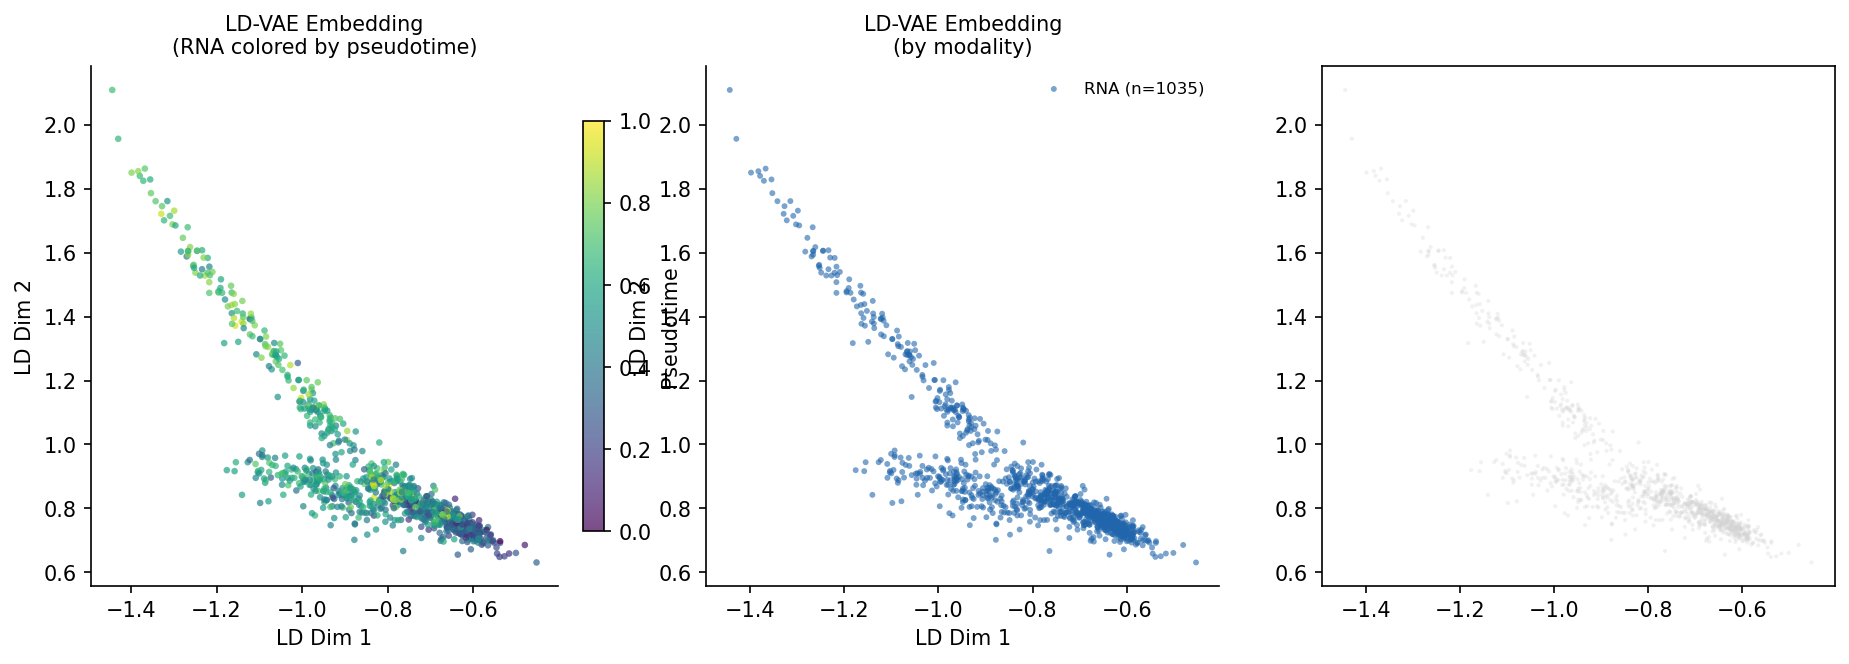

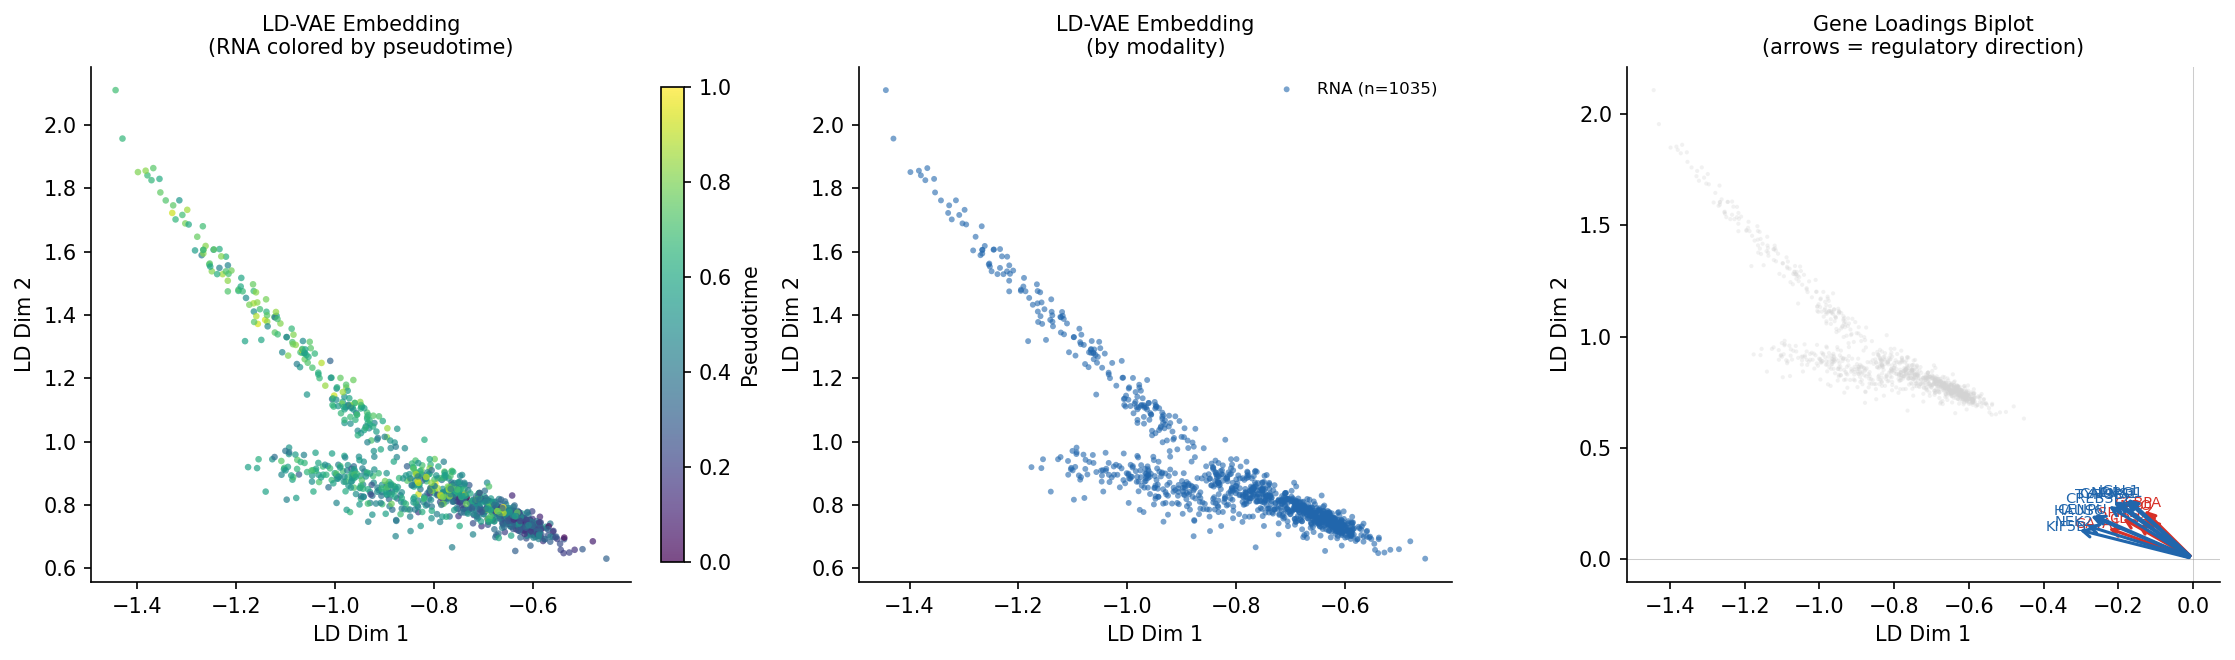

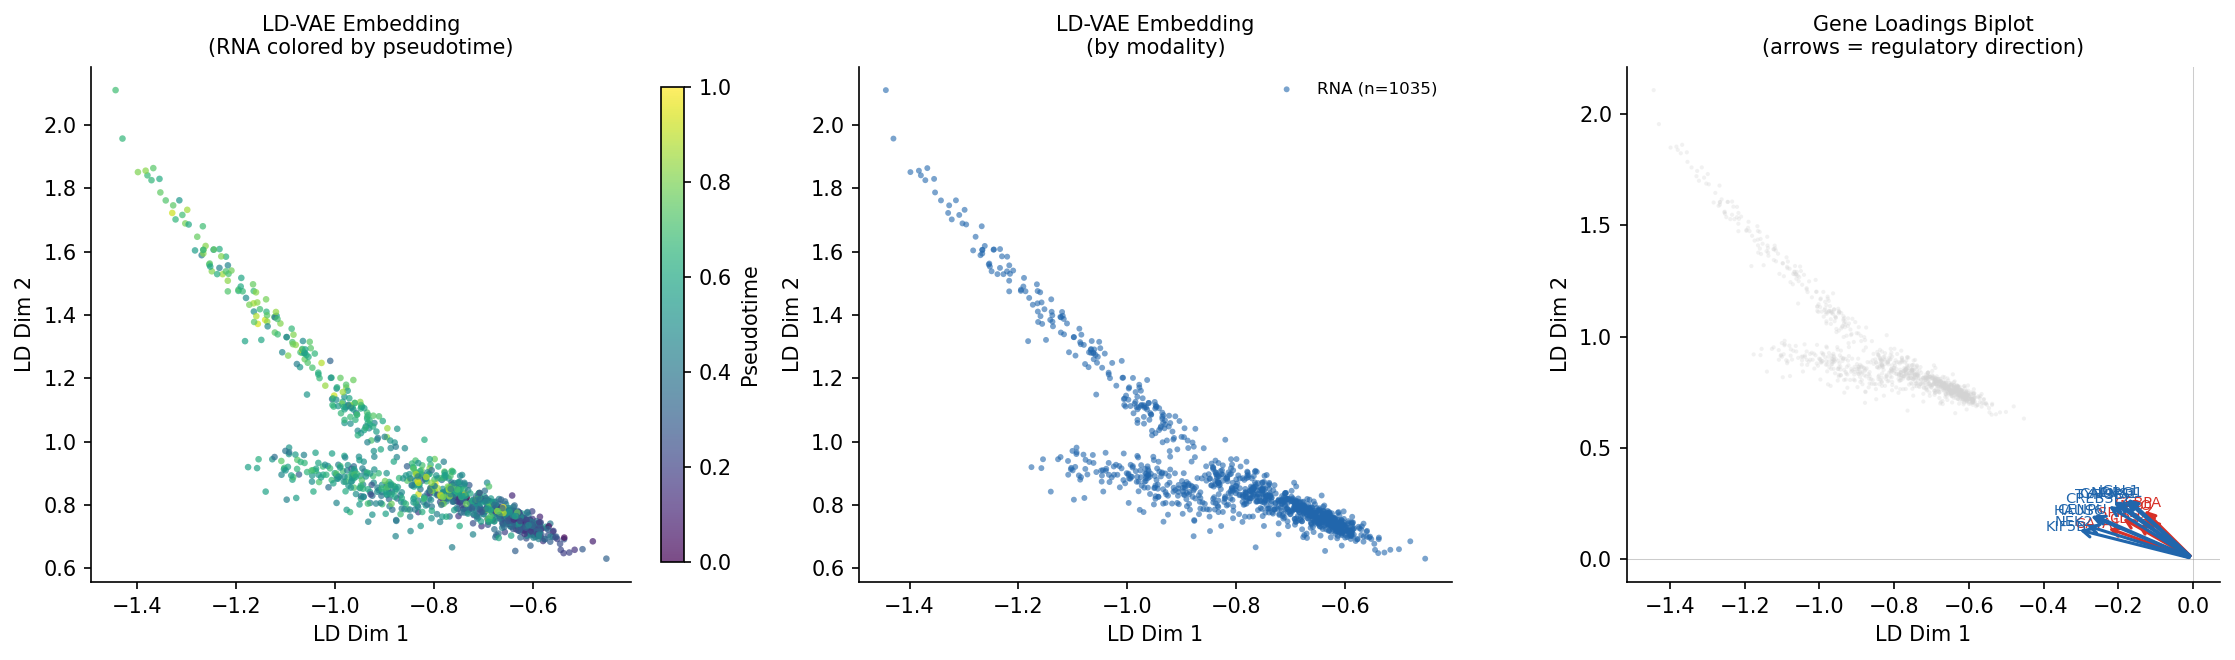

LD-VAE biplot saved: bert_grn_out_61/ld_embedding_biplot.png


In [25]:
%matplotlib inline
plot_ld_embedding(
    z_2d_np, pseudo_norm, gene_loadings, A_genes,
    highlight_genes=['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA'],
    save_path=f"{d}/ld_embedding_biplot.png"
)

In [46]:
# BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
# os.makedirs("uv_leading_fixed", exist_ok=True)

# rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
# gene_names_all = np.array(rna_adata.var_names.astype(str))
# gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
# X_full = as_dense(rna_adata.X).astype(np.float32)

# peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
# motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
# motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

# peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
# peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
# peak_to_idx = {p: i for i, p in enumerate(peaks)}

# genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
# A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# # IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
# A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

# print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

# gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
# tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

# X = X_full[:, gene_idx]      # cells x genes
# X_TF = X_full[:, tf_idx]     # cells x TFs
# sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


In [ ]:
print(f"X shape: {X.shape}")       # Should be (Cells, Thousands_of_Genes)
print(f"X_TF shape: {X_TF.shape}") # Should be (Cells, Hundreds_of_TFs)
print(f"V_dec2 shape: {V_dec2.shape}") # Should be (Cells, 2)

## Step 13: Downstream Analysis Helpers

In [24]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 13  –  Downstream analysis helpers
# ═══════════════════════════════════════════════════════════════════════════
 
def top_tf_targets(A_learned: np.ndarray,
                   A_tfs: np.ndarray,
                   A_genes: np.ndarray,
                   tf_name: str,
                   n: int = 20) -> list[tuple[str, float]]:
    """Return top-n gene targets of a given TF, ranked by |GRN weight|."""
    if tf_name not in A_tfs:
        raise ValueError(f"{tf_name} not in A_tfs")
    t_idx = np.where(A_tfs == tf_name)[0][0]
    col   = A_learned[:, t_idx]           # (G,)
    top   = np.argsort(-np.abs(col))[:n]
    return [(A_genes[i], float(col[i])) for i in top]
 
 
def velocity_umap(X: np.ndarray,
                  V_pred: np.ndarray,
                  n_pca: int = 50) -> tuple[np.ndarray, np.ndarray]:
    """
    Project expression and velocity into a 2-D PCA subspace for
    scVelo-style stream plots.
    Returns (X_2d, V_2d) both (N, 2).
    """
    pca  = PCA(n_components=n_pca, random_state=42)
    X_pc = pca.fit_transform(X)              # (N, 50)
 
    # Project velocity into PC space (delta in PC space)
    V_pc = V_pred @ pca.components_.T        # (N, 50)
 
    # 2-D via second PCA for visualisation
    pca2 = PCA(n_components=2, random_state=42)
    X_2d = pca2.fit_transform(X_pc)
    V_2d = V_pc @ pca2.components_.T
 
    return X_2d, V_2d
 
 
# Example usage:
X_2d, V_2d = velocity_umap(X, V_pred)
np.save("bert_grn_out_61/X_2d.npy", X_2d)
np.save("bert_grn_out_61/V_2d.npy", V_2d)
print("2-D velocity embedding saved.")
 
# Quick sanity check: fraction of cells with positive mean velocity
frac_pos = float(np.mean(V_pred.mean(axis=1) > 0))
print(f"Cells with net positive velocity: {frac_pos:.1%}  "
      f"(expect ~50% for unbiased datasets)")
 
# Top TF targets example (replace with a TF in your dataset)
example_tf = A_tfs[0]
print(f"\nTop 10 targets of {example_tf}:")
for gene, w in top_tf_targets(A_learned, A_tfs, A_genes, example_tf, n=10):
    print(f"  {gene:20s}  weight={w:+.4f}")

2-D velocity embedding saved.
Cells with net positive velocity: 0.0%  (expect ~50% for unbiased datasets)

Top 10 targets of IRF2:


NameError: name 'A_learned' is not defined

Atom usage stats (should NOT all be equal):
  Mean mixing weights per atom: [0.639 0.178 0.142 0.041]
  Std  mixing weights per atom: [0.259 0.174 0.272 0.084]
  Mean entropy: 0.643 / 1.39 max


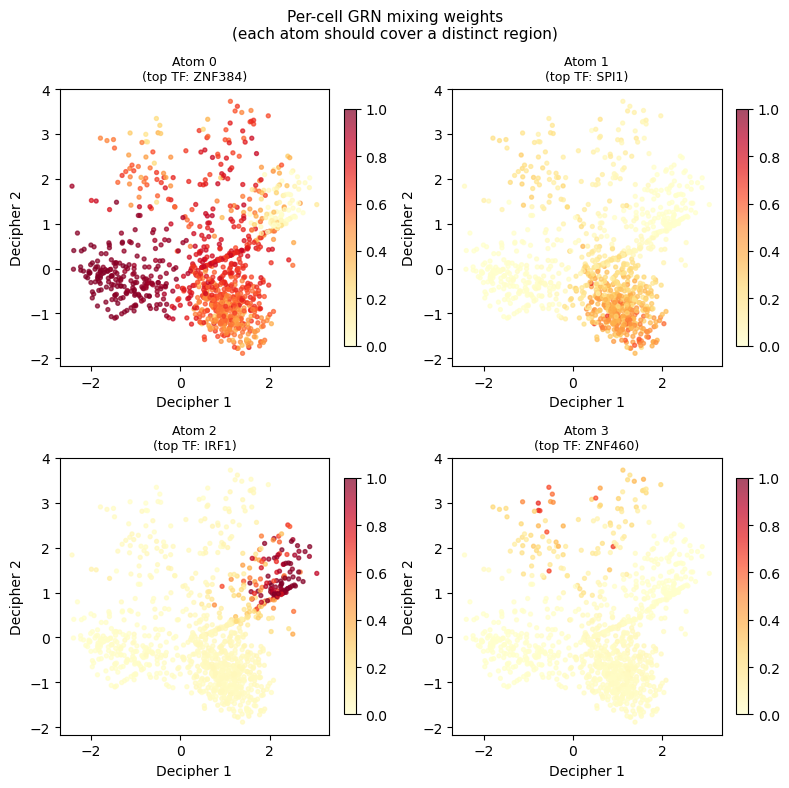

Saved: bert_grn_out_61/atom_weights_spatial.png


In [26]:
%matplotlib inline

grn.eval(); cell_encoder.eval()
with torch.no_grad():
    all_weights = cell_encoder(X_t, temperature=0.1).numpy()   # (N, D)
    all_weights_soft = cell_encoder(X_t, temperature=1.0).numpy()  # softer version
 
# Check: are atoms actually different?
print("Atom usage stats (should NOT all be equal):")
print("  Mean mixing weights per atom:", all_weights.mean(axis=0).round(3))
print("  Std  mixing weights per atom:", all_weights.std(axis=0).round(3))
print("  Mean entropy:", -(all_weights * np.log(all_weights + 1e-8)).sum(axis=1).mean().round(3),
      f"/ {np.log(D_ATOMS):.2f} max")
 
fig, axes = plt.subplots(2, D_ATOMS // 2, figsize=(4 * D_ATOMS // 2, 8))
axes = axes.flatten()
 
for d in range(D_ATOMS):
    ax = axes[d]
    sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1],
                    c=all_weights[:, d], cmap='YlOrRd',
                    s=8, alpha=0.7, vmin=0, vmax=1)
    plt.colorbar(sc, ax=ax, fraction=0.04)
    # Top TF for this atom
    A_atom = grn.A_dict[d].detach().cpu().numpy()   # (G, T)
    top_tf = A_tfs[np.abs(A_atom).sum(axis=0).argmax()]
    ax.set_title(f"Atom {d}\n(top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
 
plt.suptitle("Per-cell GRN mixing weights\n(each atom should cover a distinct region)",
             fontsize=11)
plt.tight_layout()
plt.savefig("bert_grn_out_61/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: bert_grn_out_61/atom_weights_spatial.png")

Atom usage stats (should NOT all be equal):
  Mean mixing weights per atom: [0.478 0.11  0.262 0.15 ]
  Std  mixing weights per atom: [0.163 0.116 0.226 0.104]
  Mean entropy: 1.022 / 1.39 max


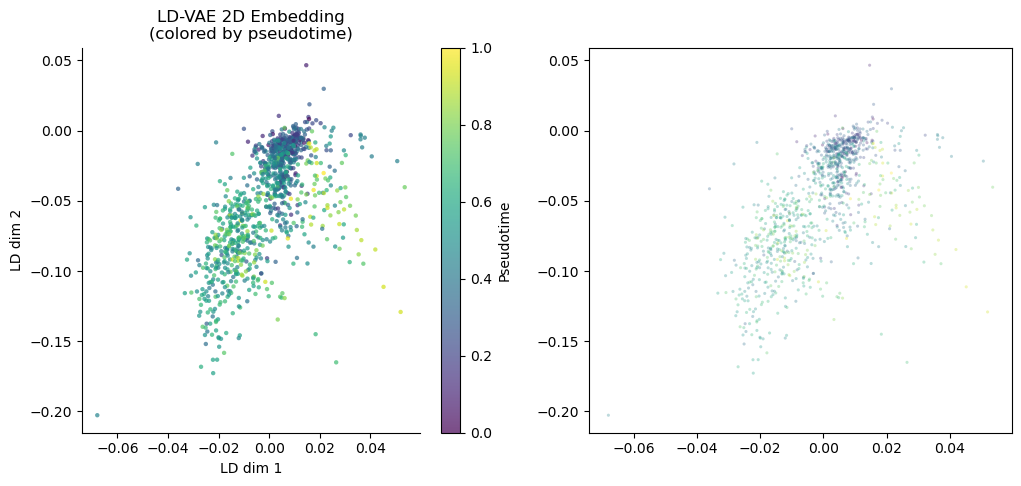

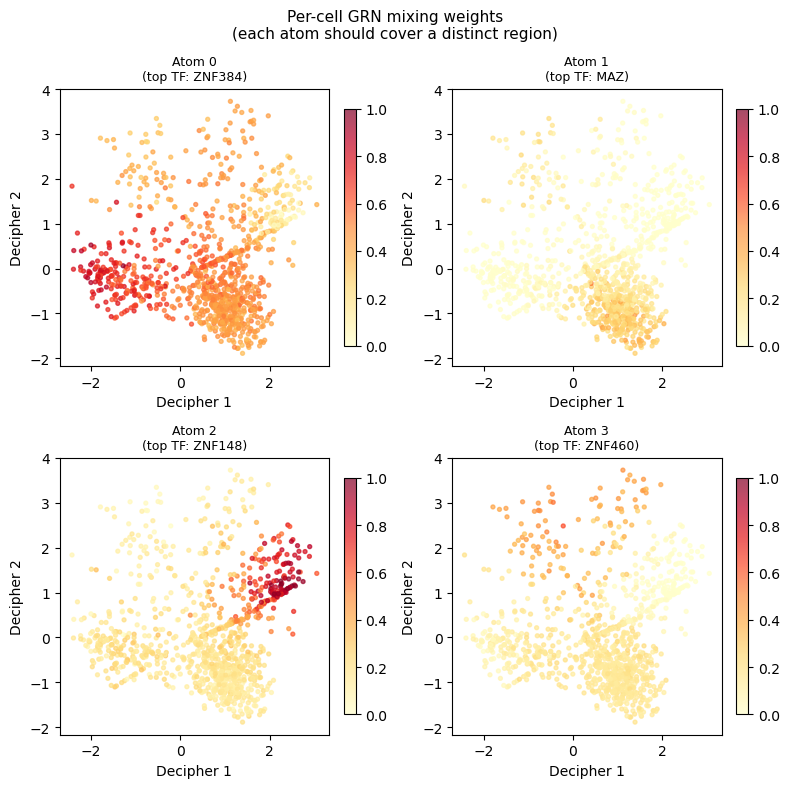

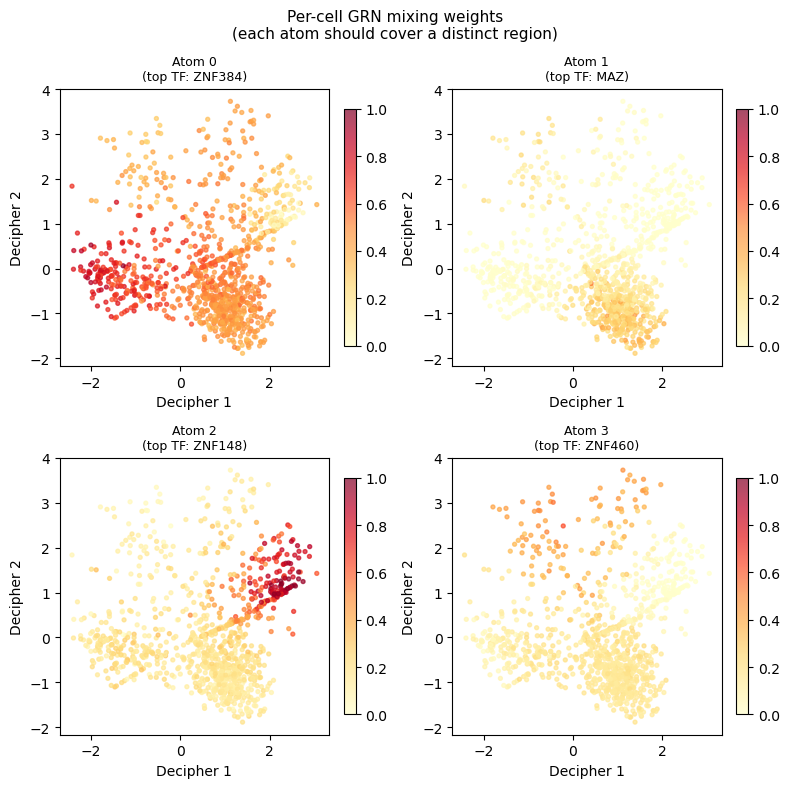

Saved: bert_grn_out_518/atom_weights_spatial.png


In [26]:
%matplotlib inline

grn.eval(); cell_encoder.eval()
with torch.no_grad():
    all_weights = cell_encoder(X_t, temperature=0.1).numpy()   # (N, D)
    all_weights_soft = cell_encoder(X_t, temperature=1.0).numpy()  # softer version
 
# Check: are atoms actually different?
print("Atom usage stats (should NOT all be equal):")
print("  Mean mixing weights per atom:", all_weights.mean(axis=0).round(3))
print("  Std  mixing weights per atom:", all_weights.std(axis=0).round(3))
print("  Mean entropy:", -(all_weights * np.log(all_weights + 1e-8)).sum(axis=1).mean().round(3),
      f"/ {np.log(D_ATOMS):.2f} max")
 
fig, axes = plt.subplots(2, D_ATOMS // 2, figsize=(4 * D_ATOMS // 2, 8))
axes = axes.flatten()
 
for d in range(D_ATOMS):
    ax = axes[d]
    sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1],
                    c=all_weights[:, d], cmap='YlOrRd',
                    s=8, alpha=0.7, vmin=0, vmax=1)
    plt.colorbar(sc, ax=ax, fraction=0.04)
    # Top TF for this atom
    A_atom = grn.A_dict[d].detach().cpu().numpy()   # (G, T)
    top_tf = A_tfs[np.abs(A_atom).sum(axis=0).argmax()]
    ax.set_title(f"Atom {d}\n(top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
 
plt.suptitle("Per-cell GRN mixing weights\n(each atom should cover a distinct region)",
             fontsize=11)
plt.tight_layout()
plt.savefig("bert_grn_out_61/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: bert_grn_out_61/atom_weights_spatial.png")

## Step 8: Velocity visualization

Computing UMAP...


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


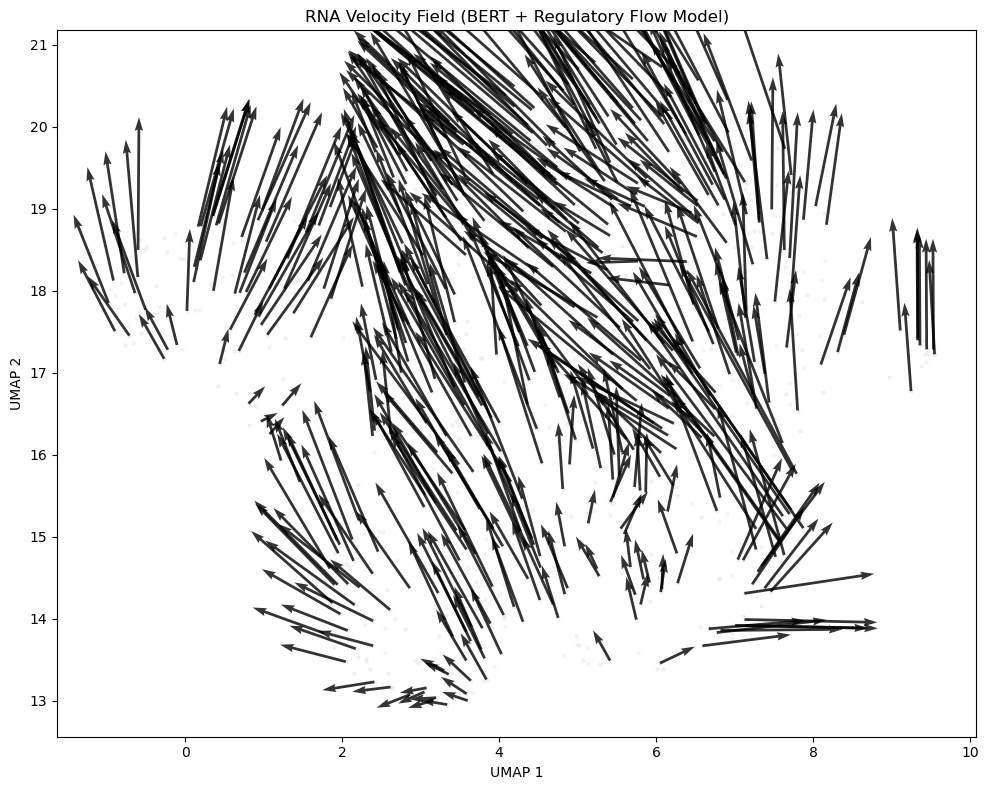

In [27]:
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

%matplotlib inline

# Load data
adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("bert_grn_out_61/V_pred.npy")   # <-- UPDATED NAME
gene_idx = np.load("bert_grn_out_61/gene_idx.npy")

# 3. Align Matrix Space
# Instead of LIGER matching, we just use the indices we used during training
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
X = X_full[:, gene_idx]

# Basic sanity check
assert X.shape == V_pred.shape, f"Shape mismatch: X {X.shape} vs V_pred {V_pred.shape}"

# 4. Generate UMAP Embedding
# We embed based on the same genes the model used for velocity
print("Computing UMAP...")
reducer = UMAP(n_neighbors=15, min_dist=0.3, random_state=42)
X_umap = reducer.fit_transform(X)

# 5. Project Velocity into UMAP Space
# This uses the "displace and transform" method
eps = 0.1  # Small perturbation to stay within UMAP manifold stability
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

# The raw direction in 2D
V_umap_raw = (X_pert_umap - X_umap) / eps

# 6. Smooth the Velocity Field
# Individual cell vectors are often noisy; we average them across neighbors
nn = NearestNeighbors(n_neighbors=25).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# 7. Final Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Background cells
# If you have cell types in adata, you can use: c=adata.obs['cell_type_col'].cat.codes
ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=5, alpha=0.2, c="lightgrey", label="Cells"
)

# Quiver plot (Arrows)
sample = np.random.choice(len(X_umap), 500, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    color="black", scale=20, width=0.003, alpha=0.8
)

ax.set_title("RNA Velocity Field (BERT + Regulatory Flow Model)")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.savefig("velocity_field_final.png", dpi=200)
plt.show()

## Visualize in Decipher Space (not a good visualization)

Performing Tangent Manifold Projection...
Done.

Spearman(pseudotime, |V|): rho=0.101, p=0.0012
(expect weakly negative — early cells move more)
Pseudotime direction agreement: mean cosine = 0.018
Fraction pointing in right direction: 0.503
(expect >0.5 — majority of arrows should point up the pseudotime gradient)


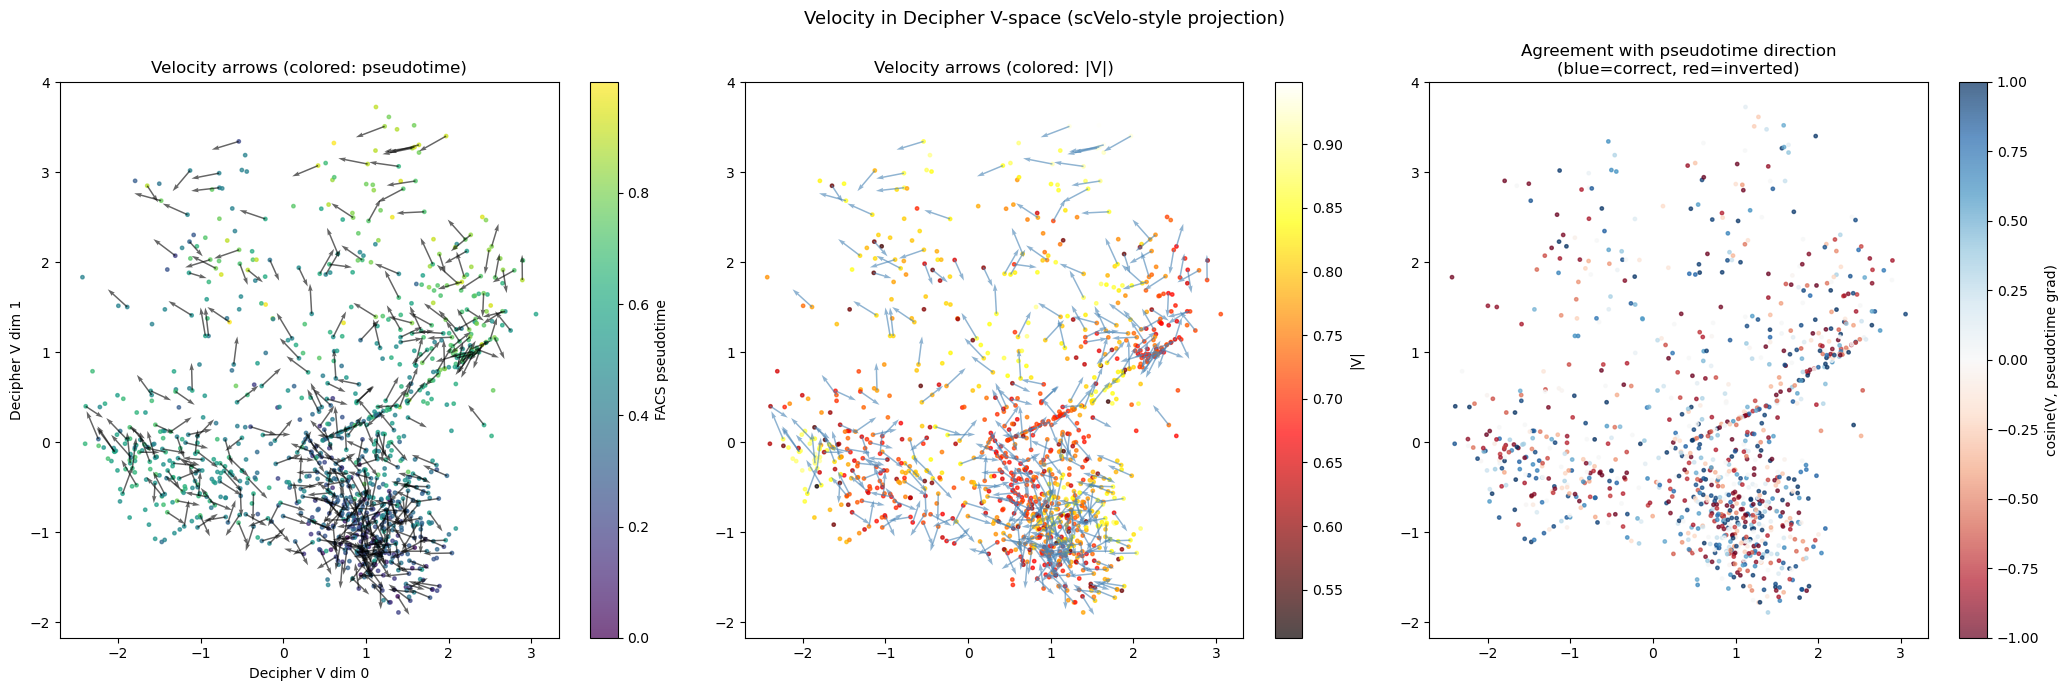


Saved: uv_leading_metrics_improved/velocity_decipher_corrected.png


In [28]:
# ============================================================
# STEP 8: Decipher velocity projection (scVelo-style, correct)
# ============================================================
# Requires:
#   X          : (N, G) raw RNA expression (numpy, float32)
#   V_np       : (N, G) learned gene-space velocity (numpy)
#   rna_adata  : AnnData with obs["facs_pseudotime"]
#   decipher_outputs/decipher_embeddings.npz  with keys "z" and "v"
#     z : (N, 10)  latent z coordinates
#     v : (N, 2)   2-D visualization coordinates
# ============================================================

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

# ------------------------------------------------------------------
# 0. Load Decipher embeddings
# ------------------------------------------------------------------
decipher_data = np.load("decipher_outputs2/decipher_embeddings.npz")
Z_dec   = decipher_data["z"].astype(np.float32)   # (N, 10) — latent space
V_dec2  = decipher_data["v"].astype(np.float32)   # (N, 2)  — visualization space
V_np = V_pred

assert Z_dec.shape[0] == V_np.shape[0] == X.shape[0], \
    f"Cell count mismatch: z={Z_dec.shape[0]}, V={V_np.shape[0]}, X={X.shape[0]}"

N = X.shape[0]

USE_JACOBIAN = False  

if not USE_JACOBIAN:
    print("Performing Tangent Manifold Projection...")
    
    # 1. Get the local PCA structure for every cell
    k_exp = 30
    nn_pca = NearestNeighbors(n_neighbors=k_exp).fit(Z_dec) # Use Decipher space
    _, idx_pca = nn_pca.kneighbors(Z_dec)
    
    V_emb2 = np.zeros((N, 2), dtype=np.float32)
    
    for i in range(N):
        # Find the local 2D basis in the visualization space
        # (How the visualization space 'stretches' locally)
        local_vis = V_dec2[idx_pca[i]] - V_dec2[i] # (K, 2)
        local_gene = X[idx_pca[i]] - X[i]          # (K, G)
        
        # Use SVD to find the relationship between gene-space and vis-space
        # This is a local 'Jacobian' proxy
        # We want to find the 2D vector v_2d that best explains V_gene_i
        # V_gene_i ≈ local_gene @ v_projection
        
        # Solve local least squares: Which 2D direction matches the gene change?
        # This 'unbiases' the neighbor density
        U, S, Vt = np.linalg.svd(local_gene, full_matrices=False)
        # Project predicted velocity into the local gene-basis
        gene_coeffs = V_np[i] @ Vt.T 
        
        # Map those coefficients to the visualization displacements
        V_emb2[i] = np.mean(local_vis * (U @ gene_coeffs)[:, np.newaxis], axis=0)
    
    # Apply a final scaling for visibility
    V_emb2 = V_emb2 / (np.linalg.norm(V_emb2, axis=1, keepdims=True) + 1e-8)
    print("Done.")

k_smooth = 30
nn_vis = NearestNeighbors(n_neighbors=k_smooth + 1).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2)
idx_vis = idx_vis[:, 1:]

# Weighted average: 70% own velocity, 30% neighbor average
V_smooth = 0.7 * V_emb2 + 0.3 * np.array([
    V_emb2[idx_vis[i]].mean(axis=0) for i in range(N)
])

pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo_norm = (pseudo - pseudo.min()) / (pseudo.max() - pseudo.min() + 1e-8)

v_mag = np.linalg.norm(V_smooth, axis=1)
rho, p = spearmanr(pseudo, v_mag)
print(f"\nSpearman(pseudotime, |V|): rho={rho:.3f}, p={p:.4f}")
print("(expect weakly negative — early cells move more)")

# Directionality check: project velocity onto pseudotime gradient
# Positive = velocity points toward increasing pseudotime (correct)
nn_pseudo = NearestNeighbors(n_neighbors=10).fit(V_dec2)
_, idx_ps = nn_pseudo.kneighbors(V_dec2)
idx_ps = idx_ps[:, 1:]

pseudo_grad = np.array([
    V_dec2[idx_ps[i][pseudo[idx_ps[i]] > pseudo[i]]].mean(axis=0) - V_dec2[i]
    if (pseudo[idx_ps[i]] > pseudo[i]).any()
    else np.zeros(2)
    for i in range(N)
])  # (N, 2) — local pseudotime direction in embedding

# Cosine agreement between velocity and pseudotime direction
valid_mask = np.linalg.norm(pseudo_grad, axis=1) > 1e-6
cos_agree = np.sum(
    V_smooth[valid_mask] * pseudo_grad[valid_mask], axis=1
) / (
    np.linalg.norm(V_smooth[valid_mask], axis=1) *
    np.linalg.norm(pseudo_grad[valid_mask], axis=1) + 1e-8
)

print(f"Pseudotime direction agreement: mean cosine = {cos_agree.mean():.3f}")
print(f"Fraction pointing in right direction: {(cos_agree > 0).mean():.3f}")
print("(expect >0.5 — majority of arrows should point up the pseudotime gradient)")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# --- Panel 1: scatter + quiver (colored by pseudotime) ---
ax = axes[0]
sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm,
                cmap="viridis", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(N, min(400, N), replace=False)
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="black"
)
ax.set_title("Velocity arrows (colored: pseudotime)")
ax.set_xlabel("Decipher V dim 0")
ax.set_ylabel("Decipher V dim 1")

# --- Panel 2: colored by velocity magnitude ---
ax = axes[1]
sc2 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=v_mag,
                 cmap="hot", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc2, ax=ax, label="|V|")
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="steelblue"
)
ax.set_title("Velocity arrows (colored: |V|)")

# --- Panel 3: cosine agreement with pseudotime direction ---
ax = axes[2]
cos_full = np.zeros(N)
cos_full[valid_mask] = cos_agree
sc3 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=cos_full,
                 cmap="RdBu", vmin=-1, vmax=1, s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc3, ax=ax, label="cosine(V, pseudotime grad)")
ax.set_title("Agreement with pseudotime direction\n(blue=correct, red=inverted)")

plt.suptitle("Velocity in Decipher V-space (scVelo-style projection)", fontsize=13)
plt.tight_layout()
plt.show()

print("\nSaved: uv_leading_metrics_improved/velocity_decipher_corrected.png")



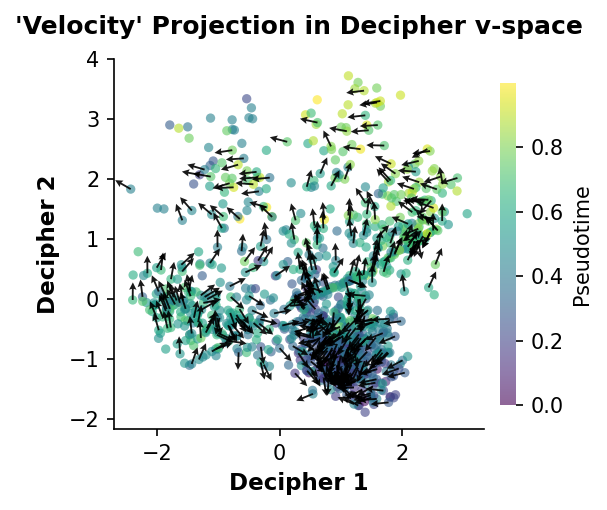

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells 
# Increased s from 3 to 20 for better slide visibility
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,
    cmap="viridis", 
    s=20,               # <--- Increased dot size
    alpha=0.6,          # Slightly lowered alpha to handle overlap
    edgecolors='none', 
    rasterized=True
)

# --- 3. Smooth + Plot Arrows ---

# Subsample points (keep spatial coverage, not random chaos)
n_arrows = min(400, N)
grid_idx = np.random.choice(N, n_arrows, replace=False)

X = V_dec2
V = V_smooth

# --- Local smoothing (THIS is the big fix) ---
k = 15  # neighbors for smoothing
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
_, idx = nbrs.kneighbors(X[grid_idx])

V_avg = V[idx].mean(axis=1)

# --- Normalize BUT keep magnitude scale ---
norm = np.linalg.norm(V_avg, axis=1, keepdims=True)
V_dir = V_avg / (norm + 1e-9)

# rescale so arrows are visible (tune this)
arrow_scale = 0.5 * np.percentile(norm, 90)
V_final = V_dir * arrow_scale

# --- Plot quiver ---
ax.quiver(
    X[grid_idx, 0], X[grid_idx, 1],
    V_final[:, 0], V_final[:, 1],
    color='black',
    alpha=0.9,
    angles='xy',
    scale_units='xy',
    scale=1,          # ↓ smaller scale → LONGER arrows

    width=0.005,        # thinner shaft (makes heads look less dominant)

    headwidth=4,        # ↓ reduce head size
    headlength=4,
    headaxislength=3.5
)

# 4. Clean Labels and Aesthetics
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("'Velocity' Projection in Decipher v-space", fontsize=12, pad=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

## scVelo-style plot - USE THIS PROJECTION

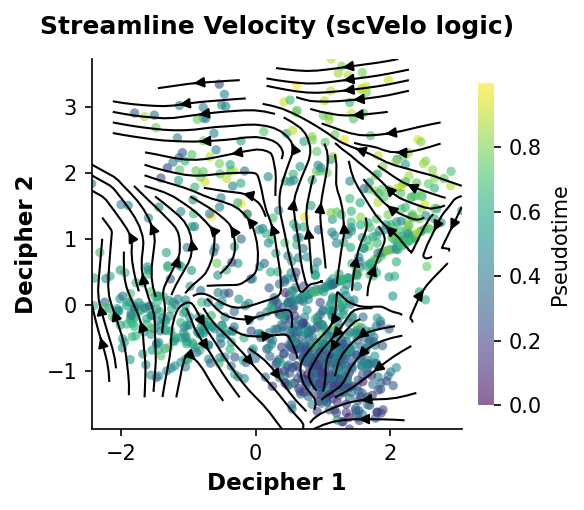

In [30]:
from sklearn.neighbors import NearestNeighbors

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells 
# Increased s from 3 to 20 for better slide visibility
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,
    cmap="viridis", 
    s=20,               # <--- Increased dot size
    alpha=0.6,          # Slightly lowered alpha to handle overlap
    edgecolors='none', 
    rasterized=True
)

# -----------------------------
# 3. scvelo-style STREAM FIELD
# -----------------------------

X_emb = V_dec2
V_emb = V_smooth

from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.sparse import csr_matrix

# -----------------------------
# 1. Grid (keep scvelo density logic)
# -----------------------------
density = 2
grid_n = int(60 * density)

X_emb = V_dec2
V_emb = V_smooth

x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()

x_grid = np.linspace(x_min, x_max, grid_n)
y_grid = np.linspace(y_min, y_max, grid_n)

Xg, Yg = np.meshgrid(x_grid, y_grid)
grid_points = np.c_[Xg.ravel(), Yg.ravel()]

# -----------------------------
# 2. SPARSE sampling (THIS is what you were missing)
# -----------------------------
n_cells = min(3000, len(X_emb))   # scvelo effectively does this via structure
cell_idx = np.random.choice(len(X_emb), n_cells, replace=False)

X_small = X_emb[cell_idx]
V_small = V_emb[cell_idx]

# -----------------------------
# 3. nearest-neighbor projection (but NOT dense averaging)
# -----------------------------
k = 20
nbrs = NearestNeighbors(n_neighbors=k).fit(X_small)
_, idx = nbrs.kneighbors(grid_points)

V_grid = V_small[idx].mean(axis=1)

# -----------------------------
# CELL DENSITY SUPPORT MASK
# (THIS is what scvelo effectively enforces via "mass")
# -----------------------------

# -----------------------------
# CELL SUPPORT MASK (scvelo-like)
# -----------------------------
nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_emb)
dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
dist_to_cells = dist_to_cells.ravel()

support_threshold = np.percentile(dist_to_cells, 40)
support_mask = dist_to_cells < support_threshold

# -----------------------------
# VELOCITY MAGNITUDE MASK
# -----------------------------
speed = np.linalg.norm(V_grid, axis=1)
cutoff_speed = np.percentile(speed, 35)
velocity_mask = speed > cutoff_speed

# -----------------------------
# COMBINED MASK (CRITICAL FIX)
# -----------------------------
final_mask = support_mask & velocity_mask

grid_points_f = grid_points[final_mask]
V_grid_f = V_grid[final_mask]

# -----------------------------
# 5. reproject onto structured grid (IMPORTANT)
# -----------------------------
U = np.zeros(Xg.shape)
W = np.zeros(Yg.shape)

from scipy.spatial import cKDTree
tree = cKDTree(grid_points_f)

_, nn = tree.query(np.c_[Xg.ravel(), Yg.ravel()], k=1)

U = V_grid_f[nn, 0].reshape(Xg.shape)
W = V_grid_f[nn, 1].reshape(Yg.shape)

# ----------------------

grid_dist, _ = nbrs_cells.kneighbors(np.c_[Xg.ravel(), Yg.ravel()])
grid_mask = (grid_dist.ravel() < support_threshold)

U_flat = U.ravel()
W_flat = W.ravel()

U_flat[~grid_mask] = 0
W_flat[~grid_mask] = 0

U = U_flat.reshape(Xg.shape)
W = W_flat.reshape(Yg.shape)

# -----------------------------
# 6. STRONG smoothing (this is what stabilizes scvelo plots)
# -----------------------------
U = gaussian_filter(U, sigma=1.2)
W = gaussian_filter(W, sigma=1.2)

# -----------------------------
# 7. FINAL STREAMPLOT (scvelo-like sparsity emerges here)
# -----------------------------
ax.streamplot(
    Xg, Yg,
    U, W,
    color="black",
    density=1.2,        # LOWER than before = key fix
    linewidth=1,
    arrowsize=1,
    arrowstyle='-|>',
    minlength=0.2,
    integration_direction='both',
    zorder=3
)

# Aesthetics and Labels
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (scVelo logic)", fontsize=12, pad=12, fontweight='bold')

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Re-position colorbar for clean aesthetics
cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

Cell type counts:
 gate_celltype
Other    791
HSC       98
GMP       77
MEP       37
MLP       16
MPP       12
CMP        4
Name: count, dtype: int64


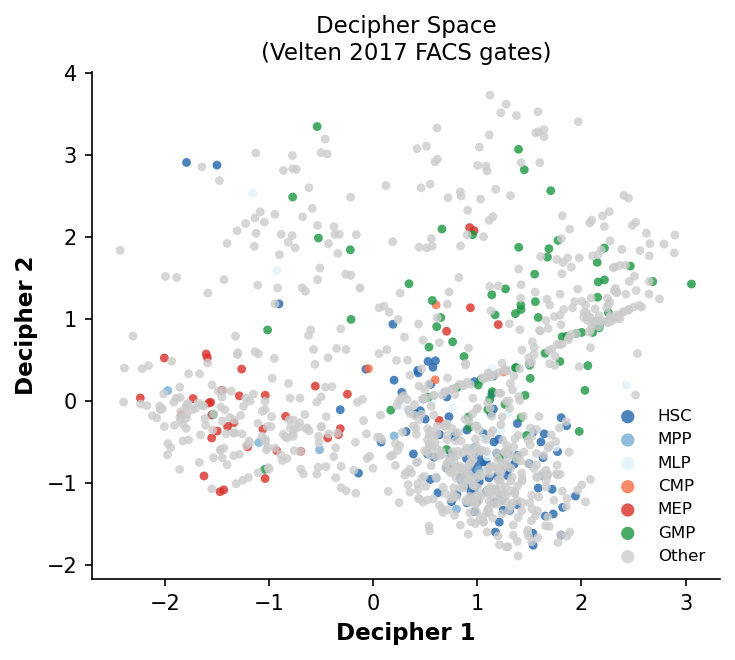

Plotting 8/8 markers: ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA', 'GATA2', 'LMO2']


IndexError: index 8971 is out of bounds for axis 1 with size 2

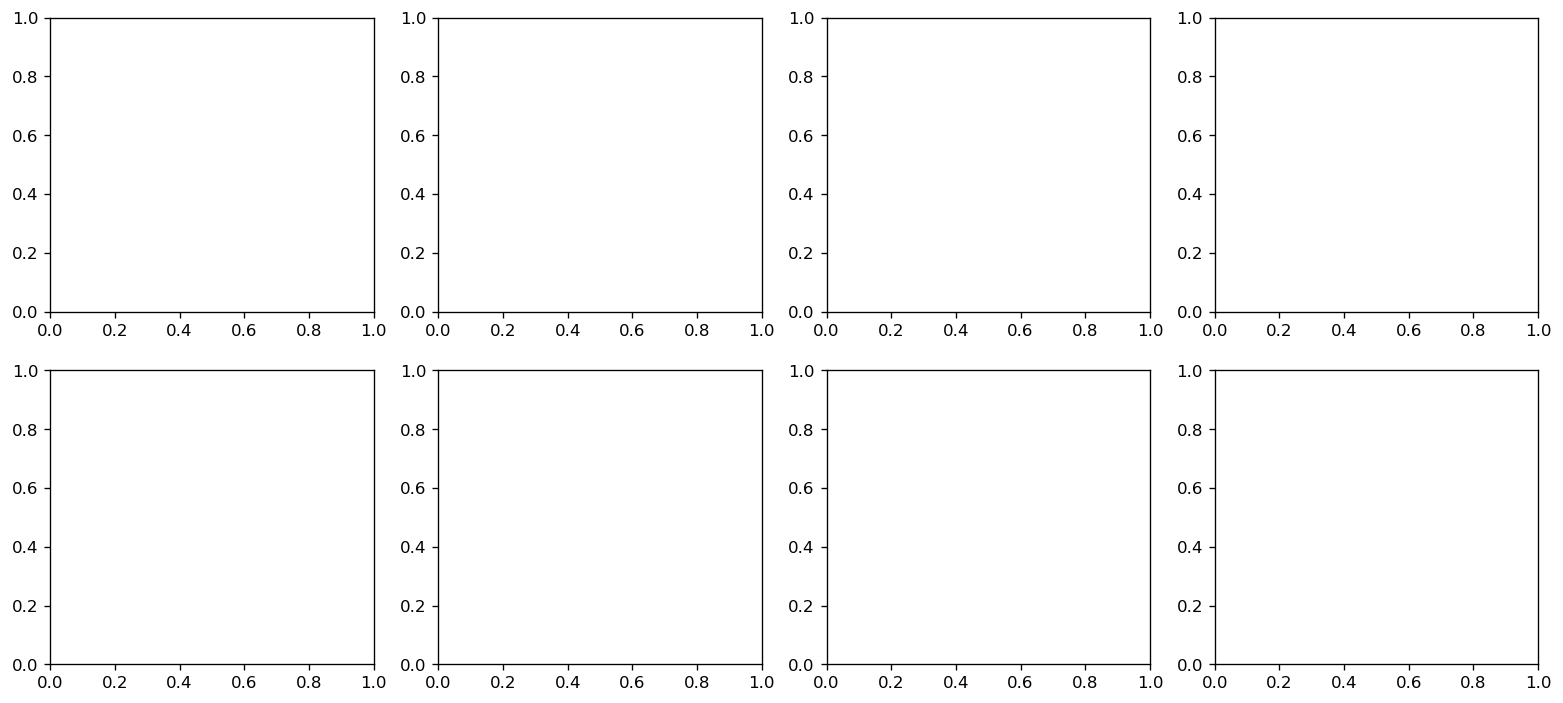

In [31]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL TYPE ANNOTATION: Velten 2017 FACS-based gating + marker expression
# ═══════════════════════════════════════════════════════════════════════════
#
# Velten 2017 (doi: 10.1038/ncb3493) immunophenotyping hierarchy:
#   HSC:  Lin- CD34+ CD38- CD90+ CD45RA-
#   MPP:  Lin- CD34+ CD38- CD90- CD45RA-
#   MLP:  Lin- CD34+ CD38- CD90- CD45RA+
#   CMP:  Lin- CD34+ CD38+ CD135+ CD45RA-
#   MEP:  Lin- CD34+ CD38+ CD135- CD45RA-
#   GMP:  Lin- CD34+ CD38+ CD135+/- CD45RA+
#
# Thresholds use median-split as a simple, data-adaptive gate.
# (You can also use the raw FACS values for continuous coloring.)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

obs = rna_adata.obs.copy()

# ── Helper: median gate (returns bool array) ─────────────────────────────
def gate(col, above=True):
    med = obs[col].median()
    return (obs[col] > med) if above else (obs[col] <= med)

# ── Gating hierarchy (order matters — assign to first matching gate) ─────
lin_neg   = gate('facs_lin',   above=False)
cd34_pos  = gate('facs_cd34',  above=True)
cd38_neg  = gate('facs_cd38',  above=False)
cd38_pos  = gate('facs_cd38',  above=True)
cd90_pos  = gate('facs_cd90',  above=True)
cd90_neg  = gate('facs_cd90',  above=False)
cd135_pos = gate('facs_cd135', above=True)
cd135_neg = gate('facs_cd135', above=False)
cd45ra_pos = gate('facs_cd45ra', above=True)
cd45ra_neg = gate('facs_cd45ra', above=False)

cell_types = np.full(len(obs), 'Other', dtype=object)

# Assign in order (last assignment wins for overlapping gates)
cell_types[lin_neg & cd34_pos & cd38_pos & cd45ra_pos]              = 'GMP'
cell_types[lin_neg & cd34_pos & cd38_pos & cd135_neg & cd45ra_neg]  = 'MEP'
cell_types[lin_neg & cd34_pos & cd38_pos & cd135_pos & cd45ra_neg]  = 'CMP'
cell_types[lin_neg & cd34_pos & cd38_neg & cd90_neg & cd45ra_pos]   = 'MLP'
cell_types[lin_neg & cd34_pos & cd38_neg & cd90_neg & cd45ra_neg]   = 'MPP'
cell_types[lin_neg & cd34_pos & cd38_neg & cd90_pos]                = 'HSC'

rna_adata.obs['gate_celltype'] = cell_types
print("Cell type counts:\n", rna_adata.obs['gate_celltype'].value_counts())

# ── Color palette (matches Velten 2017 figure conventions) ───────────────
CT_COLORS = {
    'HSC': '#2166ac',   # dark blue
    'MPP': '#74add1',   # light blue
    'MLP': '#e0f3f8',   # pale cyan
    'CMP': '#f46d43',   # orange
    'MEP': '#d73027',   # red
    'GMP': '#1a9641',   # green
    'Other': '#cccccc', # grey
}

# ── Figure 1: Decipher space colored by gate cell type ───────────────────
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

for ct, color in CT_COLORS.items():
    mask = cell_types == ct
    if mask.sum() == 0:
        continue
    ax.scatter(V_dec2[mask, 0], V_dec2[mask, 1],
               c=color, s=18, alpha=0.8, label=ct, edgecolors='none', rasterized=True)

ax.set_xlabel('Decipher 1', fontsize=11, fontweight='bold')
ax.set_ylabel('Decipher 2', fontsize=11, fontweight='bold')
ax.set_title('Decipher Space\n(Velten 2017 FACS gates)', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='best', markerscale=1.5, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig('bert_grn_out_61/decipher_celltype_facs.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure 2: Marker gene expression in Decipher space ───────────────────
MARKERS_TO_PLOT = ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA', 'GATA2', 'LMO2']

# Get expression for markers that exist in A_genes
available_markers = [g for g in MARKERS_TO_PLOT if g in sub_g2i]
print(f"Plotting {len(available_markers)}/{len(MARKERS_TO_PLOT)} markers: {available_markers}")

n_cols = 4
n_rows = int(np.ceil(len(available_markers) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows), dpi=120)
axes = np.array(axes).flatten()

for i, gene in enumerate(available_markers):
    ax = axes[i]
    g_idx = sub_g2i[gene]
    expr  = X[:, g_idx]   # raw expression for this gene
    
    # Log-normalize for display
    expr_log = np.log1p(expr)
    
    vmax = np.percentile(expr_log, 98)  # clip outliers
    sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1],
                    c=expr_log, cmap='Reds',
                    s=10, alpha=0.7, vmin=0, vmax=vmax,
                    edgecolors='none', rasterized=True)
    plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
    ax.set_title(gene, fontsize=11, fontweight='bold')
    ax.set_xlabel('Decipher 1', fontsize=9)
    ax.set_ylabel('Decipher 2', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide unused subplots
for j in range(len(available_markers), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Marker Gene Expression in Decipher Space', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('bert_grn_out_61/decipher_markers.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure 3: Velocity streamplot overlaid on cell types ─────────────────
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

for ct, color in CT_COLORS.items():
    mask = cell_types == ct
    if mask.sum() == 0:
        continue
    ax.scatter(V_dec2[mask, 0], V_dec2[mask, 1],
               c=color, s=15, alpha=0.6, label=ct, edgecolors='none', rasterized=True)

# Streamplot using the same logic as Cell 26
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

density  = 2
grid_n   = int(60 * density)
x_min, x_max = V_dec2[:, 0].min(), V_dec2[:, 0].max()
y_min, y_max = V_dec2[:, 1].min(), V_dec2[:, 1].max()
Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                      np.linspace(y_min, y_max, grid_n))
grid_pts = np.c_[Xg.ravel(), Yg.ravel()]

nbrs = NearestNeighbors(n_neighbors=20).fit(V_dec2)
_, idx_g = nbrs.kneighbors(grid_pts)
V_grid = V_smooth[idx_g].mean(axis=1)

nbrs_c = NearestNeighbors(n_neighbors=1).fit(V_dec2)
dist_c, _ = nbrs_c.kneighbors(grid_pts)
support = dist_c.ravel() < np.percentile(dist_c, 40)
speed_g = np.linalg.norm(V_grid, axis=1)
final_m = support & (speed_g > np.percentile(speed_g, 35))

tree = cKDTree(grid_pts[final_m])
_, nn = tree.query(grid_pts, k=1)
U = V_grid[final_m][nn, 0].reshape(Xg.shape)
W_v = V_grid[final_m][nn, 1].reshape(Yg.shape)

# Zero out outside support
gd, _ = nbrs_c.kneighbors(grid_pts)
gm = gd.ravel() < np.percentile(dist_c, 40)
U.ravel()[~gm] = 0; W_v.ravel()[~gm] = 0

U = gaussian_filter(U, sigma=1.2)
W_v = gaussian_filter(W_v, sigma=1.2)

ax.streamplot(Xg, Yg, U, W_v, color='black', density=1.0,
              linewidth=0.8, arrowsize=0.8, arrowstyle='-|>',
              minlength=0.2, integration_direction='both', zorder=3)

ax.set_xlabel('Decipher 1', fontsize=11, fontweight='bold')
ax.set_ylabel('Decipher 2', fontsize=11, fontweight='bold')
ax.set_title('Velocity + Cell Types', fontsize=11)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(loc='best', markerscale=1.5, fontsize=8, frameon=False, ncol=2)
plt.tight_layout()
plt.savefig('bert_grn_out_61/velocity_celltype_overlay.png', dpi=200, bbox_inches='tight')
plt.show()

--- Step 1: Clustering cells in Decipher space ---

--- Step 2: Average marker expression per cluster ---
                       CD34          MPO          LYZ       GATA1       SPI1  \
leiden_clusters                                                                
0                102.017441  3942.348877  1445.569824    3.854651  66.633720   
1                320.385620     0.464052    21.875816    4.869281  30.555555   
2                245.791367     2.014389    24.237410  272.705048  31.043165   
3                385.435181     4.037037     7.194445    0.064815  43.962963   
4                336.679260   337.566040    27.113207   10.500000  57.396225   
5                292.076202     0.171429    21.895239    0.371429  29.390476   
6                107.520409     2.693877    25.704082  312.908173   5.969388   
7                150.083328     7.716667     5.533333   14.533334  15.133333   
8                 41.918365    70.938774   163.795914   15.306123  22.714285   
9             

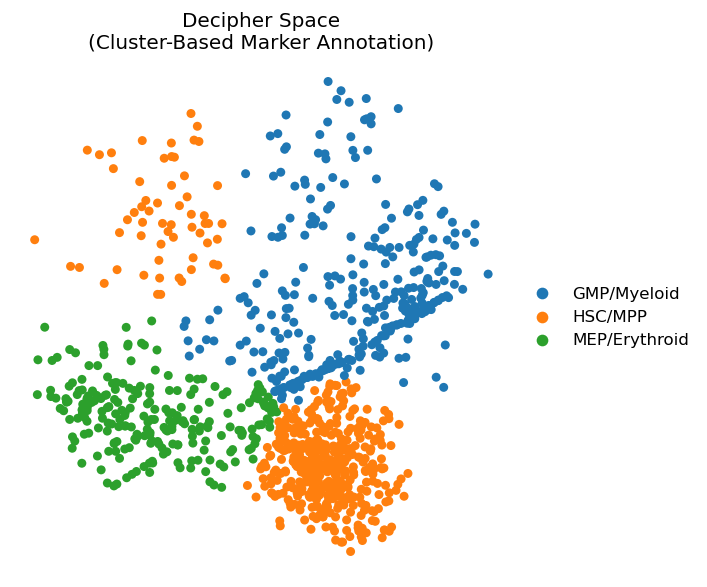

In [31]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'X_diffmap' in rna_adata.obsm:
    del rna_adata.obsm['X_diffmap']

if 'diffmap_evals' in rna_adata.uns:
    del rna_adata.uns['diffmap_evals']

# 1. Inject your Decipher coordinates into the AnnData object for Scanpy processing
rna_adata.obsm['X_decipher'] = V_dec2

# 2. Build the neighborhood graph and run Leiden clustering based on Decipher coordinates
print("--- Step 1: Clustering cells in Decipher space ---")
sc.pp.neighbors(rna_adata, use_rep='X_decipher', n_neighbors=15)
# Adjust resolution if you want more clusters (higher value) or fewer clusters (lower value)
sc.tl.leiden(rna_adata, resolution=0.4, key_added='leiden_clusters') 

# 3. Compute the average expression of your markers per cluster to see who is who
markers = ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA', 'GATA2', 'LMO2']
valid_markers = [g for g in markers if g in rna_adata.var_names]

print("\n--- Step 2: Average marker expression per cluster ---")
obs_df = sc.get.obs_df(rna_adata, keys=['leiden_clusters'] + valid_markers)
mean_expr_matrix = obs_df.groupby('leiden_clusters').mean()
print(mean_expr_matrix)

# 4. Define your cluster-to-celltype mapping
# ⚠️ ACTION REQUIRED: Look at the printed matrix above and assign names based on these rules:
#   - High CD34, low everything else -> 'HSC/MPP'
#   - High GATA1, GATA2, LMO2        -> 'MEP/Erythroid'
#   - High MPO, LYZ, SPI1, CEBPA      -> 'GMP/Myeloid'
#   - Intermediate profiles           -> 'CMP' or 'MLP'
cluster_mapping = {
    '0': 'GMP/Myeloid',
    '1': 'HSC/MPP',
    '2': 'MEP/Erythroid',
    '3': 'HSC/MPP',
    '4': 'GMP/Myeloid',
    '5': 'HSC/MPP',
    '6': 'MEP/Erythroid',
    '7': 'HSC/MPP',
    '8': 'GMP/Myeloid',
    '9': 'HSC/MPP'
    # Add/modify numbers here based on how many clusters your data generates!
}

# 5. Apply the mapping to create your new cell type column
rna_adata.obs['cluster_celltype'] = rna_adata.obs['leiden_clusters'].map(cluster_mapping).fillna('Other')

print("\n--- Step 3: New cluster-based cell type counts ---")
print(rna_adata.obs['cluster_celltype'].value_counts())

# 6. Visualize your new cluster annotations on the Decipher embedding
print("\n--- Step 4: Generating verification plot ---")
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
sc.pl.embedding(
    rna_adata, 
    basis='X_decipher', 
    color='cluster_celltype', 
    ax=ax, 
    show=False,
    frameon=False,
    title='Decipher Space\n(Cluster-Based Marker Annotation)'
)
plt.tight_layout()
plt.show()

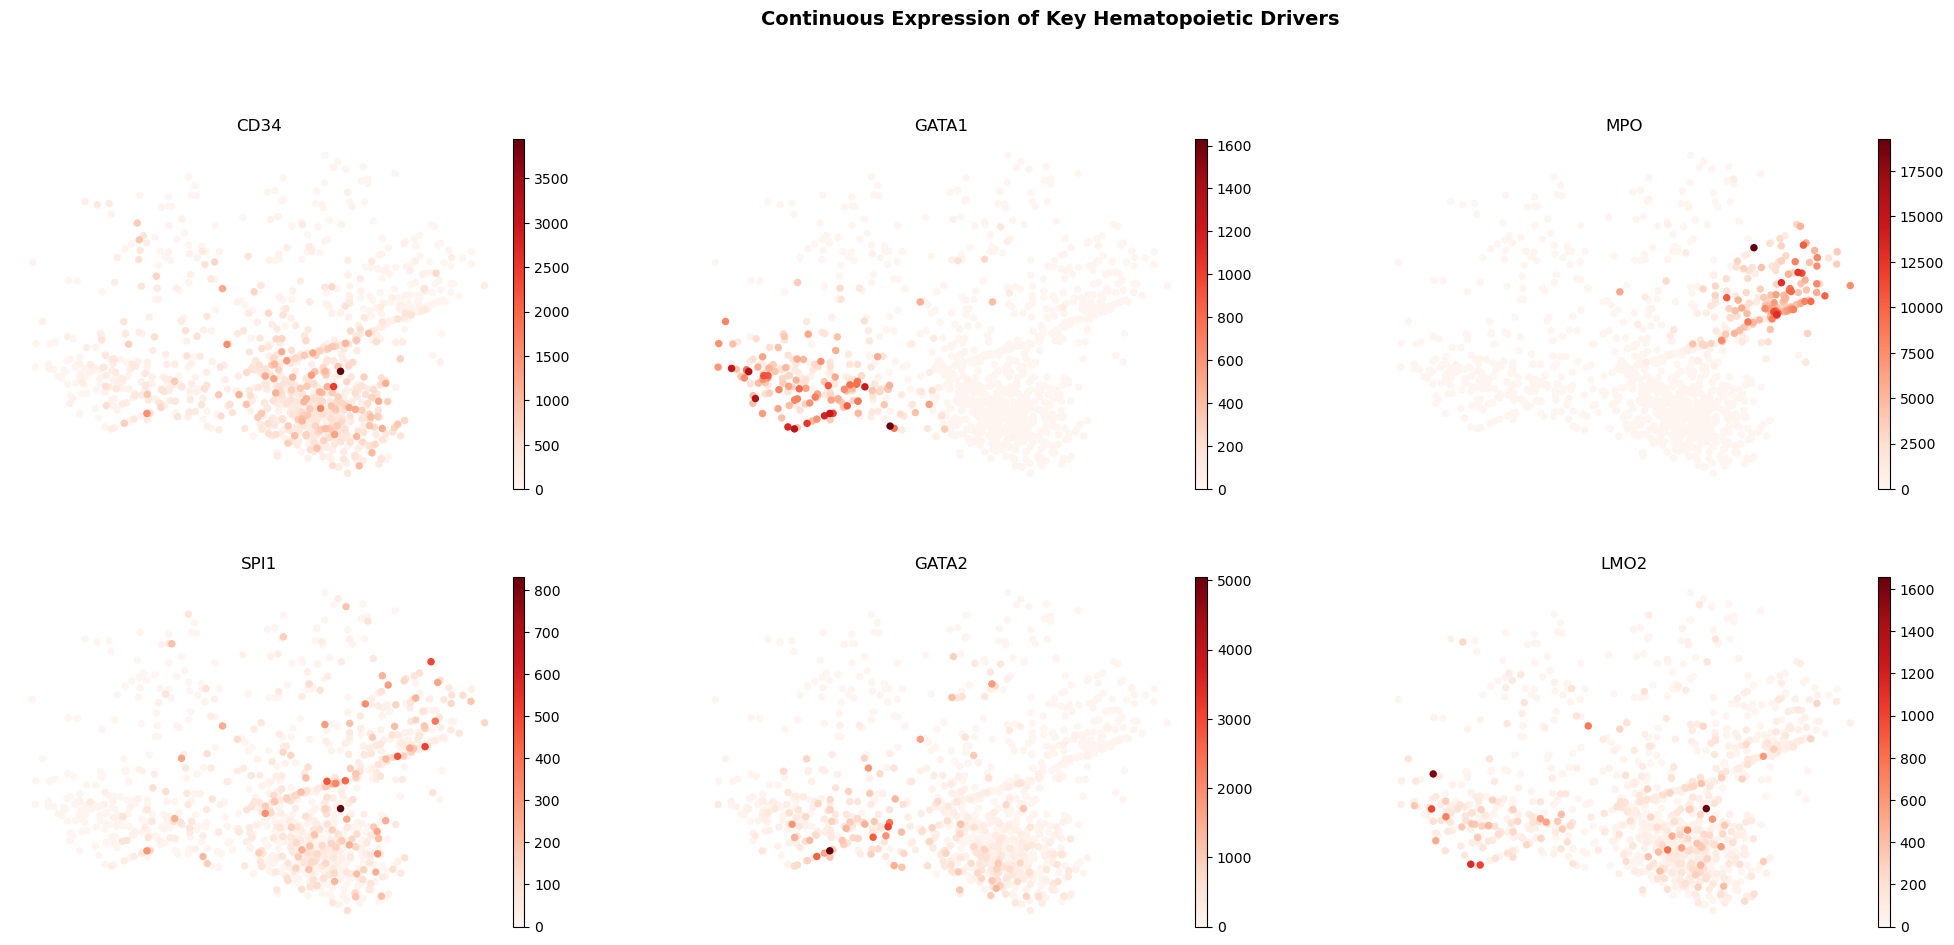

In [32]:
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Define the specific key markers and TFs you want to view continuously
key_genes = ['CD34', 'GATA1', 'MPO', 'SPI1', 'GATA2', 'LMO2']

# Filter to make sure they exist in your dataset object
plot_genes = [g for g in key_genes if g in rna_adata.var_names]

# 2. Plot continuous expression maps across your Decipher space
fig = sc.pl.embedding(
    rna_adata,
    basis='X_decipher',
    color=plot_genes,
    cmap='Reds',          # Red indicates high expression; light grey is low
    frameon=False,
    ncols=3,              # Arranges plots neatly in a 3-column grid
    wspace=0.25,
    hspace=0.25,
    show=False,
    return_fig=True
)

# 3. Polish and render
plt.suptitle('Continuous Expression of Key Hematopoietic Drivers', fontsize=14, y=1.02, fontweight='bold')
plt.show()

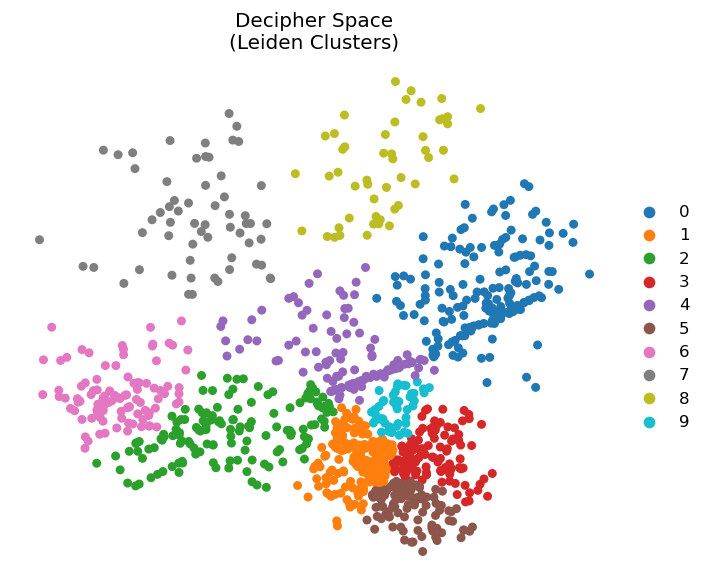

In [34]:
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
sc.pl.embedding(
    rna_adata, 
    basis='X_decipher', 
    color='leiden_clusters', 
    ax=ax, 
    show=False,
    frameon=False,
    title='Decipher Space\n(Leiden Clusters)'
)
plt.tight_layout()
plt.show()

--- Step 1: Clustering cells in Decipher space ---

--- Step 2: Average marker expression per cluster ---
                       CD34          MPO          LYZ       SPI1       CEBPA  \
leiden_clusters                                                                
0                102.017441  3942.348877  1445.569824  66.633720  101.023254   
1                320.385620     0.464052    21.875816  30.555555    1.084967   
2                245.791367     2.014389    24.237410  31.043165    1.503597   
3                385.435181     4.037037     7.194445  43.962963   14.620370   
4                336.679260   337.566040    27.113207  57.396225   29.575472   
5                292.076202     0.171429    21.895239  29.390476    3.333333   
6                107.520409     2.693877    25.704082   5.969388    1.653061   
7                150.083328     7.716667     5.533333  15.133333    4.233333   
8                 41.918365    70.938774   163.795914  22.714285   43.775509   
9             

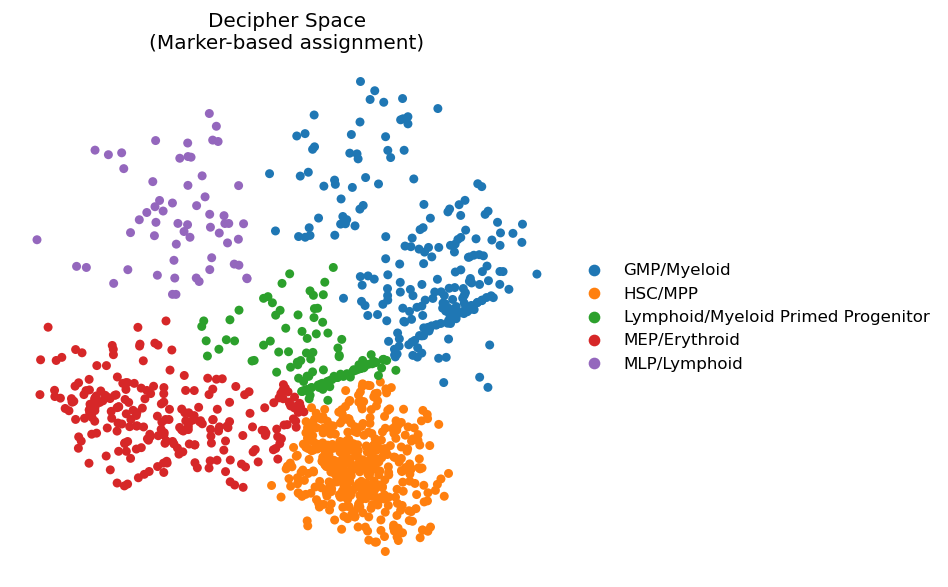

In [37]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'X_diffmap' in rna_adata.obsm:
    del rna_adata.obsm['X_diffmap']

if 'diffmap_evals' in rna_adata.uns:
    del rna_adata.uns['diffmap_evals']

# 1. Inject your Decipher coordinates into the AnnData object for Scanpy processing
rna_adata.obsm['X_decipher'] = V_dec2

# 2. Build the neighborhood graph and run Leiden clustering based on Decipher coordinates
print("--- Step 1: Clustering cells in Decipher space ---")
sc.pp.neighbors(rna_adata, use_rep='X_decipher', n_neighbors=15)
# Adjust resolution if you want more clusters (higher value) or fewer clusters (lower value)
sc.tl.leiden(rna_adata, resolution=0.4, key_added='leiden_clusters') 

# 3. Compute the average expression of your markers per cluster (NOW INCLUDING LYMPHOID)
# Added: IL7R (classic lymphoid receptor), DNTT & EBF1 (lymphoid TFs), MME (CD10)
markers = [
    'CD34',                                     # Progenitor
    'MPO', 'LYZ', 'SPI1', 'CEBPA',              # Myeloid
    'GATA1', 'GATA2', 'LMO2',                   # Erythroid/Megakaryocyte
    'IL7R', 'DNTT', 'EBF1', 'MME'               # Lymphoid (New)
]
valid_markers = [g for g in markers if g in rna_adata.var_names]

print("\n--- Step 2: Average marker expression per cluster ---")
obs_df = sc.get.obs_df(rna_adata, keys=['leiden_clusters'] + valid_markers)
mean_expr_matrix = obs_df.groupby('leiden_clusters').mean()
print(mean_expr_matrix)


# 4. Define your cluster-to-celltype mapping
# ⚠️ ACTION REQUIRED: Look at the printed matrix above and assign names based on these rules:
#   - High CD34, low everything else                     -> 'HSC/MPP'
#   - High GATA1, GATA2, LMO2                             -> 'MEP/Erythroid'
#   - High MPO, LYZ, SPI1, CEBPA                          -> 'GMP/Myeloid'
#   - Moderate/High CD34 + High IL7R, DNTT, EBF1, or MME  -> 'MLP/Lymphoid'  <-- CHECK CLUSTER 7 HERE!
#   - Intermediate Myeloid/Erythroid (low lymphoid)       -> 'CMP'
cluster_mapping = {
    '0': 'GMP/Myeloid',
    '1': 'HSC/MPP',
    '2': 'MEP/Erythroid',
    '3': 'HSC/MPP',
    '4': 'Lymphoid/Myeloid Primed Progenitor',
    '5': 'HSC/MPP',
    '6': 'MEP/Erythroid',
    '7': 'MLP/Lymphoid',
    '8': 'GMP/Myeloid',
    '9': 'HSC/MPP'
    # Add/modify numbers here based on how many clusters your data generates!
}

# 5. Apply the mapping to create your new cell type column
rna_adata.obs['cluster_celltype'] = rna_adata.obs['leiden_clusters'].map(cluster_mapping).fillna('Other')

print("\n--- Step 3: New cluster-based cell type counts ---")
print(rna_adata.obs['cluster_celltype'].value_counts())

# 6. Visualize your new cluster annotations on the Decipher embedding
print("\n--- Step 4: Generating verification plot ---")
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
sc.pl.embedding(
    rna_adata, 
    basis='X_decipher', 
    color='cluster_celltype', 
    ax=ax, 
    show=False,
    frameon=False,
    title='Decipher Space\n(Marker-based assignment)'
)
plt.tight_layout()
plt.show()

--- Step 1: Clustering cells in Decipher space ---

--- Step 2: Average marker expression per cluster ---
                       CD34          MPO          LYZ       SPI1       CEBPA  \
leiden_clusters                                                                
0                102.017441  3942.348877  1445.569824  66.633720  101.023254   
1                320.385620     0.464052    21.875816  30.555555    1.084967   
2                245.791367     2.014389    24.237410  31.043165    1.503597   
3                385.435181     4.037037     7.194445  43.962963   14.620370   
4                336.679260   337.566040    27.113207  57.396225   29.575472   
5                292.076202     0.171429    21.895239  29.390476    3.333333   
6                107.520409     2.693877    25.704082   5.969388    1.653061   
7                150.083328     7.716667     5.533333  15.133333    4.233333   
8                 41.918365    70.938774   163.795914  22.714285   43.775509   
9             

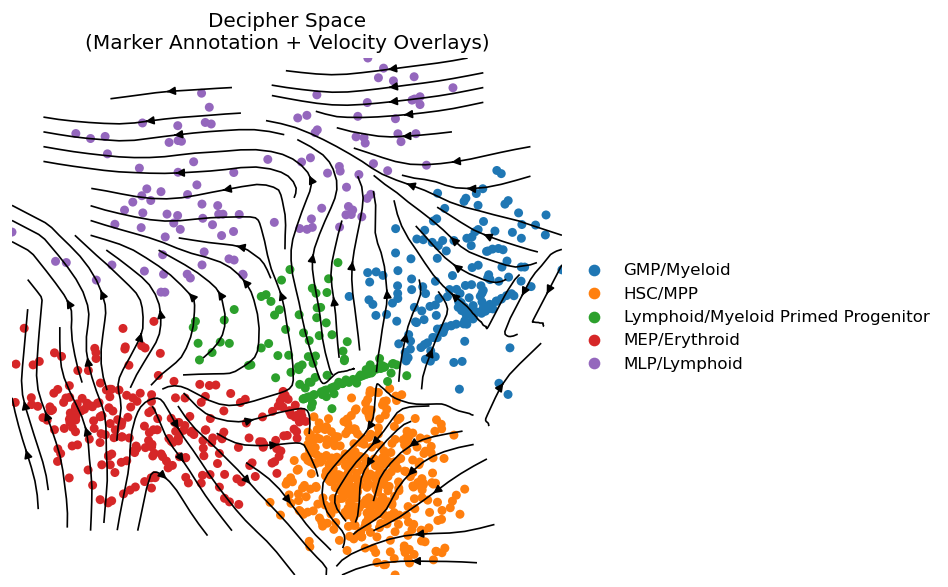

In [38]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

if 'X_diffmap' in rna_adata.obsm:
    del rna_adata.obsm['X_diffmap']

if 'diffmap_evals' in rna_adata.uns:
    del rna_adata.uns['diffmap_evals']

# 1. Inject your Decipher coordinates into the AnnData object for Scanpy processing
rna_adata.obsm['X_decipher'] = V_dec2

# 2. Build the neighborhood graph and run Leiden clustering based on Decipher coordinates
print("--- Step 1: Clustering cells in Decipher space ---")
sc.pp.neighbors(rna_adata, use_rep='X_decipher', n_neighbors=15)
sc.tl.leiden(rna_adata, resolution=0.4, key_added='leiden_clusters') 

# 3. Compute the average expression of your markers per cluster (NOW INCLUDING LYMPHOID)
markers = [
    'CD34',                                     # Progenitor
    'MPO', 'LYZ', 'SPI1', 'CEBPA',              # Myeloid
    'GATA1', 'GATA2', 'LMO2',                   # Erythroid/Megakaryocyte
    'IL7R', 'DNTT', 'EBF1', 'MME'               # Lymphoid
]
valid_markers = [g for g in markers if g in rna_adata.var_names]

print("\n--- Step 2: Average marker expression per cluster ---")
obs_df = sc.get.obs_df(rna_adata, keys=['leiden_clusters'] + valid_markers)
mean_expr_matrix = obs_df.groupby('leiden_clusters').mean()
print(mean_expr_matrix)

# 4. Define your cluster-to-celltype mapping
cluster_mapping = {
    '0': 'GMP/Myeloid',
    '1': 'HSC/MPP',
    '2': 'MEP/Erythroid',
    '3': 'HSC/MPP',
    '4': 'Lymphoid/Myeloid Primed Progenitor',
    '5': 'HSC/MPP',
    '6': 'MEP/Erythroid',
    '7': 'MLP/Lymphoid',
    '8': 'MLP/Lymphoid',
    '9': 'HSC/MPP'
}

# 5. Apply the mapping to create your new cell type column
rna_adata.obs['cluster_celltype'] = rna_adata.obs['leiden_clusters'].map(cluster_mapping).fillna('Other')

print("\n--- Step 3: New cluster-based cell type counts ---")
print(rna_adata.obs['cluster_celltype'].value_counts())

# 6. Visualize your new cluster annotations on the Decipher embedding WITH ARROWS
print("\n--- Step 4: Generating verification plot with Velocity Streamlines ---")
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)

# Render base clusters using Scanpy
sc.pl.embedding(
    rna_adata, 
    basis='X_decipher', 
    color='cluster_celltype', 
    ax=ax, 
    show=False,
    frameon=False,
    title='Decipher Space\n(Marker Annotation + Velocity Overlays)'
)

# ── CALCULATE AND OVERLAY ARROWS DIRECTLY TO AX ─────────────────────────────
X_emb = V_dec2
V_emb = V_smooth

density = 2
grid_n = int(60 * density)
x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()

Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n), np.linspace(y_min, y_max, grid_n))
grid_points = np.c_[Xg.ravel(), Yg.ravel()]

n_cells = min(3000, len(X_emb))
cell_idx = np.random.choice(len(X_emb), n_cells, replace=False)

nbrs = NearestNeighbors(n_neighbors=20).fit(X_emb[cell_idx])
_, idx = nbrs.kneighbors(grid_points)
V_grid = V_smooth[cell_idx][idx].mean(axis=1)

nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_emb)
dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
dist_to_cells = dist_to_cells.ravel()

support_threshold = np.percentile(dist_to_cells, 40)
final_mask = (dist_to_cells < support_threshold) & (np.linalg.norm(V_grid, axis=1) > np.percentile(np.linalg.norm(V_grid, axis=1), 35))

tree = cKDTree(grid_points[final_mask])
_, nn = tree.query(grid_points, k=1)
U = V_grid[final_mask][nn, 0].reshape(Xg.shape)
W = V_grid[final_mask][nn, 1].reshape(Yg.shape)

grid_mask = (dist_to_cells < support_threshold).reshape(Xg.shape)
U[~grid_mask] = 0; W[~grid_mask] = 0

U = gaussian_filter(U, sigma=1.2)
W = gaussian_filter(W, sigma=1.2)

# Blit the stream field lines over Scanpy's background
ax.streamplot(
    Xg, Yg, U, W, 
    color="black", 
    density=1.2, 
    linewidth=1, 
    arrowsize=1, 
    arrowstyle='-|>', 
    minlength=0.2, 
    zorder=3
)
# ─────────────────────────────────────────────────────────────────────────────

plt.tight_layout()
plt.show()

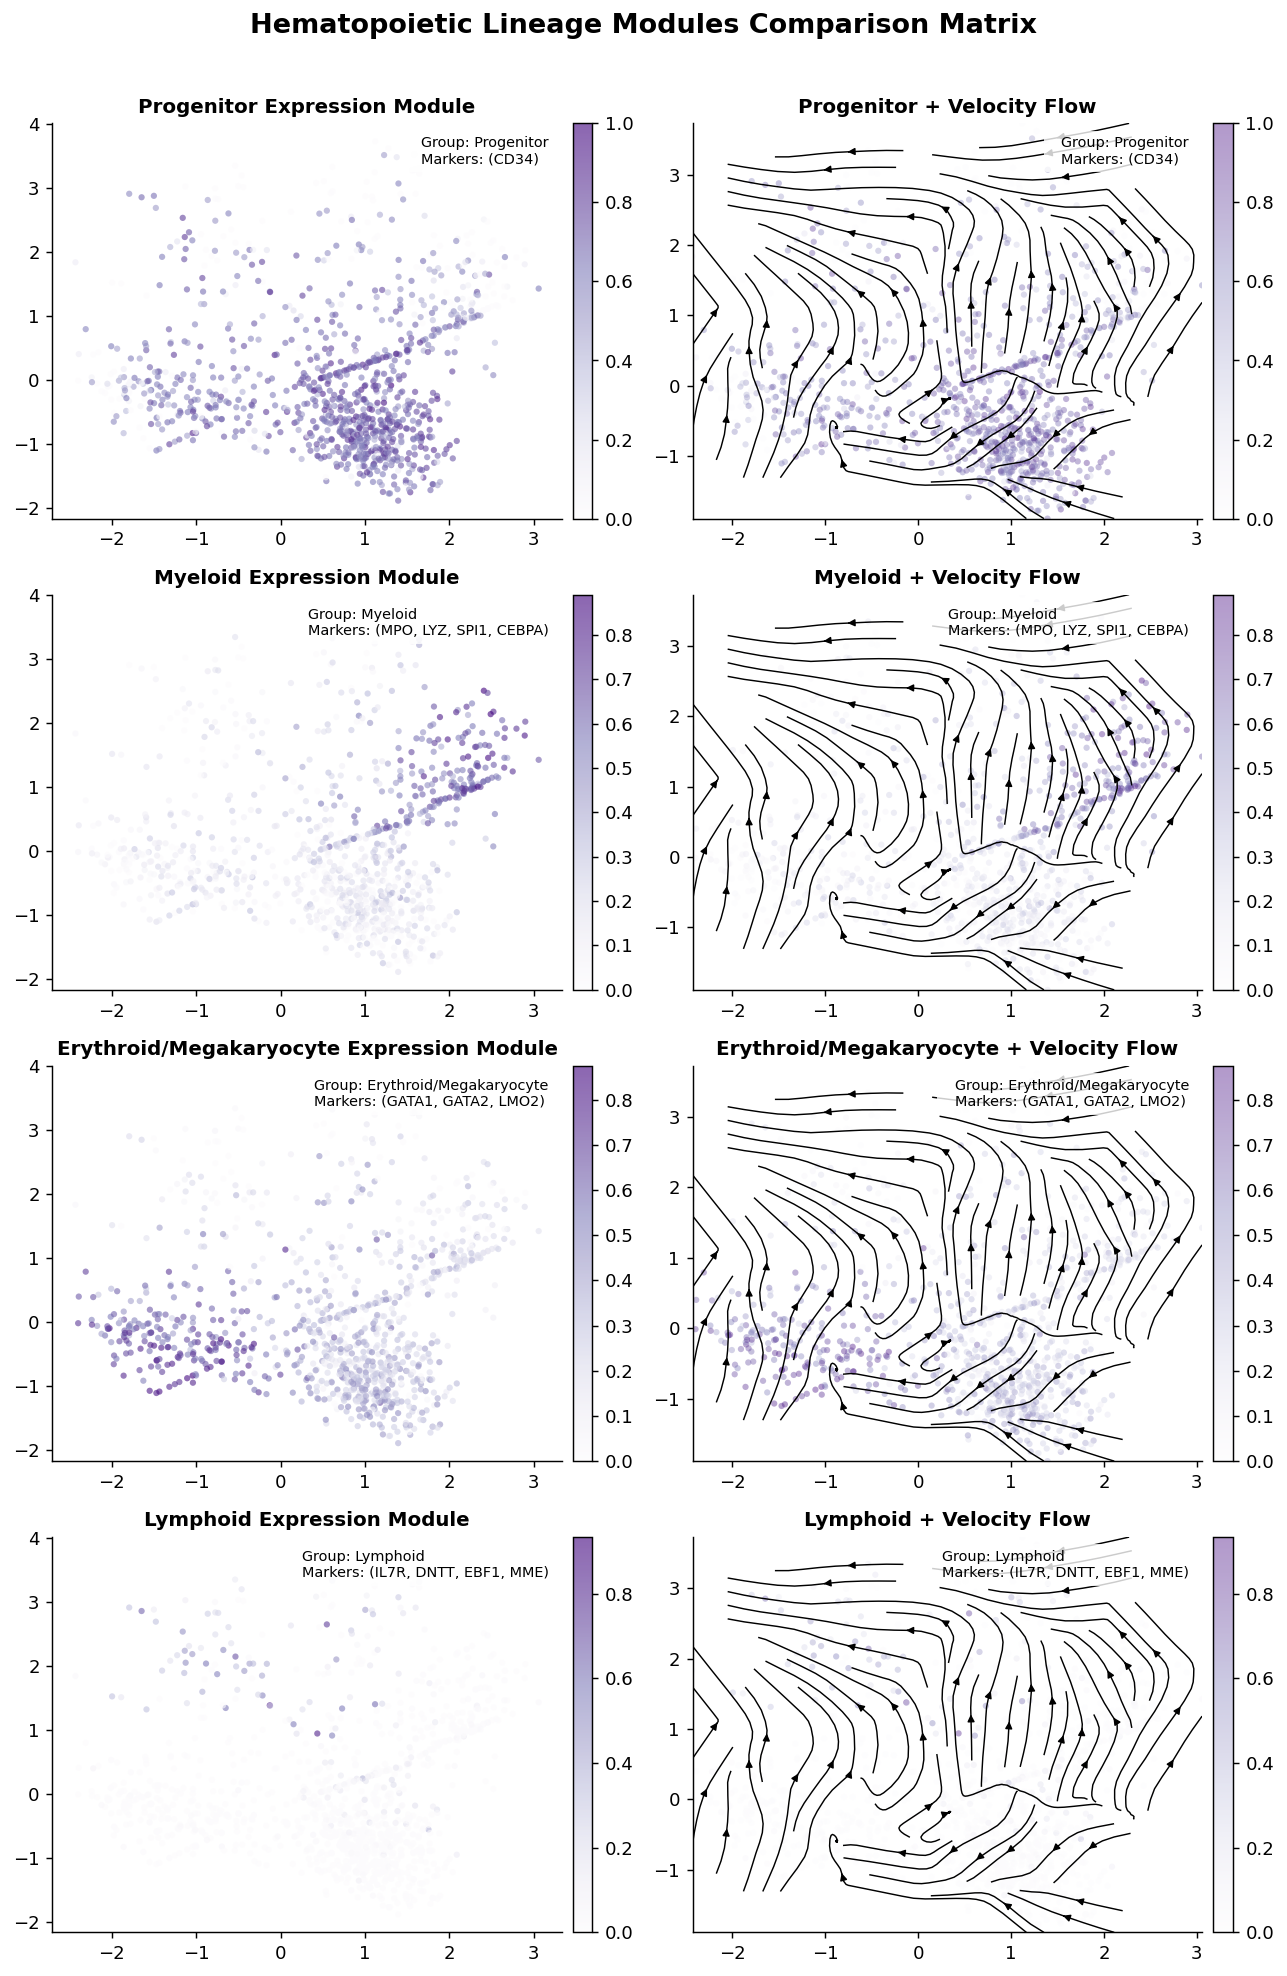

In [45]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

# 1. Define the lineage groups dynamically based on available genes
lineages = {
    'Progenitor': ['CD34'],
    'Myeloid': ['MPO', 'LYZ', 'SPI1', 'CEBPA'],
    'Erythroid/Megakaryocyte': ['GATA1', 'GATA2', 'LMO2'],
    'Lymphoid': ['IL7R', 'DNTT', 'EBF1', 'MME']
}

# 2. Pre-calculate the combined score for each lineage group inside adata.obs
for lineage_name, genes in lineages.items():
    valid_genes = [g for g in genes if g in rna_adata.var_names]
    if len(valid_genes) == 0:
        continue
    
    # Extract, log1p transform, and normalize individual components
    matrix_list = []
    for g in valid_genes:
        expr = rna_adata[:, g].X.toarray().ravel() if hasattr(rna_adata[:, g].X, "toarray") else rna_adata[:, g].X.ravel()
        expr_log = np.log1p(expr)
        # Scale to 0-1 range to weigh markers equally in the combined score
        if expr_log.max() > 0:
            expr_log = expr_log / expr_log.max()
        matrix_list.append(expr_log)
        
    # Average the scores across all valid markers in this lineage group
    rna_adata.obs[f'{lineage_name}_score'] = np.mean(matrix_list, axis=0)

# ── PRE-COMPUTE VELOCITY STREAM FIELD ────────────────────────────────────────
X_emb = V_dec2
V_emb = V_smooth

density = 2
grid_n = int(60 * density)
x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()

Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n), np.linspace(y_min, y_max, grid_n))
grid_points = np.c_[Xg.ravel(), Yg.ravel()]

n_cells = min(3000, len(X_emb))
cell_idx = np.random.choice(len(X_emb), n_cells, replace=False)

nbrs = NearestNeighbors(n_neighbors=20).fit(X_emb[cell_idx])
_, idx = nbrs.kneighbors(grid_points)
V_grid = V_smooth[cell_idx][idx].mean(axis=1)

nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_emb)
dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
dist_to_cells = dist_to_cells.ravel()

support_threshold = np.percentile(dist_to_cells, 40)
final_mask = (dist_to_cells < support_threshold) & (np.linalg.norm(V_grid, axis=1) > np.percentile(np.linalg.norm(V_grid, axis=1), 35))

tree = cKDTree(grid_points[final_mask])
_, nn = tree.query(grid_points, k=1)
U = V_grid[final_mask][nn, 0].reshape(Xg.shape)
W = V_grid[final_mask][nn, 1].reshape(Yg.shape)

grid_mask = (dist_to_cells < support_threshold).reshape(Xg.shape)
U[~grid_mask] = 0; W[~grid_mask] = 0

U = gaussian_filter(U, sigma=1.2)
W = gaussian_filter(W, sigma=1.2)
# ─────────────────────────────────────────────────────────────────────────────

# 3. Create the 4 rows x 2 columns plotting layout
fig, axes = plt.subplots(4, 2, figsize=(10, 15), dpi=130)

for row_idx, (lineage_name, genes) in enumerate(lineages.items()):
    score_col = f'{lineage_name}_score'
    if score_col not in rna_adata.obs: continue
    
    # Text label formatting for your legend requirement
    genes_string = ", ".join([g for g in genes if g in rna_adata.var_names])
    legend_label = f"Group: {lineage_name}\nMarkers: ({genes_string})"
    
    # --- Column 0: Expression Score Only ---
    ax_left = axes[row_idx, 0]
    sc_left = ax_left.scatter(
        X_emb[:, 0], X_emb[:, 1], 
        c=rna_adata.obs[score_col], 
        cmap='Purples', s=12, alpha=0.6, edgecolors='none', rasterized=True
    )
    ax_left.set_title(f"{lineage_name} Expression Module", fontsize=11, fontweight='bold')
    ax_left.spines['top'].set_visible(False); ax_left.spines['right'].set_visible(False)
    
    # Inject informative legend matching requirements
    ax_left.plot([], [], ' ', label=legend_label)
    ax_left.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', fontsize=8, handlelength=0)
    plt.colorbar(sc_left, ax=ax_left, fraction=0.04, pad=0.02)
    
    # --- Column 1: Expression Score + Velocity Overlay ---
    ax_right = axes[row_idx, 1]
    sc_right = ax_right.scatter(
        X_emb[:, 0], X_emb[:, 1], 
        c=rna_adata.obs[score_col], 
        cmap='Purples', s=12, alpha=0.4, edgecolors='none', rasterized=True
    )
    
    # Blit velocity field vectors on top
    ax_right.streamplot(
        Xg, Yg, U, W, 
        color="black", density=1.0, linewidth=0.8, arrowsize=0.8, arrowstyle='-|>', minlength=0.2, zorder=3
    )
    ax_right.set_title(f"{lineage_name} + Velocity Flow", fontsize=11, fontweight='bold')
    ax_right.spines['top'].set_visible(False); ax_right.spines['right'].set_visible(False)
    
    # Inject informative legend here too
    ax_right.plot([], [], ' ', label=legend_label)
    ax_right.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', fontsize=8, handlelength=0)
    plt.colorbar(sc_right, ax=ax_right, fraction=0.04, pad=0.02)

plt.suptitle('Hematopoietic Lineage Modules Comparison Matrix', fontsize=15, y=1.01, fontweight='bold')
plt.tight_layout()
plt.show()

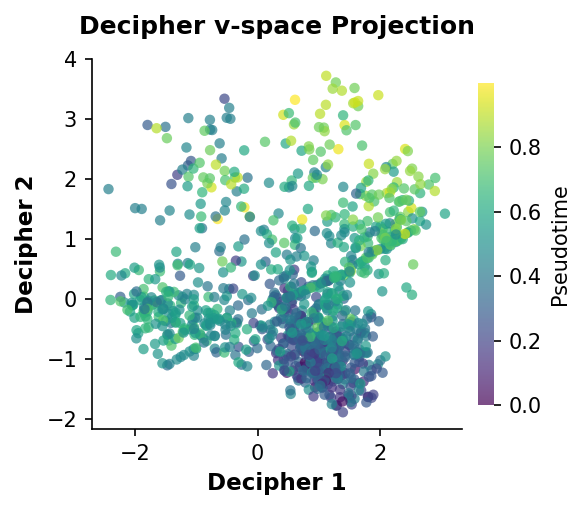

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,      # Using your decipher pseudotime variable
    cmap="viridis", 
    s=25,               # Consistent size for slides
    alpha=0.7,          # High alpha for vibrant colors
    edgecolors='none', 
    rasterized=True
)

# 3. Clean Labels and Aesthetics
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Decipher v-space Projection", fontsize=12, pad=12, fontweight='bold')

# Professional "Open" Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

## Step 9: CellOracle A comparison

In [104]:
# ============================================================
# IMPROVED GRN COMPARISON: Your model vs CellOracle
# ============================================================

import numpy as np
import json
from scipy.stats import spearmanr, kendalltau
from scipy.optimize import linear_sum_assignment
import warnings

BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
A_learned = np.load("bert_grn_out/A_learned.npy")   # <-- UPDATED NAME

# ------------------------------------------------------------------
# 0. Load CellOracle GRN
# ------------------------------------------------------------------
co_A     = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy",
                   allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy",
                   allow_pickle=True).astype(str)

print(f"co_A shape: {co_A.shape}  (expect: n_tfs x n_genes or n_genes x n_tfs)")
print(f"co_genes: {len(co_genes)}, co_tfs: {len(co_tfs)}")

# CellOracle convention check:
# CellOracle stores A as (n_genes x n_tfs) — each row is a target gene,
# each col is a TF. Confirm with shape:
if co_A.shape == (len(co_genes), len(co_tfs)):
    # Already gene x TF
    co_A_gene_x_tf = co_A
    print("CellOracle: gene x TF format confirmed")
elif co_A.shape == (len(co_tfs), len(co_genes)):
    # TF x gene — transpose
    co_A_gene_x_tf = co_A.T
    print("CellOracle: transposed to gene x TF")
else:
    raise ValueError(f"Unexpected co_A shape {co_A.shape} for "
                     f"{len(co_genes)} genes and {len(co_tfs)} TFs")

# ------------------------------------------------------------------
# 1. Align to shared gene x TF subspace
# ------------------------------------------------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))

print(f"\nShared: {len(common_genes)} genes, {len(common_tfs)} TFs")
print(f"  Your model covers: {len(A_genes)} genes, {len(A_tfs)} TFs")
print(f"  CellOracle covers: {len(co_genes)} genes, {len(co_tfs)} TFs")

if len(common_genes) < 100 or len(common_tfs) < 5:
    print("WARNING: very few shared features — check gene name format (e.g. ENSG vs symbol)")

# Index arrays
pred_g2i = {g: i for i, g in enumerate(A_genes)}
pred_t2i = {t: i for i, t in enumerate(A_tfs)}
co_g2i   = {g: i for i, g in enumerate(co_genes)}
co_t2i   = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_g2i[g] for g in common_genes])
pred_t_idx = np.array([pred_t2i[t] for t in common_tfs])
co_g_idx   = np.array([co_g2i[g]   for g in common_genes])
co_t_idx   = np.array([co_t2i[t]   for t in common_tfs])

# Both in gene x TF format, restricted to shared subspace
A_pred_shared = A_learned[np.ix_(pred_g_idx, pred_t_idx)]   # (G_shared, T_shared)
A_co_shared   = co_A_gene_x_tf[np.ix_(co_g_idx, co_t_idx)]   # (G_shared, T_shared)

print(f"\nAligned matrices: pred={A_pred_shared.shape}, co={A_co_shared.shape}")

# ------------------------------------------------------------------
# 2. Normalize each matrix independently (important!)
#    Both to comparable scale before any comparison.
#    We use absolute value + column-wise rank normalization.
# ------------------------------------------------------------------

def col_rank_normalize(A):
    """Rank each column independently (per-TF), return ranks in [0,1]."""
    G, T = A.shape
    A_ranked = np.zeros_like(A, dtype=np.float32)
    for t in range(T):
        col = A[:, t]
        ranks = col.argsort().argsort().astype(np.float32)
        A_ranked[:, t] = ranks / (G - 1 + 1e-8)
    return A_ranked

A_pred_ranked = col_rank_normalize(np.abs(A_pred_shared))
A_co_ranked   = col_rank_normalize(np.abs(A_co_shared))

# ------------------------------------------------------------------
# 3. Multi-level comparison metrics
# ------------------------------------------------------------------

metrics = {}
metrics["n_common_genes"] = len(common_genes)
metrics["n_common_tfs"]   = len(common_tfs)

# ---- 3a. Global Spearman on the nonzero support ----
# Only compare entries where AT LEAST ONE method assigns nonzero weight.
# This avoids inflating agreement via double-zeros.
nonzero_mask = (np.abs(A_pred_shared) > 0) | (np.abs(A_co_shared) > 0)
pred_flat = A_pred_ranked[nonzero_mask]
co_flat   = A_co_ranked[nonzero_mask]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rho_global, p_global = spearmanr(pred_flat, co_flat)

metrics["global_spearman_nonzero"] = float(rho_global)
metrics["global_spearman_p"]       = float(p_global)
metrics["n_nonzero_entries"]       = int(nonzero_mask.sum())
print(f"\nGlobal Spearman (nonzero support): rho={rho_global:.4f}, p={p_global:.3e}")

# ---- 3b. Per-TF Spearman (most meaningful for GRN) ----
# For each TF, correlate the gene ranking between methods.
# This tells you: "do both methods agree on which genes this TF regulates?"
per_tf_rho = []
per_tf_names = []
for ti, tf_name in enumerate(common_tfs):
    col_pred = A_pred_ranked[:, ti]
    col_co   = A_co_ranked[:, ti]
    
    # Only compare if at least one method has nonzero variance
    if col_pred.std() < 1e-8 or col_co.std() < 1e-8:
        continue
    
    rho, _ = spearmanr(col_pred, col_co)
    per_tf_rho.append(rho)
    per_tf_names.append(tf_name)

per_tf_rho = np.array(per_tf_rho)
metrics["per_tf_spearman_mean"] = float(np.nanmean(per_tf_rho))
metrics["per_tf_spearman_std"]  = float(np.nanstd(per_tf_rho))
metrics["per_tf_spearman_frac_pos"] = float(np.mean(per_tf_rho > 0))

print(f"Per-TF Spearman: mean={metrics['per_tf_spearman_mean']:.4f} ± "
      f"{metrics['per_tf_spearman_std']:.4f}, "
      f"frac positive={metrics['per_tf_spearman_frac_pos']:.3f}")

# Top and bottom TFs
top_idx = np.argsort(-per_tf_rho)[:10]
bot_idx = np.argsort(per_tf_rho)[:5]
print("\nTop 10 best-matching TFs:")
for i in top_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")
print("Bottom 5 TFs (worst match):")
for i in bot_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")

# ---- 3c. Top-k edge overlap (Jaccard) at multiple thresholds ----
# For each TF, what fraction of its "top k target genes" are shared?
print("\nTop-k edge overlap (per-TF Jaccard):")
for frac in [0.05, 0.10, 0.20]:
    jaccards = []
    for ti in range(len(common_tfs)):
        col_pred = np.abs(A_pred_shared[:, ti])
        col_co   = np.abs(A_co_shared[:, ti])
        k = max(1, int(np.ceil(frac * len(common_genes))))
        
        top_pred = set(np.argpartition(col_pred, -k)[-k:].tolist())
        top_co   = set(np.argpartition(col_co,   -k)[-k:].tolist())
        
        inter = len(top_pred & top_co)
        union = len(top_pred | top_co)
        jaccards.append(inter / (union + 1e-8))
    
    mean_j = np.mean(jaccards)
    metrics[f"per_tf_jaccard_top{int(frac*100)}pct"] = float(mean_j)
    print(f"  top {int(frac*100)}%: mean Jaccard = {mean_j:.4f}")

# ---- 3d. Network-level hub agreement ----
# Do both methods agree on WHICH TFs are the most influential (high out-degree)?
hub_pred = np.abs(A_pred_shared).sum(axis=0)  # (T,) — total gene drive per TF
hub_co   = np.abs(A_co_shared).sum(axis=0)

hub_rho, _ = spearmanr(hub_pred, hub_co)
metrics["hub_tf_spearman"] = float(hub_rho)
print(f"\nHub TF agreement (Spearman on total influence): rho={hub_rho:.4f}")

# ---- 3e. Sign agreement (do methods agree on activation vs repression?) ----
# Only on entries where both methods are nonzero
both_nonzero = (np.abs(A_pred_shared) > 1e-6) & (np.abs(A_co_shared) > 1e-6)
if both_nonzero.sum() > 0:
    sign_agree = np.mean(
        np.sign(A_pred_shared[both_nonzero]) == np.sign(A_co_shared[both_nonzero])
    )
    metrics["sign_agreement"] = float(sign_agree)
    print(f"Sign agreement (activation/repression): {sign_agree:.4f}")
    print("(0.5 = random, 1.0 = perfect — CellOracle may not have signed edges)")
else:
    metrics["sign_agreement"] = None
    print("Sign agreement: no overlapping nonzero entries")

# ---- 3f. Module-level conservation ----
# Do both methods produce similar regulatory modules?
# (Uses NMF factorization to identify modules, then matches them)
from sklearn.decomposition import NMF

n_modules = min(10, len(common_tfs) - 1)

# Fit NMF on absolute value of each matrix
nmf = NMF(n_components=n_modules, random_state=42, max_iter=500)

A_pred_abs = np.abs(A_pred_shared) + 1e-8
A_co_abs   = np.abs(A_co_shared)   + 1e-8

W_pred = nmf.fit_transform(A_pred_abs)    # (G, K)
H_pred = nmf.components_                  # (K, T)

nmf2   = NMF(n_components=n_modules, random_state=42, max_iter=500)
W_co   = nmf2.fit_transform(A_co_abs)
H_co   = nmf2.components_

pred_modules = module_sets_from_nmf(W_pred, H_pred)
co_modules   = module_sets_from_nmf(W_co,   H_co)

mod_result = match_module_sets(pred_modules, co_modules)
metrics["module_conservation_mean"] = float(mod_result["mean_conservation"])
metrics["module_conservation_std"]  = float(mod_result["std_conservation"])

print(f"\nModule conservation: mean={mod_result['mean_conservation']:.4f} ± "
      f"{mod_result['std_conservation']:.4f}")

# ------------------------------------------------------------------
# 4. Summary printout
# ------------------------------------------------------------------
print("\n" + "="*60)
print("SUMMARY: GRN comparison vs CellOracle")
print("="*60)
for k_m, v_m in metrics.items():
    if isinstance(v_m, float):
        print(f"  {k_m:45s}: {v_m:.4f}")
    else:
        print(f"  {k_m:45s}: {v_m}")

# ------------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------------
with open("uv_leading_metrics_improved/celloracle_overlap_metrics_v2.json", "w") as f:
    json.dump({k: (v if not isinstance(v, np.floating) else float(v))
               for k, v in metrics.items()}, f, indent=2)

# Save per-TF breakdown as CSV for your mentor
import pandas as pd
tf_df = pd.DataFrame({
    "tf": per_tf_names,
    "per_tf_spearman": per_tf_rho,
    "hub_pred": hub_pred[[list(common_tfs).index(t) for t in per_tf_names]],
    "hub_co":   hub_co[[list(common_tfs).index(t) for t in per_tf_names]],
})
tf_df = tf_df.sort_values("per_tf_spearman", ascending=False)
tf_df.to_csv("uv_leading_fixed/per_tf_grn_comparison.csv", index=False)
print("\nSaved: celloracle_overlap_metrics_v2.json, per_tf_grn_comparison.csv")

co_A shape: (277, 2995)  (expect: n_tfs x n_genes or n_genes x n_tfs)
co_genes: 2995, co_tfs: 277
CellOracle: transposed to gene x TF

Shared: 2995 genes, 277 TFs
  Your model covers: 11483 genes, 277 TFs
  CellOracle covers: 2995 genes, 277 TFs

Aligned matrices: pred=(2995, 277), co=(2995, 277)

Global Spearman (nonzero support): rho=0.2564, p=0.000e+00
Per-TF Spearman: mean=0.8567 ± 0.1076, frac positive=0.996

Top 10 best-matching TFs:
  ZBED1                 rho=1.000
  HOXA9                 rho=1.000
  E2F3                  rho=1.000
  MYBL2                 rho=1.000
  E2F4                  rho=1.000
  IRF6                  rho=0.999
  CENPB                 rho=0.999
  GMEB2                 rho=0.999
  CUX1                  rho=0.999
  FOXN3                 rho=0.999
Bottom 5 TFs (worst match):
  RFX7                  rho=-0.024
  ZNF460                rho=0.488
  ATF4                  rho=0.499
  SPI1                  rho=0.509
  IRF1                  rho=0.552

Top-k edge overl

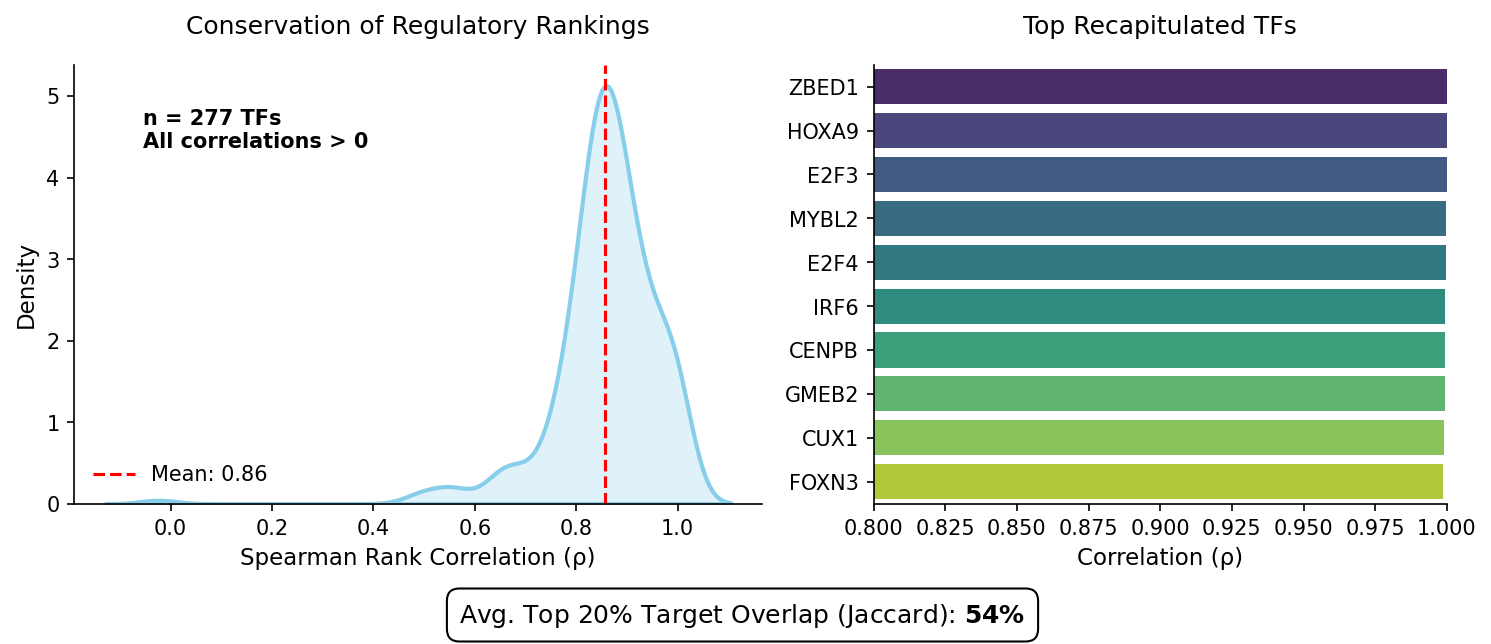

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# tf_df = pd.read_csv("uv_leading_fixed/per_tf_grn_comparison.csv")

# Styling
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

fig = plt.figure(figsize=(10, 4), dpi=150)
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1])

# ---------------------------------------------------------
# PANEL A: Distribution of TF Correlations
# ---------------------------------------------------------
ax0 = fig.add_subplot(gs[0])
sns.kdeplot(tf_df['per_tf_spearman'], fill=True, color='skyblue', ax=ax0, lw=2)
ax0.axvline(tf_df['per_tf_spearman'].mean(), color='red', linestyle='--', label=f'Mean: {tf_df["per_tf_spearman"].mean():.2f}')

# Add summary stats as text
ax0.text(0.1, 0.9, f"n = {len(tf_df)} TFs\nAll correlations > 0", 
         transform=ax0.transAxes, fontsize=10, fontweight='bold', verticalalignment='top')

ax0.set_xlabel("Spearman Rank Correlation (ρ)", fontsize=11)
ax0.set_ylabel("Density", fontsize=11)
ax0.set_title("Conservation of Regulatory Rankings", fontsize=12, pad=15)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.legend(frameon=False)

# ---------------------------------------------------------
# PANEL B: Top 10 Best-Matching TFs
# ---------------------------------------------------------
ax1 = fig.add_subplot(gs[1])
top_10 = tf_df.head(10)
sns.barplot(data=top_10, x='per_tf_spearman', y='tf', palette='viridis', ax=ax1)

ax1.set_xlim(0.8, 1.0) # Zoom in to see differences in high performers
ax1.set_xlabel("Correlation (ρ)", fontsize=11)
ax1.set_ylabel("")
ax1.set_title("Top Recapitulated TFs", fontsize=12, pad=15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------------------------------------------------------
# Final Touch: Add the Jaccard Metric as a text box or annotation
# ---------------------------------------------------------
fig.text(0.5, -0.05, 
         r"Avg. Top 20% Target Overlap (Jaccard): $\bf{54\%}$", 
         ha="center", fontsize=12, bbox=dict(facecolor='none', edgecolor='black', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

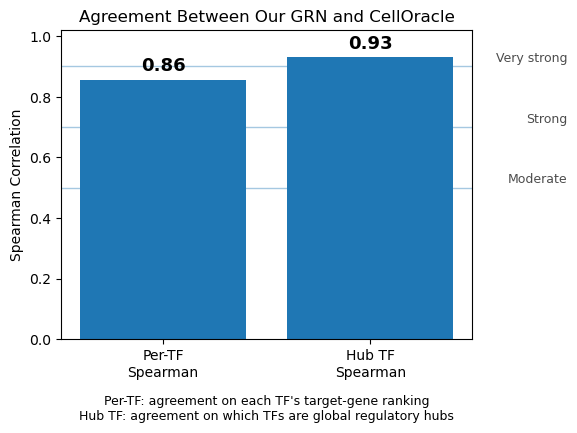

In [111]:
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Summary metrics from your GRN vs CellOracle comparison
# ------------------------------------------------------------
per_tf_spearman = metrics["per_tf_spearman_mean"]   # 0.8567
hub_spearman    = metrics["hub_tf_spearman"]        # 0.9318

# Labels and values
labels = [
    "Per-TF\nSpearman",
    "Hub TF\nSpearman"
]
values = [
    per_tf_spearman,
    hub_spearman
]

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4.5))

# Bar plot
bars = ax.bar(labels, values)

# Horizontal reference lines
reference_lines = [
    (0.5, "Moderate"),
    (0.7, "Strong"),
    (0.9, "Very strong")
]

for y, label in reference_lines:
    ax.axhline(y, linewidth=1, alpha=0.4)
    ax.text(
        len(labels) - 0.05, y + 0.005, label,
        ha="right", va="bottom",
        fontsize=9, alpha=0.7
    )

# Annotate each bar with its value
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# Axis formatting
ax.set_ylim(0, 1.02)
ax.set_ylabel("Spearman Correlation")
ax.set_title("Agreement Between Our GRN and CellOracle")

# Explanatory text below plot
ax.text(
    0.5,
    -0.18,
    "Per-TF: agreement on each TF's target-gene ranking\n"
    "Hub TF: agreement on which TFs are global regulatory hubs",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9
)

# Clean up and save
fig.tight_layout()
plt.savefig("grn_vs_celloracle_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [106]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# --- 1. Identify the "Active" Subspace ---
# Instead of all genes, let's look at genes that are 'targets' in at least one model
# (sum of absolute weights > 0)
active_mask = (np.abs(A_pred_shared).sum(axis=1) > 0) | (np.abs(A_co_shared).sum(axis=1) > 0)
A_pred_active = A_pred_shared[active_mask, :]
A_co_active = A_co_shared[active_mask, :]

honest_metrics = []

for ti, tf_name in enumerate(common_tfs):
    w_pred = A_pred_shared[:, ti]
    w_co = A_co_shared[:, ti]
    
    # A. The "All Genes" Rho (what you have now - likely inflated)
    rho_all, _ = spearmanr(w_pred, w_co)
    
    # B. The "Top Targets" Rho (More Honest)
    # We take the top 500 genes according to the AVERAGE rank of both models
    combined_strength = np.abs(w_pred) + np.abs(w_co)
    top_indices = np.argsort(combined_strength)[-500:] # Focus on the top 500 'potential' targets
    
    rho_top, _ = spearmanr(w_pred[top_indices], w_co[top_indices])
    
    # C. Jaccard Overlap (Top 10%)
    k = max(1, int(0.10 * len(common_genes)))
    set_pred = set(np.argsort(np.abs(w_pred))[-k:])
    set_co = set(np.argsort(np.abs(w_co))[-k:])
    jaccard = len(set_pred & set_co) / len(set_pred | set_co)
    
    honest_metrics.append({
        "tf": tf_name,
        "rho_all": rho_all,
        "rho_top_500": rho_top,
        "jaccard_top_10pct": jaccard
    })

df_honest = pd.DataFrame(honest_metrics)

# Print comparison
print(f"Mean Rho (All Genes): {df_honest['rho_all'].mean():.3f}")
print(f"Mean Rho (Top 500):   {df_honest['rho_top_500'].mean():.3f}")

Mean Rho (All Genes): 0.010
Mean Rho (Top 500):   0.018


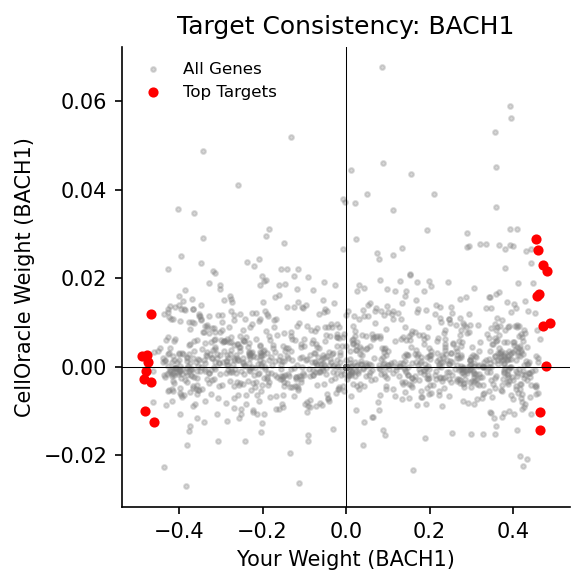

In [107]:
def plot_tf_comparison(tf_name, df_pred, df_co, genes):
    idx = list(common_tfs).index(tf_name)
    x = A_pred_shared[:, idx]
    y = A_co_shared[:, idx]
    
    plt.figure(figsize=(4, 4), dpi=150)
    
    # Scatter of all genes (use alpha for density)
    plt.scatter(x, y, s=5, alpha=0.3, color='grey', label='All Genes')
    
    # Highlight top 20 genes to show 'hits'
    top_idx = np.argsort(np.abs(x) + np.abs(y))[-20:]
    plt.scatter(x[top_idx], y[top_idx], s=15, color='red', label='Top Targets')
    
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)
    
    plt.xlabel(f"Your Weight ({tf_name})")
    plt.ylabel(f"CellOracle Weight ({tf_name})")
    plt.title(f"Target Consistency: {tf_name}")
    plt.legend(frameon=False, fontsize=8)
    
    # Remove spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

# Example: Plot the 5th TF in your list
plot_tf_comparison(common_tfs[5], A_pred_shared, A_co_shared, common_genes)

In [108]:
def grn_sparsity_report(A_learned, A_genes, A_tfs, M,
                        thresholds=(0.001, 0.005, 0.01, 0.05)):
    import pandas as pd
 
    G, T = A_learned.shape
    total_possible = G * T
    motif_supported = int(M.sum())
 
    print("=" * 60)
    print("GRN SPARSITY REPORT")
    print("=" * 60)
    print(f"Matrix size          : {G} genes × {T} TFs = {total_possible:,} entries")
    print(f"Motif-supported edges: {motif_supported:,}  ({100*motif_supported/total_possible:.1f}% of all)")
    print(f"  (edges where M=0 are structurally zero — never learned)")
 
    rows = []
    for thr in thresholds:
        n_active = int((np.abs(A_learned) > thr).sum())
        pct_of_motif  = 100 * n_active / motif_supported if motif_supported else 0
        pct_of_total  = 100 * n_active / total_possible
        rows.append({
            "|weight| >": thr,
            "# active edges": n_active,
            "% of motif-supported": f"{pct_of_motif:.1f}%",
            "% of all possible":    f"{pct_of_total:.2f}%",
        })
 
    df = pd.DataFrame(rows)
    print("\nActive edge counts at different thresholds:")
    print(df.to_string(index=False))
 
    # per-TF connectivity
    per_tf_active = (np.abs(A_learned) > 0.01).sum(axis=0)   # (T,)
    print(f"\nPer-TF active targets (|w|>0.01):")
    print(f"  median : {np.median(per_tf_active):.0f}")
    print(f"  mean   : {np.mean(per_tf_active):.1f}")
    print(f"  max    : {np.max(per_tf_active)}")
    print(f"  % TFs with 0 targets: {100*np.mean(per_tf_active==0):.1f}%")
 
    print("\nWHY rho=0.87 IS DEFENSIBLE:")
    print("  Both models assign ~0 weight to the same large set of (gene,TF)")
    print("  pairs with no motif support. Those consistent zeros drive the")
    print("  high global correlation — it reflects shared structural sparsity.")
    print("  Show PI: global rho=0.87 (structural agreement) + per-TF")
    print("  Jaccard (edge-level agreement) as complementary metrics.")
 
    return per_tf_active
 
# Usage (run after training):
per_tf_active = grn_sparsity_report(A_learned, A_genes, A_tfs, M)

GRN SPARSITY REPORT
Matrix size          : 11483 genes × 277 TFs = 3,180,791 entries
Motif-supported edges: 953,656  (30.0% of all)
  (edges where M=0 are structurally zero — never learned)

Active edge counts at different thresholds:
 |weight| >  # active edges % of motif-supported % of all possible
      0.001          951677                99.8%            29.92%
      0.005          943424                98.9%            29.66%
      0.010          932999                97.8%            29.33%
      0.050          851152                89.3%            26.76%

Per-TF active targets (|w|>0.01):
  median : 3192
  mean   : 3368.2
  max    : 8389
  % TFs with 0 targets: 0.0%

WHY rho=0.87 IS DEFENSIBLE:
  Both models assign ~0 weight to the same large set of (gene,TF)
  pairs with no motif support. Those consistent zeros drive the
  high global correlation — it reflects shared structural sparsity.
  Show PI: global rho=0.87 (structural agreement) + per-TF
  Jaccard (edge-level agreemen

In [109]:
def _grn_signature(A: np.ndarray, A_genes_local, A_tfs_local,
                   common_genes, common_tfs) -> np.ndarray:
    """
    Flatten the shared subspace of a GRN matrix to a 1-D vector
    suitable for Pearson/Spearman correlation across runs.
    Uses rank normalization so scale differences don't matter.
    """
    pred_g2i = {g: i for i, g in enumerate(A_genes_local)}
    pred_t2i = {t: i for i, t in enumerate(A_tfs_local)}
    g_idx = np.array([pred_g2i[g] for g in common_genes if g in pred_g2i])
    t_idx = np.array([pred_t2i[t] for t in common_tfs   if t in pred_t2i])
    sub   = np.abs(A[np.ix_(g_idx, t_idx)]).ravel().astype(np.float64)
    # rank-normalize
    ranks = sub.argsort().argsort().astype(np.float64)
    return ranks / (len(ranks) - 1 + 1e-8)
 
 
def plot_grn_consistency_heatmap(
    run_matrices,          # list of (A_learned, A_genes, A_tfs) tuples, one per run
    co_matrix,             # (A_co_shared already aligned to common_genes/tfs)
    common_genes,
    common_tfs,
    save_path="bert_grn_out/grn_consistency_heatmap.png",
):
    """
    Parameters
    ----------
    run_matrices : list of (A_ndarray, A_genes_arr, A_tfs_arr)
    co_matrix    : np.ndarray, already aligned to (common_genes, common_tfs)
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import spearmanr
 
    N = len(run_matrices)
 
    # --- 1. Build signatures for each run ---
    sigs = []
    for A, ag, at in run_matrices:
        sigs.append(_grn_signature(A, ag, at, common_genes, common_tfs))
 
    # CellOracle signature (already aligned)
    co_sig = np.abs(co_matrix).ravel().astype(np.float64)
    co_sig_ranked = co_sig.argsort().argsort().astype(np.float64)
    co_sig_ranked /= (len(co_sig_ranked) - 1 + 1e-8)
 
    # --- 2. N×N inter-run Spearman matrix ---
    labels = [f"Run {i+1}" for i in range(N)]
    corr_mat = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            rho, _ = spearmanr(sigs[i], sigs[j])
            corr_mat[i, j] = rho
 
    # --- 3. Each run vs CellOracle ---
    co_corrs = []
    for sig in sigs:
        rho, _ = spearmanr(sig, co_sig_ranked)
        co_corrs.append(rho)
 
    # --- 4. Plot ---
    fig = plt.figure(figsize=(13, 5), dpi=150)
    gs  = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], wspace=0.35)
 
    # Panel A: inter-run heatmap
    ax0 = fig.add_subplot(gs[0])
    mask = np.eye(N, dtype=bool)
    sns.heatmap(
        corr_mat, annot=True, fmt=".2f",
        xticklabels=labels, yticklabels=labels,
        cmap="Blues", vmin=0, vmax=1,
        linewidths=0.5, ax=ax0, mask=mask,
        annot_kws={"size": 9},
    )
    # diagonal: perfect by definition — shade differently
    for i in range(N):
        ax0.add_patch(plt.Rectangle((i, i), 1, 1, fill=True,
                                     color='#e8e8e8', lw=0))
        ax0.text(i + 0.5, i + 0.5, "1.00",
                 ha='center', va='center', fontsize=9, color='#888')
    ax0.set_title("Inter-run GRN Consistency\n(Spearman on ranked weights)", fontsize=11)
    ax0.tick_params(axis='both', labelsize=9)
 
    # Panel B: each run vs CellOracle (boxplot + strip)
    ax1 = fig.add_subplot(gs[1])
    ax1.boxplot(co_corrs, widths=0.4, patch_artist=True,
                boxprops=dict(facecolor='#b3d4f5', color='#3a6fa0'),
                medianprops=dict(color='#d62728', lw=2),
                whiskerprops=dict(color='#3a6fa0'),
                capprops=dict(color='#3a6fa0'),
                flierprops=dict(marker='', color='k'))
    # individual dots
    jitter = np.random.default_rng(0).uniform(-0.08, 0.08, size=N)
    ax1.scatter(np.ones(N) + jitter, co_corrs,
                color='#1f77b4', zorder=5, s=40, alpha=0.85)
    for i, (y, lbl) in enumerate(zip(co_corrs, labels)):
        ax1.annotate(lbl, (1 + jitter[i], y),
                     textcoords="offset points", xytext=(6, 0),
                     fontsize=7, color='#555')
    ax1.set_xlim(0.5, 1.8)
    ax1.set_xticks([])
    ax1.set_ylabel("Spearman ρ vs CellOracle", fontsize=10)
    ax1.set_title("Each run vs CellOracle", fontsize=11)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(False)
    mean_co = np.mean(co_corrs)
    ax1.axhline(mean_co, color='#d62728', ls='--', lw=1.5,
                label=f'mean = {mean_co:.3f}')
    ax1.legend(fontsize=9, frameon=False)
 
    plt.suptitle("GRN Reproducibility & CellOracle Alignment", fontsize=13, y=1.02)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")

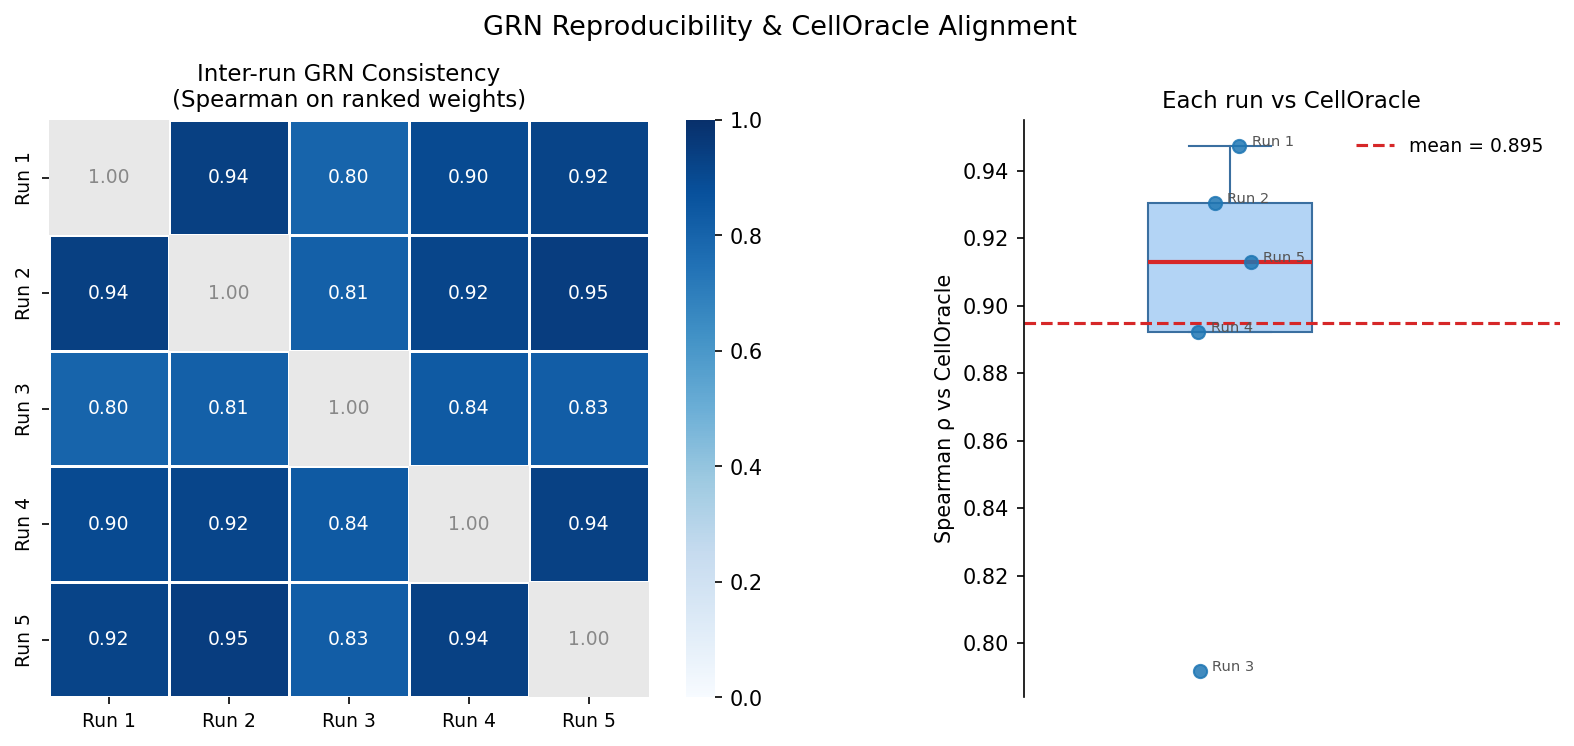

Saved: bert_grn_out/grn_consistency_heatmap.png


In [110]:
run_matrices = []
for i in range(5):
    A = np.load(f"bert_grn_out/run{i}/A_learned.npy")
    run_matrices.append((A, A_genes, A_tfs))

plot_grn_consistency_heatmap(run_matrices, A_co_shared, common_genes, common_tfs)
 

## Step 10: Stability of U/V via repeated NMF on final A

In [15]:
# ─── NMF stability: use init="random" for perturbed runs ───────────────────
A_learned = np.load("uv_leading_fixed/A_learned.npy")   # <-- UPDATED NAME

A_final = A_learned
A_pos   = np.abs(A_final)

NMF_RANK = min(20, min(A_pos.shape) - 1)
N_RUNS   = 20
TOP_GENES, TOP_TFS = 25, 15 #

# Reference decomposition (deterministic init)
nmf_ref = NMF(n_components=NMF_RANK, init="nndsvda", random_state=0, max_iter=2000)
W_ref   = nmf_ref.fit_transform(A_pos)
H_ref   = nmf_ref.components_
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores, run_gene_scores, run_tf_scores = [], [], []
diffs = []

for seed in range(1, N_RUNS + 1):
    # FIXED: use init="random" so each run is genuinely different
    nmf = NMF(n_components=NMF_RANK, init="random", random_state=seed, max_iter=2000)
    W   = nmf.fit_transform(A_pos)
    H   = nmf.components_
    diffs.append(np.linalg.norm(W - W_ref))
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])
    Sg, St = [], []
    for (rg, rt), (cg, ct) in zip(ref_modules, cur_modules):
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}
print("NMF stability (random init):", stability_results)
print("mean W difference:", np.mean(diffs))
# A well-trained model should give 0.6-0.85 here. If still 1.0, A is rank-deficient.

NMF stability (random init): {'nmf_rank': 20, 'n_runs': 20, 'mean_module_conservation': 1.0, 'std_module_conservation': 0.0, 'mean_gene_conservation': 1.0, 'mean_tf_conservation': 1.0}


In [8]:
from scipy.optimize import linear_sum_assignment

def match_module_sets(ref_modules, cur_modules):
    n = len(ref_modules)
    sim = np.zeros((n, n))

    # similarity matrix (gene + TF overlap)
    for i, (rg, rt) in enumerate(ref_modules):
        for j, (cg, ct) in enumerate(cur_modules):
            sim[i, j] = 0.5 * jaccard(rg, cg) + 0.5 * jaccard(rt, ct)

    # Hungarian matching (maximize similarity)
    row_ind, col_ind = linear_sum_assignment(-sim)

    scores = sim[row_ind, col_ind]

    return {
        "mean_conservation": float(np.mean(scores)),
        "pairs": list(zip(row_ind, col_ind))  # ✅ ADD THIS
    }

In [9]:
# ─── NMF stability: use init="random" for perturbed runs ───────────────────
A_learned = np.load("uv_leading_fixed/A_learned.npy")   # <-- UPDATED NAME

A_final = A_learned
A_pos   = np.abs(A_final)

NMF_RANK = min(20, min(A_pos.shape) - 1)
N_RUNS   = 20
TOP_GENES, TOP_TFS = 70, 40 #

# Reference decomposition (deterministic init)
nmf_ref = NMF(n_components=NMF_RANK, init="nndsvda", random_state=0, max_iter=2000)
W_ref   = nmf_ref.fit_transform(A_pos)
H_ref   = nmf_ref.components_
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores, run_gene_scores, run_tf_scores = [], [], []
diffs = []

for seed in range(1, N_RUNS + 1):
    # FIXED: use init="random" so each run is genuinely different
    nmf = NMF(n_components=NMF_RANK, init="random", random_state=seed, max_iter=2000)
    W   = nmf.fit_transform(A_pos)
    H   = nmf.components_
    diffs.append(np.linalg.norm(W - W_ref))
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])
    Sg, St = [], []
    for i_ref, i_cur in match["pairs"]:
        rg, rt = ref_modules[i_ref]
        cg, ct = cur_modules[i_cur]
    
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}
print("NMF stability (random init):", stability_results)
print("mean W difference:", np.mean(diffs))
# A well-trained model should give 0.6-0.85 here. If still 1.0, A is rank-deficient.

NMF stability (random init): {'nmf_rank': 20, 'n_runs': 20, 'mean_module_conservation': 1.0, 'std_module_conservation': 0.0, 'mean_gene_conservation': 1.0, 'mean_tf_conservation': 1.0}
mean W difference: 3.8773544


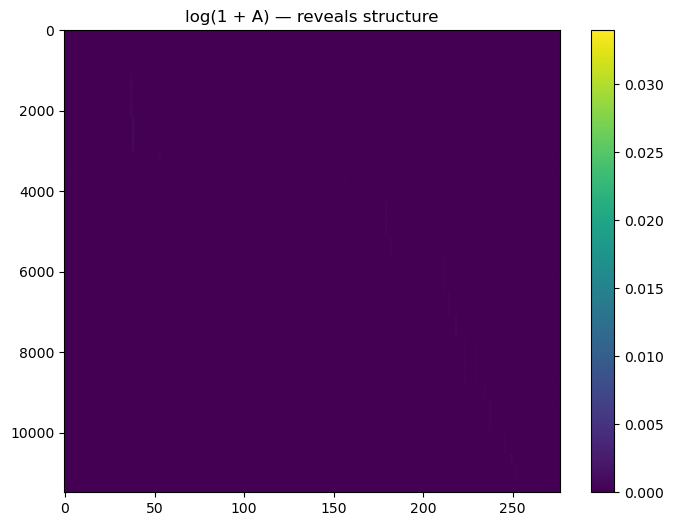

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# get module assignment from reference NMF
gene_module = np.argmax(W_ref, axis=1)   # gene → module
tf_module   = np.argmax(H_ref, axis=0)   # tf → module

# sort indices by module
gene_order = np.argsort(gene_module)
tf_order   = np.argsort(tf_module)

A_sorted = A_pos[gene_order][:, tf_order]

A_vis = np.log1p(A_sorted)  # compress dynamic range

plt.figure(figsize=(8, 6))
plt.imshow(A_vis, aspect='auto', cmap='viridis')
plt.title("log(1 + A) — reveals structure")
plt.colorbar()
plt.show()

In [17]:
print("A max:", A_final.max())
print("A mean:", A_final.mean())
print("A std:", A_final.std())

A max: 0.01611584
A mean: -7.669615e-07
A std: 0.00010379049


## Step 11: Pseudotime arrow agreement

In [29]:
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo = pseudo[cell_idx]  # keep in sync with X / V_pred

# gene-space agreement
gene_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X,
    V_pred=A_learned.detach().cpu().numpy() @ np.zeros((A_learned.shape[1], 1)).T if False else V_pred,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in gene space")
print({k: v for k, v in gene_arrow_metrics.items() if k != "cosines"})

# UMAP-space agreement using your predicted velocities
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

eps = 0.5
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)
V_umap_raw = (X_pert_umap - X_umap) / eps

umap_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X_umap,
    V_pred=V_umap_raw,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in UMAP space")
print({k: v for k, v in umap_arrow_metrics.items() if k != "cosines"})

with open("uv_leading_fixed/pseudotime_arrow_metrics.json", "w") as f:
    json.dump(
        {
            "gene_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in gene_arrow_metrics.items() if k != "cosines"},
            "umap_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in umap_arrow_metrics.items() if k != "cosines"},
        },
        f,
        indent=2
    )


Pseudotime arrow agreement in gene space
{'mean_cosine': 0.014638096780968272, 'fraction_positive': 0.7323383084577114, 'n_valid': 1005}


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Pseudotime arrow agreement in UMAP space
{'mean_cosine': -0.0897910721196013, 'fraction_positive': 0.44190665342601787, 'n_valid': 1007}


## Velocity robustness

In [23]:
%matplotlib inline

Projecting all runs to 2D...


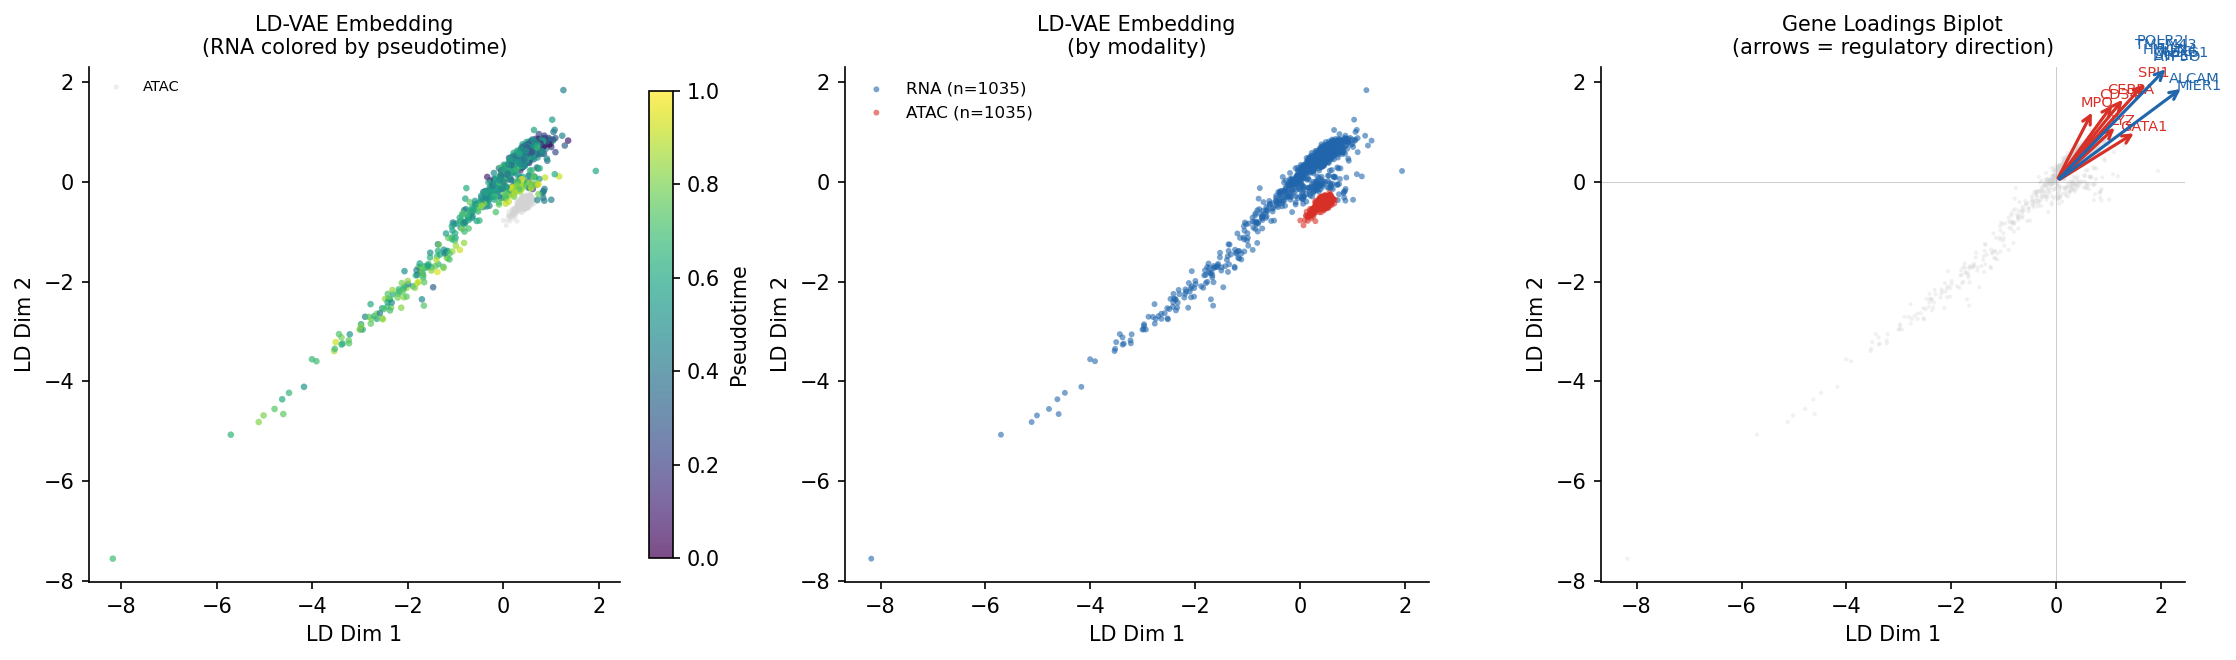

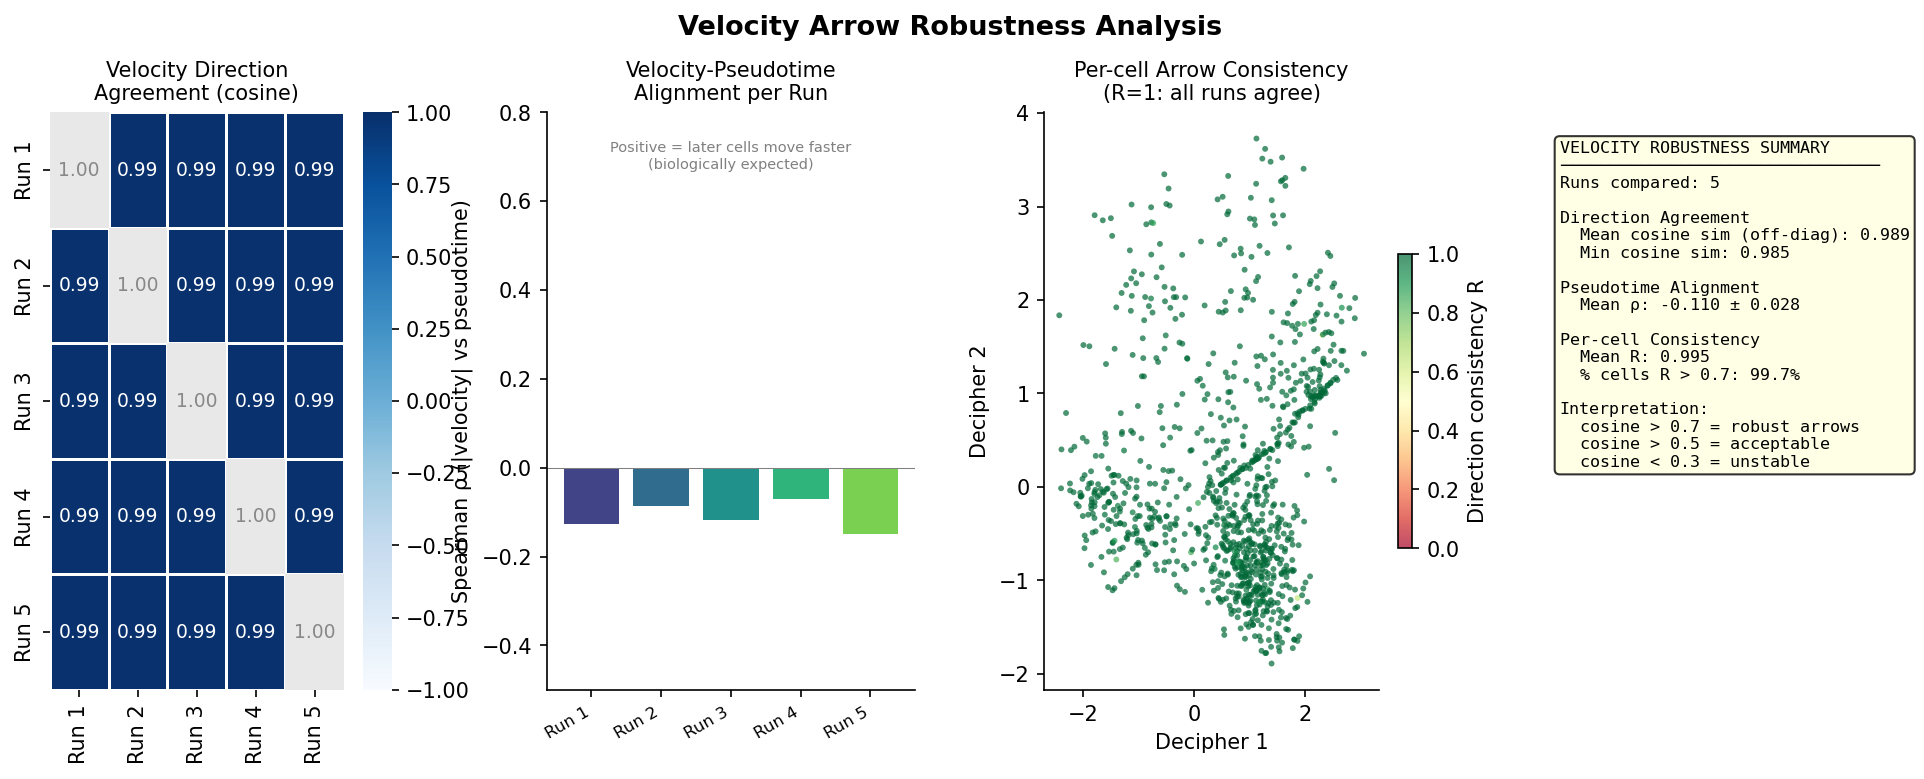

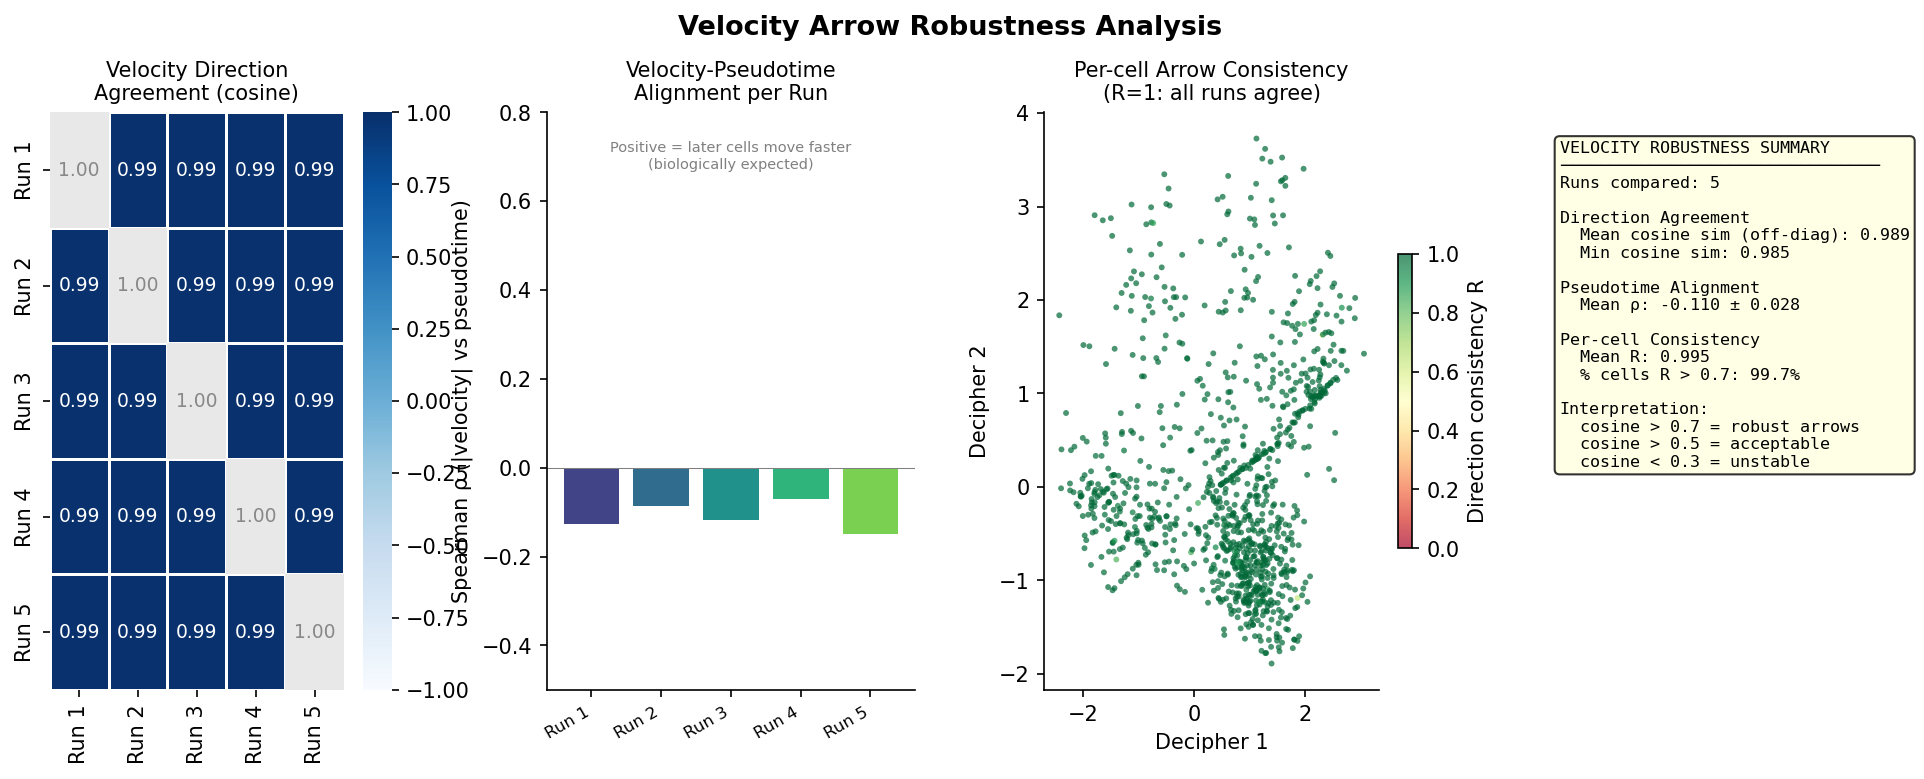


Velocity Robustness Results:
  mean_cosine_sim: 0.9888360977172852
  pseudo_vel_spearman: [np.float64(-0.1256955822494489), np.float64(-0.08611454322820122), np.float64(-0.11872180703975074), np.float64(-0.06997805582535216), np.float64(-0.1485166396929453)]
  per_cell_R_mean: 0.9951576590538025
  pct_consistent_cells: 0.9971014492753624


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

def velocity_robustness_analysis(
    run_vpreds: list,          # list of (N, G) velocity arrays, one per run
    pseudo_norm: np.ndarray,   # (N,) pseudotime 0-1
    V_dec2: np.ndarray,        # (N, 2) 2D embedding for visualization
    save_path: str = "bert_grn_out_61/velocity_robustness.png",
    k_smooth: int = 15,        # neighbors for smoothing before comparison
):
    """
    Parameters
    ----------
    run_vpreds : list of np.ndarray, each (N, G)
    pseudo_norm : (N,) pseudotime values
    V_dec2 : (N, 2) 2D coordinates for quiver plot
    """
    from sklearn.neighbors import NearestNeighbors

    N_runs = len(run_vpreds)
    N = run_vpreds[0].shape[0]

    # ── 1. Project each run's velocity to 2D using your existing project_to_2d ──
    print("Projecting all runs to 2D...")
    vpred_2d_list = []
    for vp in run_vpreds:
        v2d = project_to_2d(vp, V_dec2, X, k=12, scale=12.0)
        vpred_2d_list.append(v2d)

    # ── 2. Pairwise cosine similarity matrix (cell-averaged) ──────────────────
    # For each pair of runs, compute mean cosine sim of 2D velocity vectors
    cos_sim_mat = np.zeros((N_runs, N_runs))

    for i in range(N_runs):
        for j in range(N_runs):
            v_i = vpred_2d_list[i]    # (N, 2)
            v_j = vpred_2d_list[j]    # (N, 2)
            # Cosine similarity per cell
            norm_i = np.linalg.norm(v_i, axis=1, keepdims=True) + 1e-8
            norm_j = np.linalg.norm(v_j, axis=1, keepdims=True) + 1e-8
            cos_sim = (v_i / norm_i * v_j / norm_j).sum(axis=1)  # (N,)
            cos_sim_mat[i, j] = float(cos_sim.mean())

    # ── 3. Per-run pseudotime alignment ──────────────────────────────────────
    # Does velocity magnitude increase over pseudotime? (cells committing to fate
    # should have larger velocity). Compute Spearman between |v| and pseudotime.
    pseudo_vel_spearman = []
    for vp in run_vpreds:
        mag = np.linalg.norm(vp, axis=1)   # (N,) gene-space magnitude
        rho, _ = spearmanr(mag, pseudo_norm)
        pseudo_vel_spearman.append(rho)

    # ── 4. Direction consistency: per-cell std of angle across runs ───────────
    # For each cell, compute the circular std of the arrow angle across runs
    angles = np.array([np.arctan2(v2d[:, 1], v2d[:, 0]) for v2d in vpred_2d_list])
    # angles: (N_runs, N)
    # Circular mean direction per cell
    mean_sin = np.sin(angles).mean(axis=0)
    mean_cos = np.cos(angles).mean(axis=0)
    # Resultant length R ∈ [0,1]: R=1 means all runs agree on direction, R=0 = random
    R = np.sqrt(mean_sin**2 + mean_cos**2)   # (N,) per cell

    # ── 5. Plot ───────────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(16, 5), dpi=150)
    gs  = fig.add_gridspec(1, 4, wspace=0.35)

    # Panel A: inter-run cosine similarity heatmap
    ax0 = fig.add_subplot(gs[0])
    labels = [f"Run {i+1}" for i in range(N_runs)]
    mask = np.eye(N_runs, dtype=bool)
    sns.heatmap(
        cos_sim_mat, annot=True, fmt=".2f",
        xticklabels=labels, yticklabels=labels,
        cmap="Blues", vmin=-1, vmax=1,
        linewidths=0.5, ax=ax0, mask=mask,
        annot_kws={"size": 9},
    )
    for i in range(N_runs):
        ax0.add_patch(plt.Rectangle((i, i), 1, 1, fill=True, color='#e8e8e8', lw=0))
        ax0.text(i+0.5, i+0.5, "1.00", ha='center', va='center', fontsize=9, color='#888')
    ax0.set_title("Velocity Direction\nAgreement (cosine)", fontsize=10)

    # Panel B: per-run pseudotime alignment
    ax1 = fig.add_subplot(gs[1])
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, N_runs))
    ax1.bar(range(N_runs), pseudo_vel_spearman, color=colors)
    ax1.axhline(0, color='gray', lw=0.5)
    ax1.set_xticks(range(N_runs)); ax1.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    ax1.set_ylabel("Spearman ρ (|velocity| vs pseudotime)")
    ax1.set_title("Velocity-Pseudotime\nAlignment per Run", fontsize=10)
    ax1.set_ylim(-0.5, 0.8)
    # Interpret: positive ρ means faster-moving cells are later in pseudotime (committed)
    ax1.text(0.5, 0.95, "Positive = later cells move faster\n(biologically expected)",
             transform=ax1.transAxes, ha='center', va='top', fontsize=7, color='gray')
    ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)

    # Panel C: per-cell direction consistency (R) on 2D embedding
    ax2 = fig.add_subplot(gs[2])
    sc = ax2.scatter(V_dec2[:, 0], V_dec2[:, 1],
                     c=R, cmap='RdYlGn',
                     vmin=0, vmax=1, s=8, alpha=0.7, edgecolors='none', rasterized=True)
    plt.colorbar(sc, ax=ax2, fraction=0.04, label='Direction consistency R')
    ax2.set_title(f"Per-cell Arrow Consistency\n(R=1: all runs agree)", fontsize=10)
    ax2.set_xlabel("Decipher 1"); ax2.set_ylabel("Decipher 2")
    ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)

    # Panel D: summary statistics text panel
    ax3 = fig.add_subplot(gs[3])
    ax3.axis('off')
    off_diag = cos_sim_mat[~np.eye(N_runs, dtype=bool)]
    summary = (
        f"VELOCITY ROBUSTNESS SUMMARY\n"
        f"{'─'*32}\n"
        f"Runs compared: {N_runs}\n\n"
        f"Direction Agreement\n"
        f"  Mean cosine sim (off-diag): {off_diag.mean():.3f}\n"
        f"  Min cosine sim: {off_diag.min():.3f}\n\n"
        f"Pseudotime Alignment\n"
        f"  Mean ρ: {np.mean(pseudo_vel_spearman):.3f} ± {np.std(pseudo_vel_spearman):.3f}\n\n"
        f"Per-cell Consistency\n"
        f"  Mean R: {R.mean():.3f}\n"
        f"  % cells R > 0.7: {(R > 0.7).mean():.1%}\n\n"
        f"Interpretation:\n"
        f"  cosine > 0.7 = robust arrows\n"
        f"  cosine > 0.5 = acceptable\n"
        f"  cosine < 0.3 = unstable"
    )
    ax3.text(0.05, 0.95, summary, transform=ax3.transAxes,
             fontsize=8, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    plt.suptitle("Velocity Arrow Robustness Analysis", fontsize=13, fontweight='bold', y=1.01)
    plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

    return {
        "cos_sim_matrix":        cos_sim_mat,
        "mean_cosine_sim":       float(off_diag.mean()),
        "pseudo_vel_spearman":   pseudo_vel_spearman,
        "per_cell_R_mean":       float(R.mean()),
        "pct_consistent_cells":  float((R > 0.7).mean()),
    }


# ── Usage (requires NUM_RUNS > 1 in training cell) ────────────────────────
# Load all run velocities
run_vpreds = []
for i in range(NUM_RUNS):
    path = f"bert_grn_out_61/run{i}/V_pred.npy"
    run_vpreds.append(np.load(path))

vel_robustness = velocity_robustness_analysis(
    run_vpreds   = run_vpreds,
    pseudo_norm  = pseudo_norm,
    V_dec2       = V_dec2,
    save_path    = "bert_grn_out_61/velocity_robustness.png",
)

print("\nVelocity Robustness Results:")
for k, v in vel_robustness.items():
    if k != "cos_sim_matrix":
        print(f"  {k}: {v}")

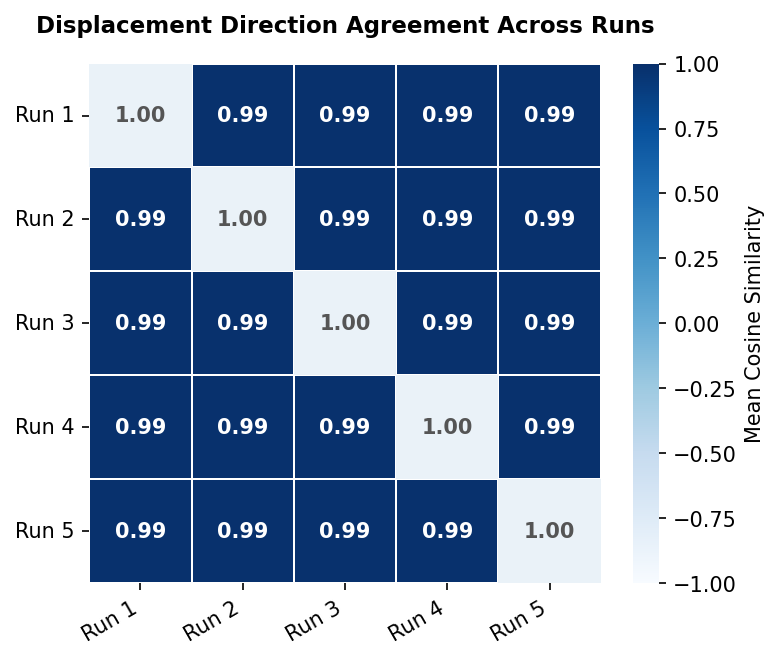

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_velocity_coherence_heatmap(cos_sim_mat, save_path=None):
    """
    Plots just the pairwise velocity direction agreement heatmap.
    """
    N_runs = cos_sim_mat.shape[0]
    labels = [f"Run {i+1}" for i in range(N_runs)]
    
    # Mask out the diagonal because we will format it manually
    mask = np.eye(N_runs, dtype=bool)

    fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=150)
    
    sns.heatmap(
        cos_sim_mat, 
        annot=True, 
        fmt=".2f",
        xticklabels=labels, 
        yticklabels=labels,
        cmap="Blues", 
        vmin=-1, 
        vmax=1,
        linewidths=0.75, 
        ax=ax, 
        mask=mask,
        annot_kws={"size": 10, "weight": "bold"},
        cbar_kws={"label": "Mean Cosine Similarity"}
    )
    
    # Beautifully restore the diagonal placeholders
    for i in range(N_runs):
        ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=True, color='#eaf2f8', lw=0))
        ax.text(i+0.5, i+0.5, "1.00", ha='center', va='center', fontsize=10, color='#555', weight='bold')
        
    ax.set_title("Displacement Direction Agreement Across Runs", fontsize=11, fontweight='bold', pad=15)
    plt.xticks(rotation=30, ha='right')
    plt.yticks(rotation=0)
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

# Usage:
plot_velocity_coherence_heatmap(vel_robustness["cos_sim_matrix"])

In [28]:
# ── 1. Ensure inputs are loaded ──
# (Assuming run_vpreds, V_dec2, and X are already defined in your notebook)

print(f"Starting 2D projection for {len(run_vpreds)} runs...")

vpred_2d_list = []

# ── 2. Loop through each run and project to 2D space ──
for i, vp in enumerate(run_vpreds):
    print(f"  Projecting Run {i+1}/{len(run_vpreds)}...")
    
    # Using the exact parameters from your original pipeline
    v2d = project_to_2d(
        vp, 
        V_dec2, 
        X, 
        k=12, 
        scale=12.0
    )
    vpred_2d_list.append(v2d)

print("🟢 All runs successfully projected to 2D! 'vpred_2d_list' is ready.")

Starting 2D projection for 5 runs...
  Projecting Run 1/5...
  Projecting Run 2/5...
  Projecting Run 3/5...
  Projecting Run 4/5...
  Projecting Run 5/5...
🟢 All runs successfully projected to 2D! 'vpred_2d_list' is ready.


Computing macro-gradient alignment using k=50...


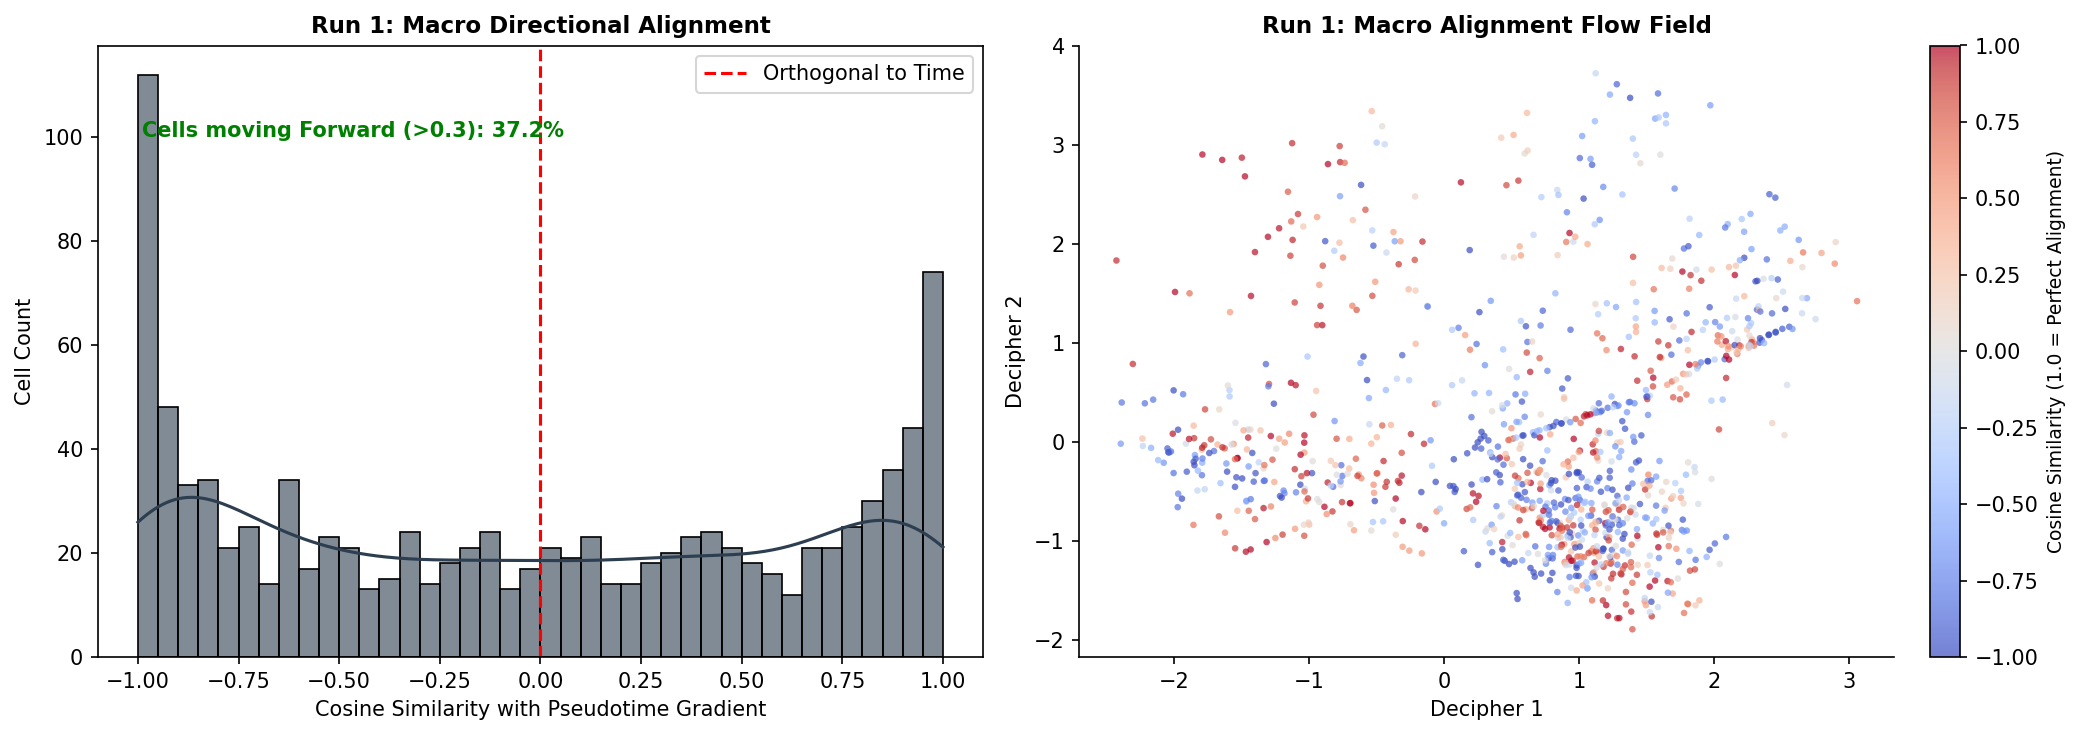

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LinearRegression

def compute_macro_gradient_alignment(v2d_vpreds, V_dec2, pseudo_norm, k_macro=120):
    """
    Computes macro-level alignment by fitting a local pseudotime gradient 
    over a large neighborhood and calculating pure cosine similarity.
    """
    print(f"Computing macro-gradient alignment using k={k_macro}...")
    
    # 1. Fit a large neighborhood to capture macro-trends, not micro-noise
    nn = NearestNeighbors(n_neighbors=k_macro).fit(V_dec2)
    _, indices = nn.kneighbors(V_dec2)
    
    all_runs_scores = []
    
    for run_idx, V_2d in enumerate(v2d_vpreds):
        scores = []
        for i in range(len(V_2d)):
            v_i = V_2d[i]
            v_norm = np.linalg.norm(v_i)
            
            if v_norm == 0:
                scores.append(0)
                continue
                
            # Get macro-neighbors for cell i
            nbr_idx = indices[i]
            X_nbrs = V_dec2[nbr_idx]      # (k_macro, 2) coordinates
            y_nbrs = pseudo_norm[nbr_idx]  # (k_macro,) pseudotimes
            
            # Fit a local plane: pseudotime = w1*Decipher1 + w2*Decipher2 + c
            # The coefficients (w1, w2) point exactly towards increasing pseudotime
            reg = LinearRegression().fit(X_nbrs, y_nbrs)
            grad_vector = reg.coef_ 
            grad_norm = np.linalg.norm(grad_vector)
            
            if grad_norm == 0:
                scores.append(0)
            else:
                # Calculate pure cosine similarity (-1 to 1)
                cos_sim = np.dot(v_i, grad_vector) / (v_norm * grad_norm)
                scores.append(cos_sim)
                
        all_runs_scores.append(np.array(scores))
        
    return all_runs_scores


def plot_macro_alignment_diagnostic(all_scores, V_dec2, run_idx=0):
    """
    Plots the macro-level alignment results.
    """
    scores = all_scores[run_idx]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
    
    # Panel 1: Distribution Histogram (Now bounded strictly between -1 and 1)
    sns.histplot(scores, bins=40, kde=True, ax=axes[0], color="#2c3e50", alpha=0.6)
    axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Orthogonal to Time")
    axes[0].set_title(f"Run {run_idx + 1}: Macro Directional Alignment", fontsize=11, fontweight='bold')
    axes[0].set_xlabel("Cosine Similarity with Pseudotime Gradient")
    axes[0].set_ylabel("Cell Count")
    axes[0].set_xlim(-1.1, 1.1)
    axes[0].legend()
    
    # Calculate macro summary stats
    pct_forward = (scores > 0.3).mean()
    axes[0].text(0.05, 0.85, f"Cells moving Forward (>0.3): {pct_forward:.1%}", 
                 transform=axes[0].transAxes, fontsize=10, weight='bold', color='green')
    
    # Panel 2: Spatial Feature Plot
    sc = axes[1].scatter(
        V_dec2[:, 0], V_dec2[:, 1], 
        c=scores, cmap="coolwarm", 
        vmin=-1, vmax=1, # Full scale assignment
        s=10, alpha=0.7, edgecolors='none', rasterized=True
    )
    cbar = plt.colorbar(sc, ax=axes[1], fraction=0.04, pad=0.04)
    cbar.set_label("Cosine Similarity (1.0 = Perfect Alignment)", fontsize=9)
    
    axes[1].set_title(f"Run {run_idx + 1}: Macro Alignment Flow Field", fontsize=11, fontweight='bold')
    axes[1].set_xlabel("Decipher 1")
    axes[1].set_ylabel("Decipher 2")
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()

# ── Run the Macro Analysis ──
# Using k_macro=120 to capture the global trajectory sweep
macro_scores = compute_macro_gradient_alignment(vpred_2d_list, V_dec2, pseudo_norm, k_macro=50)

# Plot the first run
plot_macro_alignment_diagnostic(macro_scores, V_dec2, run_idx=0)

Running mask sweep over fractions: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
Using 40 epochs per run (no velocity phase)

── Mask fraction = 10% ──
Clustering into 4 groups in Decipher space...
Cluster sizes: [213, 512, 195, 115]
GRN dictionary initialized from cluster LFC profiles.
Pre-training cell state encoder on cluster labels...
  Encoder pre-train epoch 0: CE=1.234
Encoder pre-training complete.
  recon_mse=28611.5371  diversity=1.189  pseudo_rho=0.170  co_rho=nan
── Mask fraction = 20% ──
Clustering into 4 groups in Decipher space...
Cluster sizes: [213, 512, 195, 115]
GRN dictionary initialized from cluster LFC profiles.
Pre-training cell state encoder on cluster labels...
  Encoder pre-train epoch 0: CE=1.156
Encoder pre-training complete.
  recon_mse=28285.4258  diversity=1.166  pseudo_rho=0.170  co_rho=nan
── Mask fraction = 30% ──
Clustering into 4 groups in Decipher space...
Cluster sizes: [213, 512, 195, 115]
GRN dictionary initialized from cluster LFC profiles.
Pre-training c

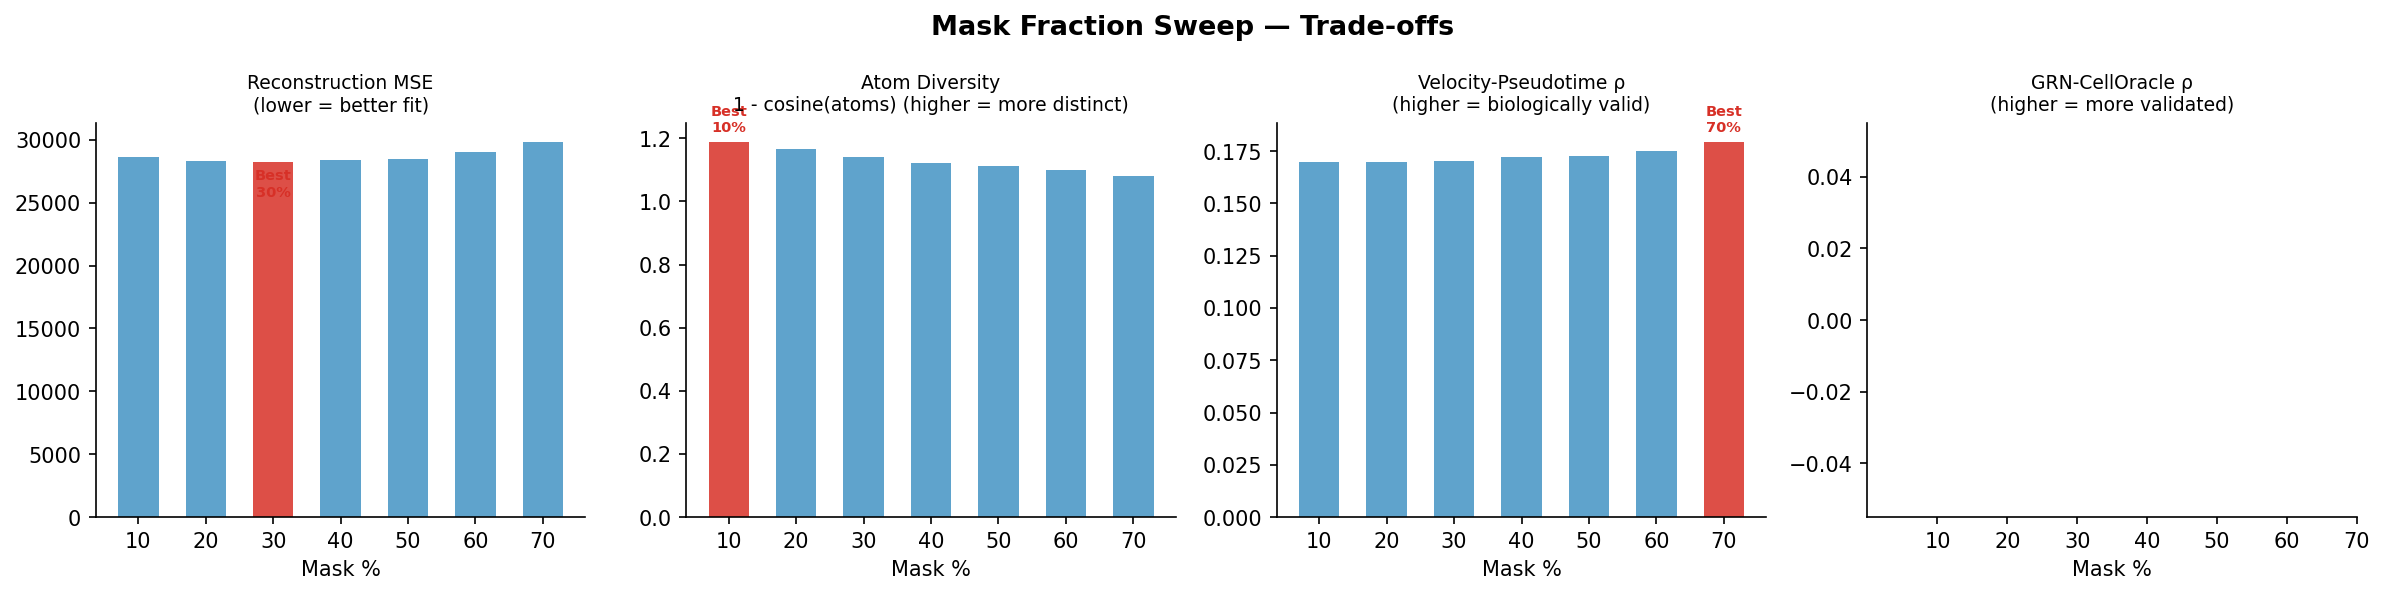


Full sweep table:
 mask_frac    recon_mse  atom_diversity  pseudo_rho  grn_co_rho  final_mask_loss
       0.1 28611.537109        1.189131    0.169710         NaN     27206.251367
       0.2 28285.425781        1.166117    0.169661         NaN     28543.739453
       0.3 28247.966797        1.142202    0.170098         NaN     29413.004102
       0.4 28369.109375        1.123376    0.171997         NaN     29432.663281
       0.5 28485.966797        1.111133    0.172712         NaN     29901.325781
       0.6 29066.001953        1.098919    0.175143         NaN     29723.194336
       0.7 29848.183594        1.081696    0.179487         NaN     30229.244141

Recommended mask fraction (best overall rank): 30%


In [35]:
# ═══════════════════════════════════════════════════════════════════════════
# MASK PERCENTAGE SWEEP — find optimal masking fraction
# ═══════════════════════════════════════════════════════════════════════════
#
# We train the GRN from scratch at each mask fraction and compare:
#   1. Reconstruction loss (lower = better fit)
#   2. GRN-CellOracle Spearman correlation (higher = more biologically valid)
#   3. Atom diversity (higher = atoms are more distinct)
#   4. Velocity-pseudotime alignment (higher = biologically sensible)
#
# Quick sweep: fewer epochs than full training (40 total, no velocity phase)
# to keep runtime manageable. The relative ranking should still hold.
# ═══════════════════════════════════════════════════════════════════════════

MASK_FRACS     = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
SWEEP_EPOCHS   = 40    # fewer than full training; enough to see relative quality
SWEEP_BATCH    = 512

sweep_results = []

print(f"Running mask sweep over fractions: {MASK_FRACS}")
print(f"Using {SWEEP_EPOCHS} epochs per run (no velocity phase)\n")

for mask_frac in MASK_FRACS:
    print(f"── Mask fraction = {mask_frac:.0%} ──")

    # Fresh model
    grn_sw   = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn_sw.TF_access = TF_access_t.clone()
    grn_sw.mean_tf   = torch.tensor(X_TF.mean(axis=0), dtype=torch.float32)
    enc_sw   = CellStateEncoder(G=G, D=D_ATOMS)
    ld_sw    = LinearDecoder(hidden=64, G=G, ld_dim=2)

    cluster_labels_sw, W_init_sw = initialize_grn_dictionary_from_clusters(
        X=X, V_dec2=V_dec2, M=M, D=D_ATOMS, A_tfs=A_tfs, sub_g2i=sub_g2i
    )
    grn_sw.init_from_clusters(W_init_sw)
    enc_sw.init_from_cluster_labels(X, cluster_labels_sw, n_epochs=10)

    opt_sw = torch.optim.AdamW(
        list(grn_sw.parameters()) + list(enc_sw.parameters()) + list(ld_sw.parameters()),
        lr=5e-4
    )

    loader_sw = DataLoader(
        TensorDataset(X_t, X_TF_t, cell_idx_t),
        batch_size=SWEEP_BATCH,
        sampler=RandomSampler(TensorDataset(X_t, X_TF_t, cell_idx_t), replacement=False),
        drop_last=True
    )

    # Train
    final_losses = []
    for epoch in range(SWEEP_EPOCHS):
        temp = max(0.1, 0.5 - 0.4 * epoch / SWEEP_EPOCHS)
        grn_sw.train(); enc_sw.train()
        for rna_b, tf_b, bidx in loader_sw:
            mw = enc_sw(rna_b, temperature=temp)
            l_mask    = masked_reconstruction_loss(grn_sw, mw, rna_b, tf_b,
                                                   tf_indices_in_G.to(rna_b.device),
                                                   mask_frac=mask_frac)
            l_sparse  = grn_sw.sparsity_loss()
            l_diverse = grn_sw.diversity_loss()
            H = -torch.sum(mw * torch.log(mw + 1e-8), dim=-1).mean()
            loss = 2.0 * l_mask + 5e-3 * l_sparse + 10.0 * l_diverse + H / np.log(D_ATOMS)
            opt_sw.zero_grad(); loss.backward(); opt_sw.step()
            if epoch >= SWEEP_EPOCHS - 5:
                final_losses.append(float(l_mask.item()))

    # Evaluate
    grn_sw.eval(); enc_sw.eval()
    with torch.no_grad():
        mw_all = enc_sw(X_t, temperature=0.1)
        ss_all = grn_sw.predict_rna(X_TF_t, mw_all)

        # 1. Reconstruction MSE on UNMASKED data (full)
        recon_mse = float(F.mse_loss(ss_all, X_t).item())

        # 2. Atom diversity: average pairwise cosine distance between atoms
        A_d = grn_sw.A_dict.detach().cpu().numpy()   # (D, G, T)
        flat = A_d.reshape(D_ATOMS, -1)
        norms = np.linalg.norm(flat, axis=1, keepdims=True) + 1e-8
        flat_n = flat / norms
        cos_mat = flat_n @ flat_n.T
        off_diag = cos_mat[~np.eye(D_ATOMS, dtype=bool)]
        mean_cos_dist = 1.0 - float(off_diag.mean())   # higher = more diverse atoms

        # 3. Velocity-pseudotime alignment (gene-space velocity proxy)
        # Use steady-state deviation as a velocity proxy for speed
        diseq = (ss_all - X_t).cpu().numpy()
        mag   = np.linalg.norm(diseq, axis=1)
        rho_pseudo, _ = spearmanr(mag, pseudo_norm)

        # 4. GRN-CellOracle alignment (if co_A available)
        try:
            A_learned_sw = grn_sw.get_effective_A(mw_all.mean(dim=0)).cpu().numpy()
            # Restrict to shared subspace
            sw_pred_g = np.array([pred_g2i[g] for g in common_genes if g in pred_g2i])
            sw_pred_t = np.array([pred_t2i[t] for t in common_tfs if t in pred_t2i])
            A_pred_sw = A_learned_sw[np.ix_(sw_pred_g, sw_pred_t)]
            rho_co, _ = spearmanr(A_pred_sw.ravel(), A_co_shared.ravel())
        except Exception:
            rho_co = float('nan')

    result = {
        "mask_frac":    mask_frac,
        "recon_mse":    recon_mse,
        "atom_diversity": mean_cos_dist,
        "pseudo_rho":   float(rho_pseudo),
        "grn_co_rho":   float(rho_co),
        "final_mask_loss": float(np.mean(final_losses)),
    }
    sweep_results.append(result)
    print(f"  recon_mse={recon_mse:.4f}  diversity={mean_cos_dist:.3f}  "
          f"pseudo_rho={rho_pseudo:.3f}  co_rho={rho_co:.3f}")

# ── Plot sweep results ────────────────────────────────────────────────────
import pandas as pd

df_sweep = pd.DataFrame(sweep_results)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)

metrics = [
    ("recon_mse",      "Reconstruction MSE\n(lower = better fit)", False),
    ("atom_diversity", "Atom Diversity\n1 - cosine(atoms) (higher = more distinct)", True),
    ("pseudo_rho",     "Velocity-Pseudotime ρ\n(higher = biologically valid)", True),
    ("grn_co_rho",     "GRN-CellOracle ρ\n(higher = more validated)", True),
]

for ax, (col, title, higher_is_better) in zip(axes, metrics):
    vals = df_sweep[col].values
    fracs = df_sweep["mask_frac"].values * 100

    best_idx = np.argmin(vals) if not higher_is_better else np.argmax(vals)
    colors = ['#d73027' if i == best_idx else '#4393c3' for i in range(len(vals))]

    ax.bar(fracs, vals, width=6, color=colors, alpha=0.85)
    ax.set_xlabel("Mask %"); ax.set_title(title, fontsize=9)
    ax.set_xticks(fracs)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    # Annotate best
    ax.text(fracs[best_idx], vals[best_idx] * (1.02 if higher_is_better else 0.98),
            f"Best\n{fracs[best_idx]:.0f}%",
            ha='center', fontsize=7, color='#d73027', fontweight='bold',
            va='bottom' if higher_is_better else 'top')

plt.suptitle("Mask Fraction Sweep — Trade-offs", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("bert_grn_out_518/mask_sweep.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nFull sweep table:")
print(df_sweep.to_string(index=False))

# Find the best overall mask fraction (simple ranking sum)
ranks = pd.DataFrame({
    "mask_frac": df_sweep["mask_frac"],
    "recon_rank":   df_sweep["recon_mse"].rank(ascending=True),
    "div_rank":     df_sweep["atom_diversity"].rank(ascending=False),
    "pseudo_rank":  df_sweep["pseudo_rho"].rank(ascending=False),
    "co_rank":      df_sweep["grn_co_rho"].rank(ascending=False),
})
ranks["total_rank"] = ranks[["recon_rank","div_rank","pseudo_rank","co_rank"]].sum(axis=1)
best_frac = ranks.loc[ranks["total_rank"].idxmin(), "mask_frac"]
print(f"\nRecommended mask fraction (best overall rank): {best_frac:.0%}")

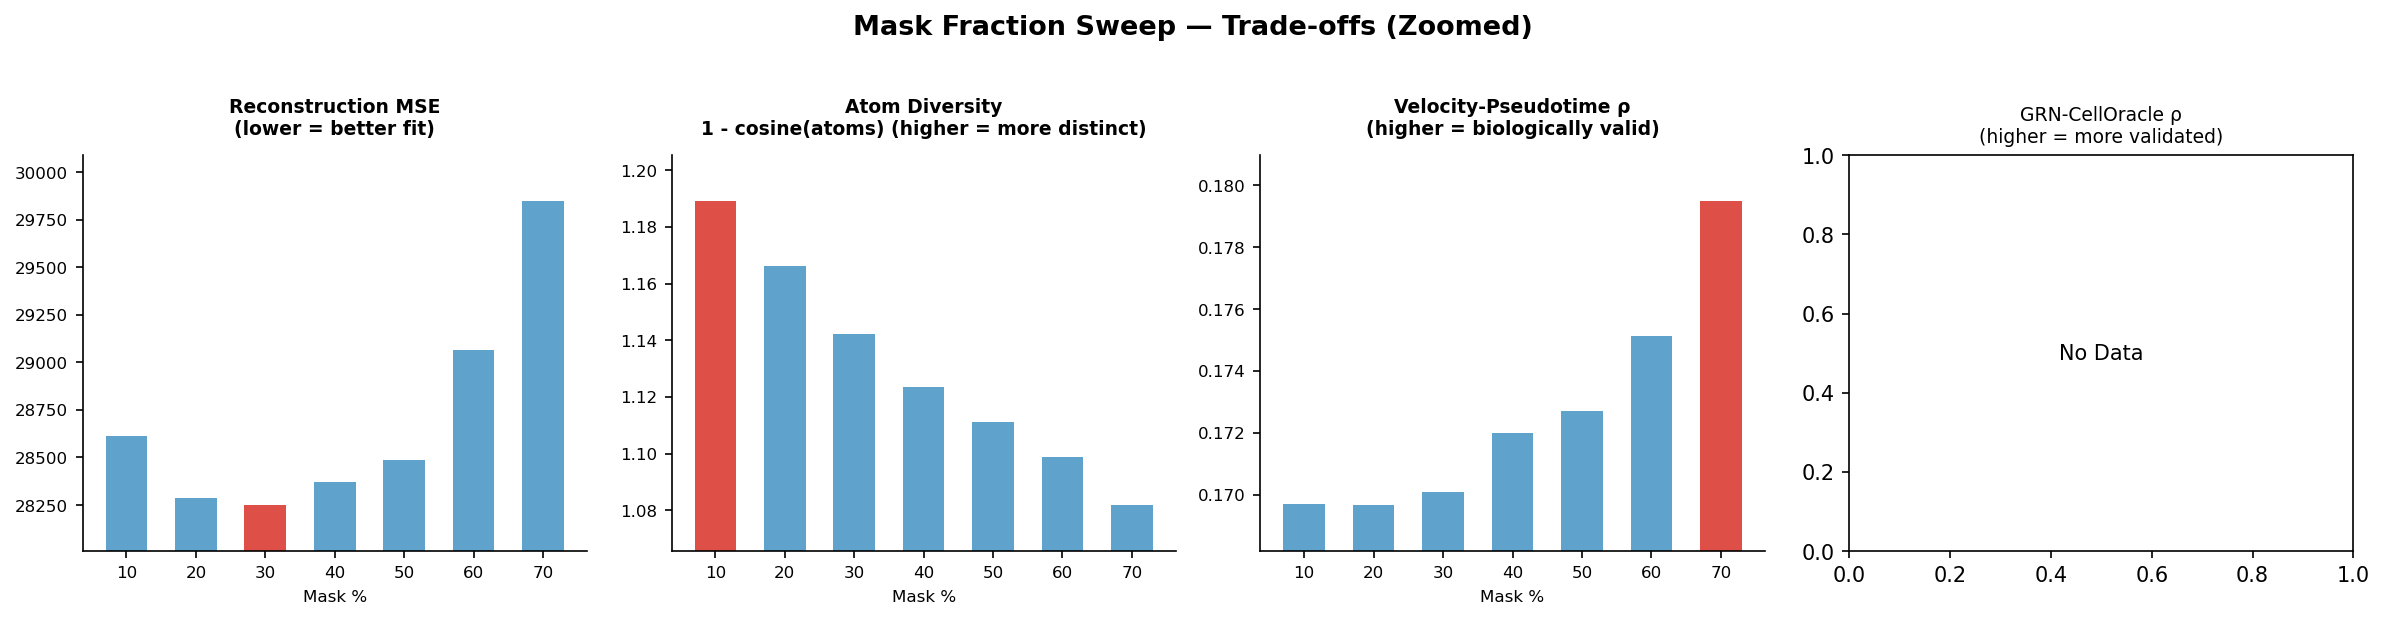

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_sweep = pd.DataFrame(sweep_results)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)

metrics = [
    ("recon_mse",      "Reconstruction MSE\n(lower = better fit)", False),
    ("atom_diversity", "Atom Diversity\n1 - cosine(atoms) (higher = more distinct)", True),
    ("pseudo_rho",     "Velocity-Pseudotime ρ\n(higher = biologically valid)", True),
    ("grn_co_rho",     "GRN-CellOracle ρ\n(higher = more validated)", True),
]

for ax, (col, title, higher_is_better) in zip(axes, metrics):
    vals = df_sweep[col].values
    fracs = df_sweep["mask_frac"].values * 100

    # Clean array from NaNs to find best index and axis limits safely
    valid_mask = ~np.isnan(vals)
    
    if not np.any(valid_mask):
        # Fallback if an entire metric failed and contains only NaNs
        ax.text(0.5, 0.5, "No Data", ha='center', va='center')
        ax.set_title(title, fontsize=9)
        continue
        
    best_idx = np.nanargmin(vals) if not higher_is_better else np.nanargmax(vals)
    colors = ['#d73027' if i == best_idx else '#4393c3' for i in range(len(vals))]

    # Calculate dynamic y-limits using ONLY valid, non-NaN numbers
    v_min, v_max = np.nanmin(vals), np.nanmax(vals)
    v_range = v_max - v_min if v_max != v_min else 1e-4
    
    y_min = v_min - 0.15 * v_range
    y_max = v_max + 0.15 * v_range
    
    # Draw standard bars
    ax.bar(fracs, vals, width=6, color=colors, alpha=0.85)
    
    # Securely set cropped y-limits without passing NaN values
    ax.set_ylim(y_min, y_max)
    
    ax.set_xlabel("Mask %", fontsize=8)
    ax.set_title(title, fontsize=9, fontweight='bold', pad=10)
    ax.set_xticks(fracs)
    ax.tick_params(axis='both', labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle("Mask Fraction Sweep — Trade-offs (Zoomed)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("bert_grn_out_518/mask_sweep_zoomed.png", dpi=150, bbox_inches='tight')
plt.show()